                                                Universidad de Antioquia

                                      Fundamentos en Procesamiento del Lenguaje Natural

---

Hecho por: Santiago Trespalacios Bolivar

GitHub: www.github.com/s4nt14g0v

Linkedin: www.linkedin.com/in/santiago-trespalacios-bolivar/

---

# 1. Instalación, configuración y funciones auxiliares

### 1.1 Instalación

> **Antes de ejecutar:** en Colab entrar a *Entorno de ejecución → Cambiar tipo de entorno de ejecución* y seleccionar **GPU T4**. Sin GPU el entrenamiento tardaría horas.

Instalamos/actualizamos las librerías necesarias:

- `transformers`: modelos preentrenados y la clase `Trainer` que automatiza el ciclo de entrenamiento.
- `datasets`: descarga y procesamiento eficiente de los datasets del Hub de Hugging Face.
- `accelerate`: necesario para que `Trainer` use la GPU de forma óptima.
- `seqeval` (métricas de NER), `sacrebleu` (métricas de traducción) y `sentencepiece` (tokenizador de MarianMT).

In [1]:
import os
if "COLAB_RELEASE_TAG" in os.environ:   # solo en Colab
    import importlib.metadata as md
    with open("/tmp/fijar.txt", "w") as f:   # mantiene las versiones de Colab
        for p in ["torch", "torchvision", "torchaudio"]:
            try: f.write(f"{p}=={md.version(p)}\n")
            except md.PackageNotFoundError: pass
    !pip install -q -U transformers datasets accelerate scikit-learn seqeval sacrebleu sentencepiece -c /tmp/fijar.txt

Importamos las librerías y verificamos la GPU. Fijamos una **semilla aleatoria** (`SEED`) para que los resultados sean reproducibles: con la misma semilla, la inicialización de la cabeza del modelo y el orden de los datos son siempre iguales.

In [7]:
import os, gc, json, time, shutil, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import transformers
import datasets
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    pipeline,
    set_seed,
)
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from transformers import AutoModelForTokenClassification, DataCollatorForTokenClassification
from seqeval.metrics import (classification_report as seqeval_report, accuracy_score as seqeval_accuracy,
                             precision_score as seqeval_precision, recall_score as seqeval_recall,
                             f1_score as seqeval_f1)
from collections import Counter, defaultdict

from transformers import (AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq,
                          Seq2SeqTrainingArguments, Seq2SeqTrainer)
from sklearn.model_selection import train_test_split
import sacrebleu

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()   # oculta avisos internos poco útiles
datasets.logging.set_verbosity_error()
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

SEED = 42
set_seed(SEED)

print(f"PyTorch      {torch.__version__}")
print(f"Transformers {transformers.__version__}")
print(f"Datasets     {datasets.__version__}")
if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    print(f"GPU | {gpu.name} ({gpu.total_memory / 1024**3:.1f} GB)")
else:
    print("GPU | No disponible: el entrenamiento será muy lento")

PyTorch      2.14.1+cu130
Transformers 5.23.0
Datasets     5.2.0
GPU | Tesla T4 (14.6 GB)


### 1.2 Configuración general

- **`USE_DRIVE`**: Guarda resultados y modelos en Google Drive. Las sesiones gratuitas de Colab se cortan tras unas horas o por inactividad; si eso pasa, lo guardado en Drive no se pierde y la búsqueda de hiperparámetros continúa donde quedó en vez de empezar de nuevo.
- **`MODO_PRUEBA`**: Si es `True`, todo se ejecuta con muestras diminutas y 1 época (2-3 minutos por parte). Sirve para comprobar que el notebook funciona de principio a fin antes de lanzar los entrenamientos largos. Para los resultados reales debe estar en `False`.

In [3]:
USE_DRIVE   = True
MODO_PRUEBA = False

In [4]:
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and USE_DRIVE:
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/NLP_Proyecto2"
else:
    BASE_DIR = "./nlp_proyecto2"
if MODO_PRUEBA:
    BASE_DIR += "_prueba" # los resultados de prueba no se mezclan con los reales

os.makedirs(BASE_DIR, exist_ok=True)

print("Carpeta de trabajo:", BASE_DIR, "| Modo prueba:", MODO_PRUEBA)

Mounted at /content/drive
Carpeta de trabajo: /content/drive/MyDrive/NLP_Proyecto2 | Modo prueba: False


In [5]:
FP16 = torch.cuda.is_available()   # precisión mixta: ~2x más rápido y menos memoria en GPU T4
RUTA_RESULTADOS = os.path.join(BASE_DIR, "resultados_finales.json")

### 1.3 Funciones Auxiliares

Con el fin de optimizar el tiempo de los entrenamientos entre cada parte o base de datos, se tienen funciones que ayudar a esa laborar para guardar resultados, liberar memoria y más cosas que agregan valor.

In [6]:
def liberar_memoria():
    """Libera la memoria de la GPU entre entrenamientos (evita errores 'CUDA out of memory')."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def guardar_resultado(clave, valores):
    """Agrega/actualiza los resultados finales de un problema en un JSON compartido."""
    resultados = {}
    if os.path.exists(RUTA_RESULTADOS):
        with open(RUTA_RESULTADOS) as f:
            resultados = json.load(f)
    resultados[clave] = valores
    with open(RUTA_RESULTADOS, "w") as f:
        json.dump(resultados, f, indent=2, ensure_ascii=False)


def cargar_busqueda(ruta_csv, ruta_hist):
    """Carga los resultados de una búsqueda de hiperparámetros previa (si existe) para reanudarla."""
    filas = pd.read_csv(ruta_csv).to_dict("records") if os.path.exists(ruta_csv) else []
    historiales = {}
    if os.path.exists(ruta_hist):
        with open(ruta_hist) as f:
            historiales = json.load(f)
    return filas, historiales


def guardar_busqueda(filas, historiales, ruta_csv, ruta_hist):
    pd.DataFrame(filas).to_csv(ruta_csv, index=False)
    with open(ruta_hist, "w") as f:
        json.dump(historiales, f)


def curvas_desde_historial(log_history):
    """Separa el historial del Trainer en pérdidas de entrenamiento y métricas de validación."""
    hist = pd.DataFrame(log_history)
    train = hist[hist["loss"].notna()][["epoch", "loss"]] if "loss" in hist else pd.DataFrame(columns=["epoch", "loss"])
    evals = hist[hist["eval_loss"].notna()].dropna(axis=1, how="all") if "eval_loss" in hist else pd.DataFrame(columns=["epoch", "eval_loss"])
    return train, evals

# 2. Dataset 1 - Detección de emociones en tweets

### 2.1 Descripción del dataset

El primer problema es de **clasificación de secuencias**: el modelo lee un texto completo y le asigna una sola etiqueta. En este caso, dado un tweet en inglés, debe decidir cuál de 6 emociones expresa.

Para resolverlo se hace fine-tuning de `bert-base-uncased`, un modelo tipo encoder preentrenado por Google. BERT lee todo el tweet a la vez y resume su significado en el vector del token especial `[CLS]`. Sobre ese vector se agrega una capa de clasificación con 6 salidas, una por emoción.

| Aspecto | Descripción |
|---|---|
| Nombre | Emotion (CARER), disponible en Hugging Face como `dair-ai/emotion` |
| Origen | Saravia et al. (2018), "CARER: Contextualized Affect Representations for Emotion Recognition", EMNLP |
| Dominio | Redes sociales: tweets en inglés donde las personas expresan cómo se sienten |
| Etiquetado | Supervisión distante: los tweets se recolectaron por hashtags de emoción (#sad, #angry...) y esos hashtags se usaron como etiqueta |
| Entrada | Un texto corto en inglés, en minúsculas y sin puntuación. Ej: "i feel like i am still looking at a blank canvas" |
| Salida | Una de 6 emociones: sadness, joy, love, anger, fear, surprise |
| Tipo de problema | Clasificación de secuencias multiclase (una etiqueta por texto) |
| Tamaño | 16.000 tweets de entrenamiento, 2.000 de validación y 2.000 de prueba |

Detectar emociones automáticamente es útil en atención al cliente (priorizar mensajes con enojo), en análisis de marca (saber qué sienten los clientes, no solo si opinan bien o mal) y en moderación de contenido. Es un problema más rico que el análisis de sentimiento positivo/negativo, porque distingue matices como joy frente a love o fear frente a surprise.

### 2.2 Carga del dataset

In [8]:
P1_MODEL = "bert-base-uncased" # Pretrained model on English language using a masked language modeling (MLM) objective. https://huggingface.co/google-bert/bert-base-uncased

P1_DIR = os.path.join(BASE_DIR, "p1_emotion")
os.makedirs(P1_DIR, exist_ok=True)

emotion = load_dataset("dair-ai/emotion", "split")

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [9]:
print(emotion)
print("\nEsquema de las columnas:", emotion["train"].features)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Esquema de las columnas: {'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}


### 2.3 Análisis exploratorio

In [10]:
label_names = emotion["train"].features["label"].names # ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

id2label = {i: nombre for i, nombre in enumerate(label_names)}
label2id = {nombre: i for i, nombre in id2label.items()}

print("id2label:", id2label)

# Versiones en pandas para el análisis exploratorio
df_p1 = {}
for split in emotion:
    df = emotion[split].to_pandas()
    df["emotion"] = df["label"].map(id2label)
    df_p1[split] = df
df_train_p1 = df_p1["train"]


id2label: {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}


Viendo dos tweets por clase para poder analizar el problema

In [11]:
display(df_train_p1.groupby("emotion").sample(2, random_state=SEED)[["text", "emotion"]])

,text,emotion
15428,i ve been feeling a bit cranky with the kids this week cranky baby whiny year old demanding preschooler so i wanted to stop and remember how blessed i really am,anger
4989,i feel frustrated sometimes with my mac lipsticks when i have to read names or open each of them to select shade,anger
15363,im standing by myself off near maxs crib watching the whole thing and feeling more terrified,fear
11517,i have to admit i feel a little hesitant about embedding a music video below in this case,fear
3360,i want to be in the future years some of you made me feel amazing and some of you are the best friends i could ever ask for,joy
14013,i do not feel glamourous,joy
5083,i feel absolutely loved,love
7839,im already feeling very loved today and its not even noon,love
8292,i feel so disappointed,sadness
8264,im not sure why today i feel so horrible,sadness


In [12]:
proporcion_feel = df_train_p1["text"].str.contains(r"\bfeel", regex=True).mean()
print(f"Tweets que contienen 'feel/feeling': {proporcion_feel:.1%}")

Tweets que contienen 'feel/feeling': 98.7%


**Observaciones:**

- Los textos están en minúsculas y sin puntuación: ya vienen preprocesados.
- Casi todos los tweets contienen la expresión **"i feel ..."** / **"feeling"**. Esto se debe a cómo se recolectó el dataset. La emoción no la indica la palabra "feel", sino lo que viene después.
- Algunas clases son difíciles de separar incluso para una persona (*joy* frente a *love*).

#### **Distribución de clases**

Es clave saber si las clases están balanceadas, porque si una clase domina, un modelo podría obtener buena *accuracy* simplemente prediciéndola siempre.

,train,validation,test,train (%),validation (%),test (%)
emotion,,,,,,
joy,5362,704,695,33.5,35.2,34.8
sadness,4666,550,581,29.2,27.5,29.0
anger,2159,275,275,13.5,13.8,13.8
fear,1937,212,224,12.1,10.6,11.2
love,1304,178,159,8.2,8.9,8.0
surprise,572,81,66,3.6,4.0,3.3


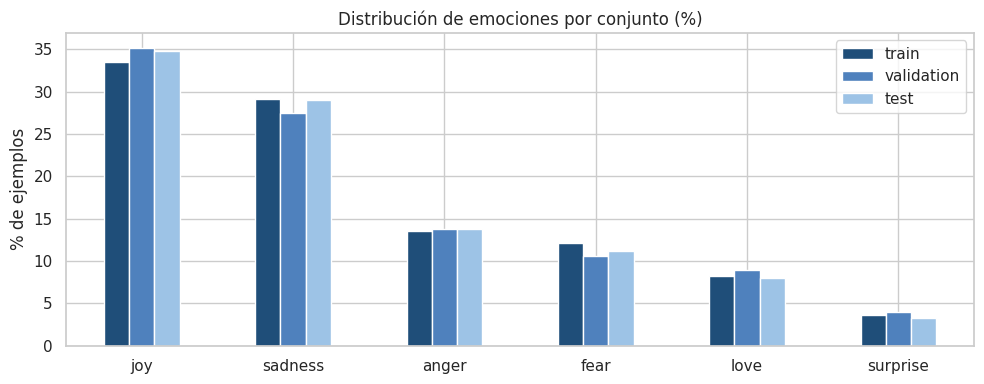

La clase mayoritaria tiene 9.4 veces más ejemplos que la minoritaria.


In [13]:
orden = df_train_p1["emotion"].value_counts().index
conteo = pd.DataFrame({split: df["emotion"].value_counts() for split, df in df_p1.items()}).loc[orden]
porcentaje = (conteo / conteo.sum() * 100).round(1)
display(pd.concat([conteo, porcentaje.add_suffix(" (%)")], axis=1))

ax = porcentaje.plot(kind="bar", figsize=(10, 4), rot=0, color=["#1f4e79", "#4f81bd", "#9dc3e6"])
ax.set_title("Distribución de emociones por conjunto (%)")
ax.set_ylabel("% de ejemplos"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

ratio = conteo["train"].max() / conteo["train"].min()
print(f"La clase mayoritaria tiene {ratio:.1f} veces más ejemplos que la minoritaria.")

**Observaciones:**

- El dataset está **desbalanceado**: *alegría* y *tristeza* concentran más del 60% de los ejemplos, mientras que *sorpresa* tiene 3-4 %.
- Los tres conjuntos tienen **la misma distribución**, así que la validación y el test son representativos del entrenamiento.
- **Consecuencia para la evaluación:** no basta con la *accuracy*. Se debe usar el **F1-macro**, que promedia el F1 de cada clase dando el mismo peso a todas. Así, fallar siempre en *sorpresa* se castiga aunque sea una clase pequeña.

#### Longitud de los textos

,count,mean,std,min,25%,50%,75%,max
palabras por tuit,16000.0,19.2,11.0,2.0,11.0,17.0,25.0,66.0


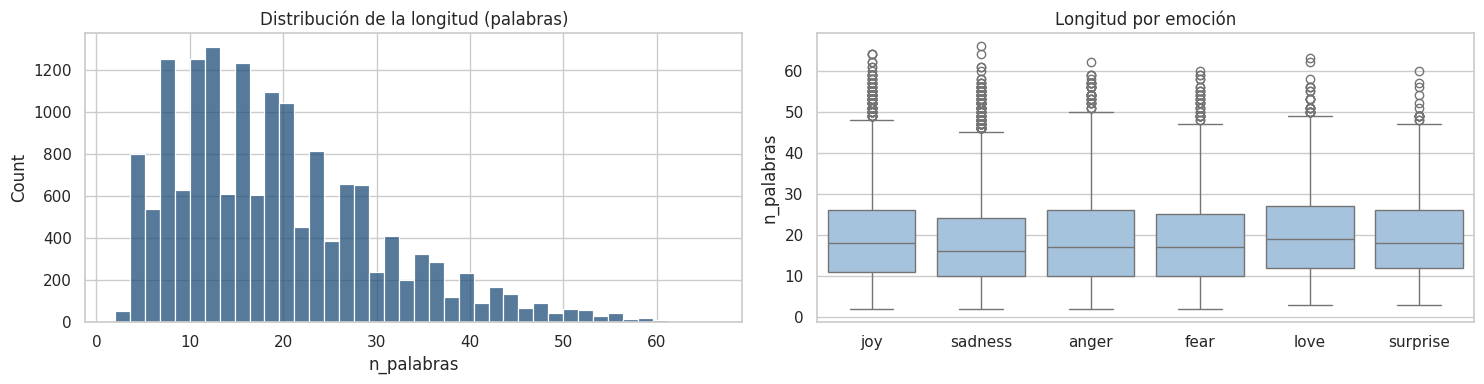

In [14]:
df_train_p1["n_palabras"] = df_train_p1["text"].str.split().str.len()
display(df_train_p1["n_palabras"].describe().round(1).to_frame("palabras por tuit").T)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(df_train_p1["n_palabras"], bins=40, ax=axes[0], color="#1f4e79")
axes[0].set_title("Distribución de la longitud (palabras)")
sns.boxplot(data=df_train_p1, x="emotion", y="n_palabras", order=orden, ax=axes[1], color="#9dc3e6")
axes[1].set_title("Longitud por emoción"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Observaciones:**

Los textos son **cortos**: la mayoría tiene entre 10 y 25 palabras, y la longitud es similar en todas las emociones. Por tanto, la longitud no sirve como pista para clasificar. Que sean cortos es una ventaja práctica: entrenar es rápido y podemos probar muchas combinaciones de hiperparámetros.

#### Palabras más características de cada emoción

Contar las palabras más frecuentes de cada clase no ayuda mucho: en todas ganan palabras genéricas como *time*, *want* o *people*. En su lugar usamos **c-TF-IDF** (TF-IDF por clase): unimos todos los tweets de una emoción en un solo "documento" y aplicamos TF-IDF sobre esos 6 documentos. Así una palabra puntúa alto si es frecuente en **su** emoción y rara en las demás.

In [15]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS

# binary=True: cuenta si la palabra APARECE en el tuit (1) o no (0), sin importar cuántas veces
cv = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS), binary=True)
X = cv.fit_transform(df_train_p1["text"])           # matriz tweets × palabras (0/1)
vocabulario = cv.get_feature_names_out()

# % de tweets (de todo el dataset) que contienen cada palabra
frecuencia = pd.DataFrame({"palabra": vocabulario,
                           "% tweets": np.asarray(X.mean(axis=0)).ravel() * 100})

# % de tweets de CADA emoción que contienen cada palabra
for emo in orden:
    mascara = (df_train_p1["emotion"] == emo).values
    frecuencia[emo] = np.asarray(X[mascara].mean(axis=0)).ravel() * 100

# Qué tan desigual es su uso entre emociones: clase donde más aparece / clase donde menos aparece
# (clip evita dividir entre 0 si una palabra no aparece en alguna emoción)
frecuencia["mayor/menor clase"] = frecuencia[list(orden)].max(axis=1) / frecuencia[list(orden)].min(axis=1).clip(lower=0.01)

frecuencia = frecuencia.sort_values("% tweets", ascending=False).reset_index(drop=True)
display(frecuencia.head(20).round(1))

,palabra,% tweets,joy,sadness,anger,fear,love,surprise,mayor/menor clase
0,feel,66.4,69.8,66.9,63.5,59.7,68.0,60.7,1.2
1,feeling,31.0,27.9,31.5,32.2,37.4,28.2,35.5,1.3
2,like,16.7,17.3,17.0,16.7,12.0,21.2,13.6,1.8
3,im,13.5,13.4,12.9,13.9,14.8,13.0,13.6,1.1
4,just,8.3,7.7,8.7,9.5,8.6,6.7,9.1,1.4
5,really,5.5,5.4,5.4,5.3,4.9,6.4,6.5,1.3
6,know,5.1,4.2,5.6,5.2,5.9,5.8,4.7,1.4
7,time,4.7,5.0,4.1,5.2,4.2,4.9,6.1,1.5
8,little,4.4,3.3,3.9,4.7,7.4,3.9,7.2,2.2
9,people,3.9,3.4,3.5,4.7,4.3,4.1,5.1,1.5


Se sacan las Stop Words del idioma Ingles y además se tienen en cuenta las palabras que son muy frecuentes y repartidas casi igual en las 6 emociones. Que por consecuente no ayudan a distinguir una emoción de otra.

In [16]:
UMBRAL_FRECUENCIA = 5.0   # aparece en más del 5 % de los tweets → es muy común
UMBRAL_REPARTO    = 2.0   # la emoción donde más aparece la usa menos del doble que donde menos → no distingue

no_informativas = frecuencia[
    (frecuencia["% tweets"] > UMBRAL_FRECUENCIA) &
    (frecuencia["mayor/menor clase"] < UMBRAL_REPARTO)
]
display(no_informativas.round(1))

stop_words = list(ENGLISH_STOP_WORDS | set(no_informativas["palabra"]))
print(f"Palabras excluidas por la regla: {sorted(no_informativas['palabra'])}")

,palabra,% tweets,joy,sadness,anger,fear,love,surprise,mayor/menor clase
0,feel,66.4,69.8,66.9,63.5,59.7,68.0,60.7,1.2
1,feeling,31.0,27.9,31.5,32.2,37.4,28.2,35.5,1.3
2,like,16.7,17.3,17.0,16.7,12.0,21.2,13.6,1.8
3,im,13.5,13.4,12.9,13.9,14.8,13.0,13.6,1.1
4,just,8.3,7.7,8.7,9.5,8.6,6.7,9.1,1.4
5,really,5.5,5.4,5.4,5.3,4.9,6.4,6.5,1.3
6,know,5.1,4.2,5.6,5.2,5.9,5.8,4.7,1.4


Palabras excluidas por la regla: ['feel', 'feeling', 'im', 'just', 'know', 'like', 'really']


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

documentos_por_clase = df_train_p1.groupby("emotion")["text"].apply(" ".join).loc[orden]
ctfidf = TfidfVectorizer(stop_words=stop_words, sublinear_tf=True)
matriz = ctfidf.fit_transform(documentos_por_clase).toarray()
vocabulario = ctfidf.get_feature_names_out()
top_palabras = {emo: vocabulario[fila.argsort()[::-1][:10]] for emo, fila in zip(orden, matriz)}
display(pd.DataFrame(top_palabras, index=range(1, 11)))

,joy,sadness,anger,fear,love,surprise
1,superior,gloomy,envious,apprehensive,sympathetic,dazed
2,festive,disheartened,irritable,distressed,horny,impressed
3,clever,inadequate,offended,suspicious,fond,curious
4,resolved,listless,resentful,distraught,compassionate,stunned
5,energetic,unimportant,heartless,shaken,loyal,amazed
6,intelligent,deprived,dangerous,reluctant,tender,shocked
7,virtuous,unfortunate,dissatisfied,pressured,treasured,enthralled
8,artistic,doomed,bitchy,shaky,faithful,overwhelmed
9,invigorated,submissive,petty,frightened,affectionate,weird
10,contented,disillusioned,rebellious,frantic,nostalgic,surprised


**Observaciones**

Cada emoción tiene un **vocabulario casi exclusivo** de adjetivos emocionales (*gloomy* y *disheartened* en tristeza, *apprehensive* y *shaken* en miedo, *stunned* y *amazed* en sorpresa). Esto se explica por cómo se construyó el dataset, y significa que **incluso un modelo que solo cuenta palabras tendrá un buen desempeño**. Lo comprobaremos con la línea base.

La ventaja de BERT es que entiende el **contexto** y no solo la presencia de palabras: *"i don't feel happy"* no es alegría aunque contenga *happy*. También reconoce sinónimos que no vio durante el entrenamiento, porque los aprendió en el preentrenamiento.

#### Calidad de los datos: duplicados y fugas
Revisamos si hay textos repetidos, textos con etiquetas contradictorias, o tweets del test que también aparezcan en el entrenamiento (eso inflaría artificialmente los resultados).

In [18]:
n_duplicados = df_train_p1["text"].duplicated().sum()
n_contradictorios = (df_train_p1.groupby("text")["label"].nunique() > 1).sum()
fuga_test = len(set(df_p1["train"]["text"]) & set(df_p1["test"]["text"]))
fuga_val = len(set(df_p1["train"]["text"]) & set(df_p1["validation"]["text"]))

print(f"Textos duplicados en train:                   {n_duplicados}")
print(f"Textos con etiquetas contradictorias (train): {n_contradictorios}")
print(f"Textos de test que también están en train:    {fuga_test}")
print(f"Textos de validación que están en train:      {fuga_val}")

Textos duplicados en train:                   31
Textos con etiquetas contradictorias (train): 30
Textos de test que también están en train:    11
Textos de validación que están en train:      5


**Observaciones**

Los duplicados y solapamientos, si aparecen, son muy pocos frente a 16.000 ejemplos, así que no afectan las conclusiones. Los textos con etiquetas contradictorias muestran una limitación de la supervisión distante: el mismo texto se publicó con hashtags de emociones distintas. Eso pone un **techo** al desempeño alcanzable.

#### **Decisión: no se eliminan estos registros.** La revisión encontró:

- **31 textos duplicados** en train. Casi todos son **30 tweets que aparecen dos veces con etiquetas distintas** (por ejemplo, *"i began to feel accepted by gaia on her own terms"* está etiquetado como *amor* y también como *alegría*). Es consecuencia de la supervisión distante: el mismo tuit se publicó con hashtags de emociones diferentes.
- **11 tweets de test** y **5 de validación** que también aparecen en train.

En total afectan a menos del **0,5 %** de los datos, así que su efecto sobre el entrenamiento y las métricas es despreciable. Por eso se conserva el dataset original sin modificaciones, lo que además mantiene la **partición oficial** y permite comparar los resultados con otros trabajos que usan este mismo dataset.

Aun así, este hallazgo es relevante: muestra que **las etiquetas tienen ruido** (un mismo texto puede expresar dos emociones según quién lo etiquete), lo que pone un **techo** al desempeño que cualquier modelo puede alcanzar.

### 2.4 Línea base clásica: TF-IDF + Regresión Logística

Antes de usar BERT entrenamos un modelo clásico y sencillo como **punto de comparación**. Así podemos responder: **¿el fine-tuning realmente aporta, o bastaba con un método clásico?**

- **Da contexto:** el Análisis exploratorio mostró que cada emoción tiene un vocabulario casi exclusivo, así que incluso un modelo que solo cuenta palabras funcionará bien. Lo que mide el aporte de BERT es **cuánto lo supera**.
- **Costo frente a beneficio:** esta línea base entrena en segundos sin GPU. Si BERT mejorara muy poco, no justificaría su costo.
- **Control de errores:** si BERT quedara por debajo de la línea base, habría un problema en el entrenamiento.

**Cómo funciona:** TF-IDF representa cada tweet según sus palabras y pares de palabras (por ejemplo, *"not happy"*), y una regresión logística aprende qué palabras indican cada emoción. Su limitación es que no entiende el significado: para este modelo, *furious* y *enraged* no tienen relación, mientras que BERT sabe que son parecidas.

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

linea_base = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=2000),
)
linea_base.fit(df_p1["train"]["text"], df_p1["train"]["label"])

pred_val_base = linea_base.predict(df_p1["validation"]["text"])
base_val = {"accuracy": accuracy_score(df_p1["validation"]["label"], pred_val_base),
            "f1_macro": f1_score(df_p1["validation"]["label"], pred_val_base, average="macro")}
print(f"Línea base (validación) → accuracy: {base_val['accuracy']:.4f} | F1-macro: {base_val['f1_macro']:.4f}")

Línea base (validación) → accuracy: 0.8310 | F1-macro: 0.7553


### 2.5 Tokenización

Los modelos no leen texto sino **números**. El **tokenizador** de BERT (algoritmo *WordPiece*) divide el texto en *tokens*: palabras frecuentes completas y palabras raras en sub-partes. Además agrega tokens especiales:

- `[CLS]` al inicio: su vector final representa toda la oración y es el que usa el clasificador.
- `[SEP]` al final: marca el fin de la oración.

Cada token se convierte en un identificador numérico (`input_ids`) del vocabulario de BERT, de unas 30.000 piezas.

> **Importante:** hay que usar **el mismo tokenizador con el que se preentrenó el modelo**; por eso se carga con el mismo nombre (`P1_MODEL`).

In [20]:
tokenizer_p1 = AutoTokenizer.from_pretrained(P1_MODEL)

ejemplo = "i feel unbelievably overwhelmed by the kindness of strangers"
codificado = tokenizer_p1(ejemplo)
display(pd.DataFrame({
    "token": tokenizer_p1.convert_ids_to_tokens(codificado["input_ids"]),
    "input_id": codificado["input_ids"],
}).T)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
token,[CLS],i,feel,un,##bel,##ie,##va,##bly,overwhelmed,by,the,kindness,of,strangers,[SEP]
input_id,101,1045,2514,4895,8671,2666,3567,6321,13394,2011,1996,16056,1997,12358,102


**Observaciones**

Palabras poco frecuentes como *unbelievably* se parten en sub-palabras. Así el modelo puede representar cualquier palabra aunque no esté completa en su vocabulario.

#### ¿Qué longitud máxima usar?
Todos los textos de un *batch* deben tener la misma longitud. Medimos cuántos tokens tienen los tweets para elegir un `max_length` que cubra casi todos (percentil 99) sin desperdiciar memoria en relleno:

,p50,p90,p95,p99,máximo
tokens,20.0,38.0,45.0,57.0,87.0


max_length elegido: 64 tokens (trunca solo el 0.16% de los tweets)


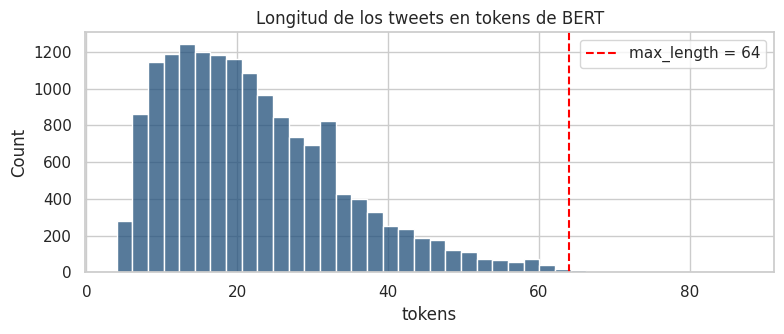

In [33]:
longitudes = [len(ids) for ids in tokenizer_p1(list(df_train_p1["text"]))["input_ids"]]
percentiles = np.percentile(longitudes, [50, 90, 95, 99, 100])
display(pd.DataFrame([percentiles], columns=["p50", "p90", "p95", "p99", "máximo"], index=["tokens"]))

P1_MAX_LEN = int(min(128, np.ceil(percentiles[3] / 8) * 8))   # p99 redondeado a múltiplo de 8
print(f"max_length elegido: {P1_MAX_LEN} tokens "
      f"(trunca solo el {np.mean(np.array(longitudes) > P1_MAX_LEN):.2%} de los tweets)")

plt.figure(figsize=(8, 3.5))
sns.histplot(longitudes, bins=40, color="#1f4e79")
plt.axvline(P1_MAX_LEN, color="red", ls="--", label=f"max_length = {P1_MAX_LEN}")
plt.title("Longitud de los tweets en tokens de BERT"); plt.xlabel("tokens"); plt.legend()
plt.tight_layout(); plt.show()

Tokenizamos los tres conjuntos con `Dataset.map` (procesamiento por lotes, muy rápido). **No** rellenamos (*padding*) aquí. Lo hará el `DataCollatorWithPadding` durante el entrenamiento, ajustando cada *batch* a la longitud de su texto más largo (**padding dinámico**). Así se ahorra cómputo frente a rellenar todo a `P1_MAX_LEN`.

In [22]:
def tokenizar_p1(batch):
    return tokenizer_p1(batch["text"], truncation=True, max_length=P1_MAX_LEN)

emotion_tok = emotion.map(tokenizar_p1, batched=True, remove_columns=["text"])
emotion_tok = emotion_tok.rename_column("label", "labels")
collator_p1 = DataCollatorWithPadding(tokenizer=tokenizer_p1)
print(emotion_tok)

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
})


### 2.6 Modelo y métricas

`AutoModelForSequenceClassification` carga BERT preentrenado y le agrega una **cabeza de clasificación**: una capa lineal que transforma el vector `[CLS]` (768 dimensiones) en 6 puntuaciones, una por emoción. Esa capa nueva empieza con pesos **aleatorios**. Por eso el modelo sin fine-tuning no sirve para la tarea.

Métricas que se calculan en validación al final de cada época:

- **Accuracy:** porcentaje de aciertos. Es intuitiva, pero engañosa con clases desbalanceadas.
- **F1-macro (métrica principal):** promedio simple del F1 de cada clase. Todas las emociones pesan igual.
- **F1-weighted:** promedio del F1 ponderado por el tamaño de cada clase.

In [23]:
def crear_modelo_p1():
    return AutoModelForSequenceClassification.from_pretrained(
        P1_MODEL, num_labels=len(label_names), id2label=id2label, label2id=label2id
    )


def metricas_p1(eval_pred):
    logits, etiquetas = eval_pred
    predicciones = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(etiquetas, predicciones),
        "f1_macro": f1_score(etiquetas, predicciones, average="macro"),
        "f1_weighted": f1_score(etiquetas, predicciones, average="weighted"),
    }


modelo_tmp = crear_modelo_p1()
n_params = sum(p.numel() for p in modelo_tmp.parameters())
print(f"Parámetros del modelo: {n_params / 1e6:.1f} millones")
print("Cabeza de clasificación:", modelo_tmp.classifier)
del modelo_tmp; liberar_memoria()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Parámetros del modelo: 109.5 millones
Cabeza de clasificación: Linear(in_features=768, out_features=6, bias=True)


La función `entrenar_p1` encapsula un entrenamiento completo con `Trainer`. El `Trainer` de Hugging Face se encarga del ciclo de entrenamiento: envía los *batches* a la GPU, calcula la pérdida (*cross-entropy*), retropropaga, actualiza los pesos con el optimizador **AdamW**, evalúa en cada época y guarda *checkpoints*.

In [24]:
def entrenar_p1(lr, batch_size, train_ds, eval_ds, epocas, output_dir, guardar=False, paciencia=None):
    """Entrena una configuración. Si guardar=True conserva el mejor checkpoint (según F1-macro)."""
    set_seed(SEED)
    args = TrainingArguments(
        output_dir=output_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=128,
        num_train_epochs=epocas,
        weight_decay=0.01,
        warmup_steps=0.1,                  # un valor < 1 se interpreta como fracción de los pasos totales (10 %)
        lr_scheduler_type="linear",
        eval_strategy="epoch",
        save_strategy="epoch" if guardar else "no",
        load_best_model_at_end=guardar,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=1,
        logging_steps=50,
        fp16=FP16,
        report_to="none",
        seed=SEED,
    )
    callbacks = [EarlyStoppingCallback(early_stopping_patience=paciencia)] if paciencia else None
    trainer = Trainer(
        model=crear_modelo_p1(), # se llama aqui el modelo
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tokenizer_p1,
        data_collator=collator_p1,
        compute_metrics=metricas_p1,
        callbacks=callbacks,
    )
    inicio = time.time()
    trainer.train()
    return trainer, time.time() - inicio

### 2.7 Búsqueda de hiperparámetros

Siguiendo el paso 7 de la guía, se exploran combinaciones de **learning rate** y **batch size** usando una **muestra estratificada** de 4.000 tweets de entrenamiento, el 25 %. *Estratificada* quiere decir que conserva la misma proporción de cada emoción. Cada configuración se evalúa en el conjunto de **validación** completo.

| Hiperparámetro | Valores probados |
|---|---|
| Learning rate | `1e-5`, `2e-5`, `3e-5`, `5e-5`, `1e-4` |
| Batch size | `16`, `32` |
| Épocas | 3 (fijo) |

Son 10 entrenamientos de aproximadamente 1-2 minutos cada uno en una T4. Incluimos `1e-4` a propósito, aunque es alto para BERT, para observar qué pasa cuando el learning rate es excesivo.

> Si la sesión de Colab se corta, al volver a ejecutar esta celda las configuraciones ya probadas se cargan desde Drive y no se repiten.

In [25]:
if MODO_PRUEBA:
    P1_TAMANO_MUESTRA, P1_LRS, P1_BATCH_SIZES, P1_EPOCAS_BUSQUEDA = 300, [2e-5, 5e-5], [16], 1
    p1_eval_busqueda = emotion_tok["validation"].select(range(200))
else:
    P1_TAMANO_MUESTRA, P1_LRS, P1_BATCH_SIZES, P1_EPOCAS_BUSQUEDA = 4000, [1e-5, 2e-5, 3e-5, 5e-5, 1e-4], [16, 32], 3
    p1_eval_busqueda = emotion_tok["validation"]

p1_muestra = emotion_tok["train"].train_test_split(
    train_size=P1_TAMANO_MUESTRA, stratify_by_column="labels", seed=SEED
)["train"]
print(f"Muestra de entrenamiento: {len(p1_muestra)} ejemplos | Validación: {len(p1_eval_busqueda)} ejemplos")

Muestra de entrenamiento: 4000 ejemplos | Validación: 2000 ejemplos


In [27]:
ruta_csv_p1 = os.path.join(P1_DIR, "busqueda_hiperparametros.csv")
ruta_hist_p1 = os.path.join(P1_DIR, "historiales_busqueda.json")
filas_p1, historiales_p1 = cargar_busqueda(ruta_csv_p1, ruta_hist_p1)
ya_probadas = {(float(f["learning_rate"]), int(f["batch_size"])) for f in filas_p1}

for bs in P1_BATCH_SIZES:
    for lr in P1_LRS:
        if (lr, bs) in ya_probadas:
            print(f"Evaluación: learning_rate={lr:.0e}, batch_size={bs} (ya probado, se omite)")
            continue

        print(f"\n Evaluando: learning_rate={lr:.0e}, batch_size={bs}")
        trainer, segundos = entrenar_p1(lr, bs, p1_muestra, p1_eval_busqueda, P1_EPOCAS_BUSQUEDA,
                                        output_dir=os.path.join("/tmp", "p1_busqueda"))
        _, evals = curvas_desde_historial(trainer.state.log_history)
        mejor = evals.loc[evals["eval_f1_macro"].idxmax()]
        filas_p1.append({
            "learning_rate": lr, "batch_size": bs,
            "f1_macro": mejor["eval_f1_macro"], "accuracy": mejor["eval_accuracy"],
            "f1_weighted": mejor["eval_f1_weighted"], "eval_loss": mejor["eval_loss"],
            "mejor_epoca": int(round(mejor["epoch"])), "minutos": segundos / 60,
        })
        historiales_p1[f"{lr}_{bs}"] = trainer.state.log_history
        guardar_busqueda(filas_p1, historiales_p1, ruta_csv_p1, ruta_hist_p1)
        del trainer; liberar_memoria()


 Evaluando: learning_rate=1e-05, batch_size=16


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'loss': '1.672', 'grad_norm': '5.801', 'learning_rate': '6.533e-06', 'epoch': '0.2'}
{'loss': '1.548', 'grad_norm': '5.216', 'learning_rate': '9.644e-06', 'epoch': '0.4'}
{'loss': '1.422', 'grad_norm': '6.74', 'learning_rate': '8.904e-06', 'epoch': '0.6'}
{'loss': '1.222', 'grad_norm': '5.052', 'learning_rate': '8.163e-06', 'epoch': '0.8'}
{'loss': '1.032', 'grad_norm': '8.3', 'learning_rate': '7.422e-06', 'epoch': '1'}
{'eval_loss': '0.9581', 'eval_accuracy': '0.6655', 'eval_f1_macro': '0.4078', 'eval_f1_weighted': '0.596', 'eval_runtime': '1.422', 'eval_samples_per_second': '1406', 'eval_steps_per_second': '11.25', 'epoch': '1'}
{'loss': '0.8696', 'grad_norm': '5.281', 'learning_rate': '6.681e-06', 'epoch': '1.2'}
{'loss': '0.7917', 'grad_norm': '37.61', 'learning_rate': '5.941e-06', 'epoch': '1.4'}
{'loss': '0.7393', 'grad_norm': '6.335', 'learning_rate': '5.2e-06', 'epoch': '1.6'}
{'loss': '0.6421', 'grad_norm': '11.46', 'learning_rate': '4.459e-06', 'epoch': '1.8'}
{'loss': '0.61

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'loss': '1.653', 'grad_norm': '5.588', 'learning_rate': '1.307e-05', 'epoch': '0.2'}
{'loss': '1.45', 'grad_norm': '8.409', 'learning_rate': '1.929e-05', 'epoch': '0.4'}
{'loss': '1.142', 'grad_norm': '4.633', 'learning_rate': '1.781e-05', 'epoch': '0.6'}
{'loss': '0.9293', 'grad_norm': '4.949', 'learning_rate': '1.633e-05', 'epoch': '0.8'}
{'loss': '0.7046', 'grad_norm': '15.67', 'learning_rate': '1.484e-05', 'epoch': '1'}
{'eval_loss': '0.5996', 'eval_accuracy': '0.787', 'eval_f1_macro': '0.6493', 'eval_f1_weighted': '0.7503', 'eval_runtime': '1.579', 'eval_samples_per_second': '1267', 'eval_steps_per_second': '10.14', 'epoch': '1'}
{'loss': '0.4776', 'grad_norm': '7.935', 'learning_rate': '1.336e-05', 'epoch': '1.2'}
{'loss': '0.4309', 'grad_norm': '8.959', 'learning_rate': '1.188e-05', 'epoch': '1.4'}
{'loss': '0.3857', 'grad_norm': '11.73', 'learning_rate': '1.04e-05', 'epoch': '1.6'}
{'loss': '0.3259', 'grad_norm': '3.715', 'learning_rate': '8.919e-06', 'epoch': '1.8'}
{'loss': 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (11 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'loss': '1.55', 'grad_norm': '7.453', 'learning_rate': '4.837e-05', 'epoch': '0.4'}
{'loss': '1.003', 'grad_norm': '6.581', 'learning_rate': '4.095e-05', 'epoch': '0.8'}
{'eval_loss': '0.4767', 'eval_accuracy': '0.856', 'eval_f1_macro': '0.81', 'eval_f1_weighted': '0.8534', 'eval_runtime': '1.541', 'eval_samples_per_second': '1298', 'eval_steps_per_second': '10.38', 'epoch': '1'}
{'loss': '0.4807', 'grad_norm': '3.88', 'learning_rate': '3.353e-05', 'epoch': '1.2'}
{'loss': '0.3287', 'grad_norm': '7.157', 'learning_rate': '2.611e-05', 'epoch': '1.6'}
{'loss': '0.2562', 'grad_norm': '5.664', 'learning_rate': '1.869e-05', 'epoch': '2'}
{'eval_loss': '0.2682', 'eval_accuracy': '0.9115', 'eval_f1_macro': '0.8871', 'eval_f1_weighted': '0.9113', 'eval_runtime': '1.541', 'eval_samples_per_second': '1298', 'eval_steps_per_second': '10.38', 'epoch': '2'}
{'loss': '0.1356', 'grad_norm': '2.71', 'learning_rate': '1.128e-05', 'epoch': '2.4'}
{'loss': '0.1395', 'grad_norm': '8.073', 'learning_rate'

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'loss': '1.426', 'grad_norm': '20.01', 'learning_rate': '9.674e-05', 'epoch': '0.4'}
{'loss': '0.7527', 'grad_norm': '5.404', 'learning_rate': '8.19e-05', 'epoch': '0.8'}
{'eval_loss': '0.3571', 'eval_accuracy': '0.8855', 'eval_f1_macro': '0.8586', 'eval_f1_weighted': '0.8852', 'eval_runtime': '1.536', 'eval_samples_per_second': '1302', 'eval_steps_per_second': '10.41', 'epoch': '1'}
{'loss': '0.3524', 'grad_norm': '11.29', 'learning_rate': '6.706e-05', 'epoch': '1.2'}
{'loss': '0.3243', 'grad_norm': '4.872', 'learning_rate': '5.223e-05', 'epoch': '1.6'}
{'loss': '0.2005', 'grad_norm': '3.421', 'learning_rate': '3.739e-05', 'epoch': '2'}
{'eval_loss': '0.266', 'eval_accuracy': '0.915', 'eval_f1_macro': '0.8879', 'eval_f1_weighted': '0.9144', 'eval_runtime': '1.604', 'eval_samples_per_second': '1247', 'eval_steps_per_second': '9.972', 'epoch': '2'}
{'loss': '0.1256', 'grad_norm': '15', 'learning_rate': '2.255e-05', 'epoch': '2.4'}
{'loss': '0.1131', 'grad_norm': '12.14', 'learning_rate

Evaluando mediante gráficas cual es el mejor conjunto de hiperparametros

,learning_rate,batch_size,f1_macro,accuracy,f1_weighted,eval_loss,mejor_epoca,minutos
0,5e-05,16,0.9001,0.9210,0.9207,0.2786,3,1.0
1,3e-05,16,0.8945,0.9160,0.9157,0.2809,2,1.0
2,1e-04,32,0.8936,0.9190,0.9181,0.2628,3,0.7
3,5e-05,32,0.8931,0.9145,0.9140,0.2655,3,0.7
4,1e-04,16,0.8895,0.9135,0.9131,0.3037,3,1.0
5,2e-05,16,0.8855,0.9130,0.9124,0.2895,3,1.0
6,3e-05,32,0.8808,0.9070,0.9064,0.3051,3,0.7
7,2e-05,32,0.8100,0.8680,0.8634,0.4452,3,0.7
8,1e-05,16,0.7532,0.8320,0.8180,0.5031,3,1.1
9,1e-05,32,0.5325,0.7340,0.6852,0.7877,3,0.7


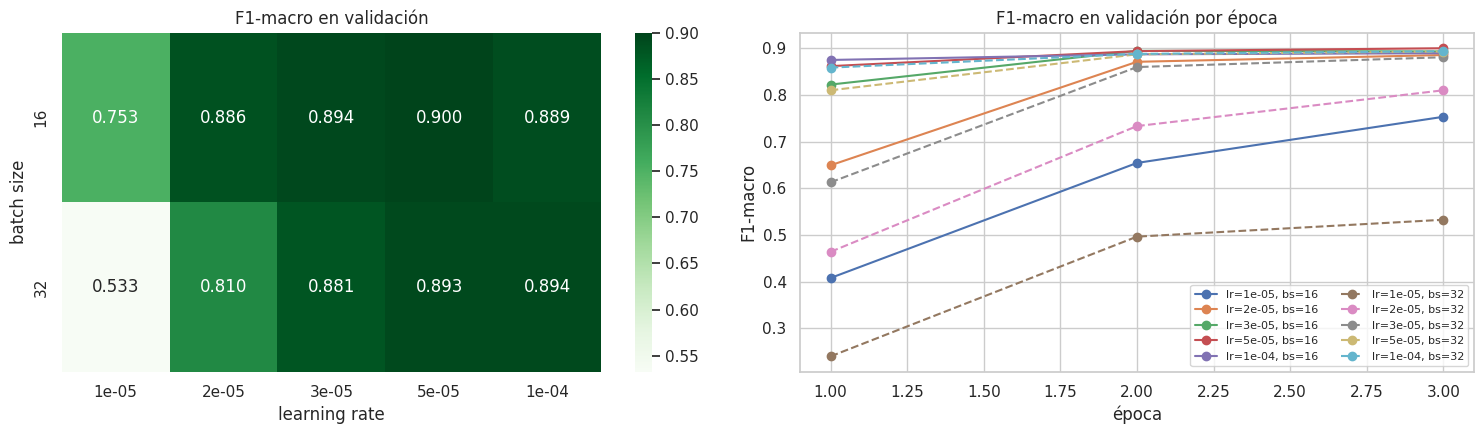


 Mejor configuración: learning rate = 5e-05, batch size = 16 → F1-macro = 0.9001


In [28]:
busqueda_p1 = pd.DataFrame(filas_p1).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(busqueda_p1.style.format({"learning_rate": "{:.0e}", "f1_macro": "{:.4f}", "accuracy": "{:.4f}",
                                  "f1_weighted": "{:.4f}", "eval_loss": "{:.4f}", "minutos": "{:.1f}"})
        .background_gradient(subset=["f1_macro"], cmap="Greens"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
tabla = busqueda_p1.pivot(index="batch_size", columns="learning_rate", values="f1_macro")
sns.heatmap(tabla, annot=True, fmt=".3f", cmap="Greens", ax=axes[0],
            xticklabels=[f"{c:.0e}" for c in tabla.columns])
axes[0].set_title("F1-macro en validación"); axes[0].set_xlabel("learning rate"); axes[0].set_ylabel("batch size")

for clave, log in historiales_p1.items():
    lr, bs = clave.split("_")
    _, ev = curvas_desde_historial(log)
    axes[1].plot(ev["epoch"], ev["eval_f1_macro"], marker="o",
                 ls="-" if bs == str(P1_BATCH_SIZES[0]) else "--", label=f"lr={float(lr):.0e}, bs={bs}")
axes[1].set_title("F1-macro en validación por época"); axes[1].set_xlabel("época"); axes[1].set_ylabel("F1-macro")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

mejor_p1 = busqueda_p1.iloc[0]
P1_MEJOR_LR, P1_MEJOR_BS = float(mejor_p1["learning_rate"]), int(mejor_p1["batch_size"])
print(f"\n Mejor configuración: learning rate = {P1_MEJOR_LR:.0e}, batch size = {P1_MEJOR_BS} "
      f"→ F1-macro = {mejor_p1['f1_macro']:.4f}")

#### ¿Cómo se interpretan estos resultados?

- La mejor configuración fue **learning rate 5e-5 con batch size 16**, con un F1-macro de 0.9001 en validación. Esa es la configuración que se usa para el entrenamiento final.
- El learning rate fue el hiperparámetro más determinante. Con 1e-5 el modelo aprende demasiado lento: en 3 épocas solo llegó a 0.75 (batch 16) y 0.53 (batch 32), y no alcanzó a aprender las clases pequeñas como surprise.
- De 3e-5 en adelante los resultados son muy parecidos (entre 0.88 y 0.90), así que el modelo no es muy sensible al valor exacto dentro de ese rango.
- Con batch 32 el modelo hace la mitad de actualizaciones por época, por eso necesita un learning rate más alto para llegar al mismo nivel. Con 2e-5, batch 16 logró 0.886 y batch 32 solo 0.810.
- 1e-4, que es alto para BERT, no hizo colapsar el modelo (0.89), probablemente porque los textos son cortos y la tarea es relativamente sencilla. Aun así no superó a 5e-5.
- Batch 32 fue más rápido (0.7 minutos frente a 1.0 por prueba), pero con 4.000 ejemplos la diferencia de tiempo no es relevante.

### 2.8 Entrenamiento final con todos los datos

Con la mejor configuración entrenamos sobre los **16.000** tweets:

- Hasta **5 épocas**, evaluando en validación al final de cada una.
- **Early stopping** con paciencia 2: si el F1-macro en validación no mejora durante 2 épocas seguidas, el entrenamiento se detiene para evitar el sobreajuste.
- Al terminar se **restaura el checkpoint de la mejor época** (`load_best_model_at_end`), no necesariamente el de la última.

In [29]:
if MODO_PRUEBA:
    p1_train, p1_val, p1_test = (emotion_tok["train"].select(range(600)),
                                 emotion_tok["validation"].select(range(200)),
                                 emotion_tok["test"].select(range(200)))
    P1_EPOCAS_FINAL = 1
else:
    p1_train, p1_val, p1_test = emotion_tok["train"], emotion_tok["validation"], emotion_tok["test"]
    P1_EPOCAS_FINAL = 5

dir_checkpoints_p1 = os.path.join(P1_DIR, "checkpoints")
trainer_p1, segundos_p1 = entrenar_p1(P1_MEJOR_LR, P1_MEJOR_BS, p1_train, p1_val, P1_EPOCAS_FINAL,
                                      output_dir=dir_checkpoints_p1, guardar=True, paciencia=2)
print(f"Entrenamiento final completado en {segundos_p1 / 60:.1f} minutos")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'loss': '1.694', 'grad_norm': '6.044', 'learning_rate': '4.9e-06', 'epoch': '0.05'}
{'loss': '1.586', 'grad_norm': '5.209', 'learning_rate': '9.9e-06', 'epoch': '0.1'}
{'loss': '1.488', 'grad_norm': '6.35', 'learning_rate': '1.49e-05', 'epoch': '0.15'}
{'loss': '1.177', 'grad_norm': '8.876', 'learning_rate': '1.99e-05', 'epoch': '0.2'}
{'loss': '0.8916', 'grad_norm': '27.65', 'learning_rate': '2.49e-05', 'epoch': '0.25'}
{'loss': '0.6219', 'grad_norm': '5.084', 'learning_rate': '2.99e-05', 'epoch': '0.3'}
{'loss': '0.4945', 'grad_norm': '4.627', 'learning_rate': '3.49e-05', 'epoch': '0.35'}
{'loss': '0.4198', 'grad_norm': '17.78', 'learning_rate': '3.99e-05', 'epoch': '0.4'}
{'loss': '0.3751', 'grad_norm': '9.849', 'learning_rate': '4.49e-05', 'epoch': '0.45'}
{'loss': '0.3316', 'grad_norm': '2.838', 'learning_rate': '4.99e-05', 'epoch': '0.5'}
{'loss': '0.3675', 'grad_norm': '0.5595', 'learning_rate': '4.946e-05', 'epoch': '0.55'}
{'loss': '0.2946', 'grad_norm': '21.58', 'learning_ra

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.1114', 'grad_norm': '0.95', 'learning_rate': '4.39e-05', 'epoch': '1.05'}
{'loss': '0.1496', 'grad_norm': '0.02755', 'learning_rate': '4.334e-05', 'epoch': '1.1'}
{'loss': '0.1916', 'grad_norm': '1.241', 'learning_rate': '4.279e-05', 'epoch': '1.15'}
{'loss': '0.1849', 'grad_norm': '1.725', 'learning_rate': '4.223e-05', 'epoch': '1.2'}
{'loss': '0.1476', 'grad_norm': '0.4091', 'learning_rate': '4.168e-05', 'epoch': '1.25'}
{'loss': '0.1904', 'grad_norm': '1.395', 'learning_rate': '4.112e-05', 'epoch': '1.3'}
{'loss': '0.1617', 'grad_norm': '6.942', 'learning_rate': '4.057e-05', 'epoch': '1.35'}
{'loss': '0.1913', 'grad_norm': '5.227', 'learning_rate': '4.001e-05', 'epoch': '1.4'}
{'loss': '0.1195', 'grad_norm': '0.5224', 'learning_rate': '3.946e-05', 'epoch': '1.45'}
{'loss': '0.1852', 'grad_norm': '2.744', 'learning_rate': '3.89e-05', 'epoch': '1.5'}
{'loss': '0.1173', 'grad_norm': '0.03612', 'learning_rate': '3.834e-05', 'epoch': '1.55'}
{'loss': '0.1373', 'grad_norm': '1

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.09819', 'grad_norm': '0.0428', 'learning_rate': '3.279e-05', 'epoch': '2.05'}
{'loss': '0.1026', 'grad_norm': '1.049', 'learning_rate': '3.223e-05', 'epoch': '2.1'}
{'loss': '0.1007', 'grad_norm': '0.8528', 'learning_rate': '3.168e-05', 'epoch': '2.15'}
{'loss': '0.1028', 'grad_norm': '8.856', 'learning_rate': '3.112e-05', 'epoch': '2.2'}
{'loss': '0.1062', 'grad_norm': '2.094', 'learning_rate': '3.057e-05', 'epoch': '2.25'}
{'loss': '0.1219', 'grad_norm': '10.05', 'learning_rate': '3.001e-05', 'epoch': '2.3'}
{'loss': '0.1062', 'grad_norm': '2.005', 'learning_rate': '2.946e-05', 'epoch': '2.35'}
{'loss': '0.1165', 'grad_norm': '0.8423', 'learning_rate': '2.89e-05', 'epoch': '2.4'}
{'loss': '0.1328', 'grad_norm': '0.9005', 'learning_rate': '2.834e-05', 'epoch': '2.45'}
{'loss': '0.08907', 'grad_norm': '0.02314', 'learning_rate': '2.779e-05', 'epoch': '2.5'}
{'loss': '0.1304', 'grad_norm': '0.6337', 'learning_rate': '2.723e-05', 'epoch': '2.55'}
{'loss': '0.1011', 'grad_norm

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.03523', 'grad_norm': '0.008621', 'learning_rate': '1.057e-05', 'epoch': '4.05'}
{'loss': '0.05544', 'grad_norm': '0.01475', 'learning_rate': '1.001e-05', 'epoch': '4.1'}
{'loss': '0.0389', 'grad_norm': '0.008448', 'learning_rate': '9.456e-06', 'epoch': '4.15'}
{'loss': '0.05353', 'grad_norm': '12.14', 'learning_rate': '8.9e-06', 'epoch': '4.2'}
{'loss': '0.05047', 'grad_norm': '0.01512', 'learning_rate': '8.344e-06', 'epoch': '4.25'}
{'loss': '0.0449', 'grad_norm': '0.01278', 'learning_rate': '7.789e-06', 'epoch': '4.3'}
{'loss': '0.05949', 'grad_norm': '2.031', 'learning_rate': '7.233e-06', 'epoch': '4.35'}
{'loss': '0.0473', 'grad_norm': '22.71', 'learning_rate': '6.678e-06', 'epoch': '4.4'}
{'loss': '0.07559', 'grad_norm': '1.206', 'learning_rate': '6.122e-06', 'epoch': '4.45'}
{'loss': '0.04072', 'grad_norm': '7.088', 'learning_rate': '5.567e-06', 'epoch': '4.5'}
{'loss': '0.04716', 'grad_norm': '1.968', 'learning_rate': '5.011e-06', 'epoch': '4.55'}
{'loss': '0.03049',

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '427.6', 'train_samples_per_second': '187.1', 'train_steps_per_second': '11.69', 'train_loss': '0.1984', 'epoch': '5'}
Entrenamiento final completado en 7.2 minutos


#### Curvas de aprendizaje

- La pérdida de entrenamiento baja rápido durante la primera época y luego sigue bajando lentamente hasta casi 0.05.
- La pérdida de validación es mínima en la época 2 (0.145) y después empieza a subir (0.266 en la época 5). Es una señal de **sobreajuste**: el modelo sigue mejorando en los datos de entrenamiento, pero se vuelve demasiado seguro de sus predicciones en datos nuevos.
- Aun así, el F1-macro en validación siguió mejorando hasta la época 4 (0.9207) y cayó en la época 5 (0.9067). Como el early stopping exige 2 épocas seguidas sin mejora, no alcanzó a detener el entrenamiento antes de la época 5.
- Gracias a `load_best_model_at_end`, el modelo que se usa en adelante es el de la **época 4**, la de mejor F1-macro, y no el de la última época.

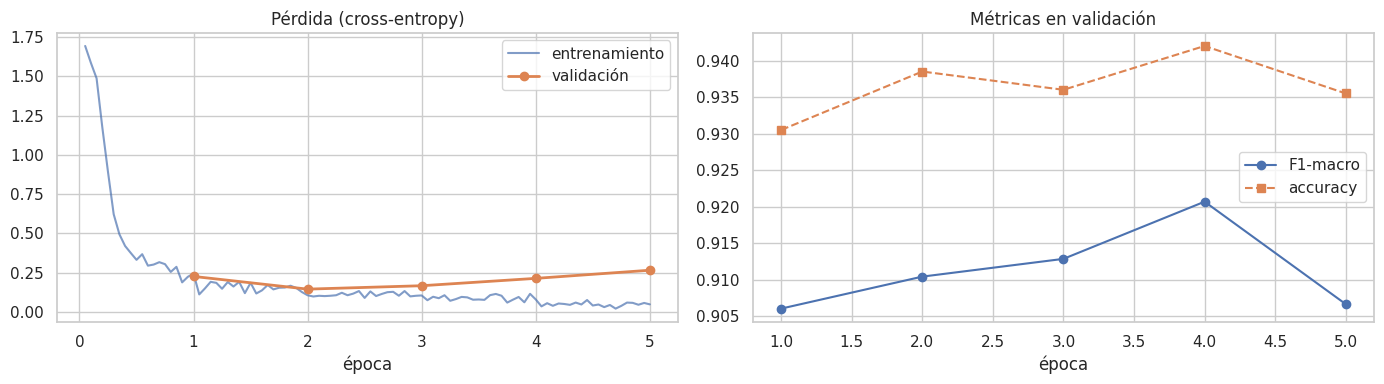

,epoch,eval_loss,eval_accuracy,eval_f1_macro,eval_f1_weighted
20,1.0,0.2260,0.9305,0.9060,0.9309
41,2.0,0.1451,0.9385,0.9104,0.9373
62,3.0,0.1667,0.9360,0.9129,0.9358
83,4.0,0.2136,0.9420,0.9207,0.9421
104,5.0,0.2655,0.9355,0.9067,0.9352


In [30]:
curva_train_p1, curva_val_p1 = curvas_desde_historial(trainer_p1.state.log_history)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(curva_train_p1["epoch"], curva_train_p1["loss"], label="entrenamiento", alpha=0.7)
axes[0].plot(curva_val_p1["epoch"], curva_val_p1["eval_loss"], "o-", label="validación", lw=2)
axes[0].set_title("Pérdida (cross-entropy)"); axes[0].set_xlabel("época"); axes[0].legend()
axes[1].plot(curva_val_p1["epoch"], curva_val_p1["eval_f1_macro"], "o-", label="F1-macro")
axes[1].plot(curva_val_p1["epoch"], curva_val_p1["eval_accuracy"], "s--", label="accuracy")
axes[1].set_title("Métricas en validación"); axes[1].set_xlabel("época"); axes[1].legend()
plt.tight_layout(); plt.show()

display(curva_val_p1[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro", "eval_f1_weighted"]].round(4))

### 2.9 Evaluación en el conjunto de prueba (test)

Ahora, y **solo ahora**, evaluamos en los 2.000 tweets de test, que el modelo nunca vio y que no usamos para tomar ninguna decisión. Esta es la medida honesta de cómo funcionaría el modelo con datos nuevos.

In [31]:
salida_test = trainer_p1.predict(p1_test)
y_true_p1 = salida_test.label_ids
y_pred_p1 = salida_test.predictions.argmax(-1)
probs_p1 = torch.softmax(torch.tensor(salida_test.predictions, dtype=torch.float32), dim=-1).numpy()

df_test_p1 = df_p1["test"].iloc[: len(p1_test)].copy()
pred_test_base = linea_base.predict(df_test_p1["text"])

comparacion_p1 = pd.DataFrame({
    "TF-IDF + Reg. Logística": [accuracy_score(y_true_p1, pred_test_base), f1_score(y_true_p1, pred_test_base, average="macro")],
    f"{P1_MODEL} (fine-tuned)": [accuracy_score(y_true_p1, y_pred_p1), f1_score(y_true_p1, y_pred_p1, average="macro")],
}, index=["accuracy", "f1_macro"]).T
display(comparacion_p1.style.format("{:.4f}").highlight_max(color="#0a8021"))

print(classification_report(y_true_p1, y_pred_p1, target_names=label_names, digits=4, labels=range(len(label_names))))

,accuracy,f1_macro
TF-IDF + Reg. Logística,0.8305,0.7255
bert-base-uncased (fine-tuned),0.9325,0.8883


              precision    recall  f1-score   support

     sadness     0.9775    0.9725    0.9750       581
         joy     0.9604    0.9410    0.9506       695
        love     0.8193    0.8553    0.8369       159
       anger     0.9345    0.9345    0.9345       275
        fear     0.8860    0.9018    0.8938       224
    surprise     0.7083    0.7727    0.7391        66

    accuracy                         0.9325      2000
   macro avg     0.8810    0.8963    0.8883      2000
weighted avg     0.9339    0.9325    0.9331      2000



#### Comparación con la línea base

| Modelo | Accuracy | F1-macro |
|---|---|---|
| TF-IDF + Regresión Logística | 0.8305 | 0.7255 |
| bert-base-uncased (fine-tuned) | 0.9325 | 0.8883 |

El fine-tuning mejora el F1-macro en 16 puntos y la accuracy en 10 puntos. En otras palabras, la línea base se equivoca en el 17 % de los tweets y BERT en el 6.8 %: cerca de 60 % menos errores.

La mejora es mayor en el F1-macro que en la accuracy porque BERT es mucho mejor en las clases pequeñas. La línea base depende de que aparezcan palabras clave vistas en el entrenamiento, mientras que BERT reconoce sinónimos y expresiones que aprendió en el preentrenamiento. Esto confirma que, aunque el problema es relativamente fácil (cada emoción tiene un vocabulario propio), el fine-tuning sí justifica su costo.

Por clase, sadness (0.975) y joy (0.951) son las mejores, y surprise (0.739) y love (0.837) las más difíciles. Coinciden con las clases con menos ejemplos.

#### Matriz de confusión
Cada fila es la emoción **real** y cada columna la **predicha**. Los valores están normalizados por fila: la diagonal es el *recall* de cada clase y los valores fuera de ella muestran con qué clase se confunde cada emoción.

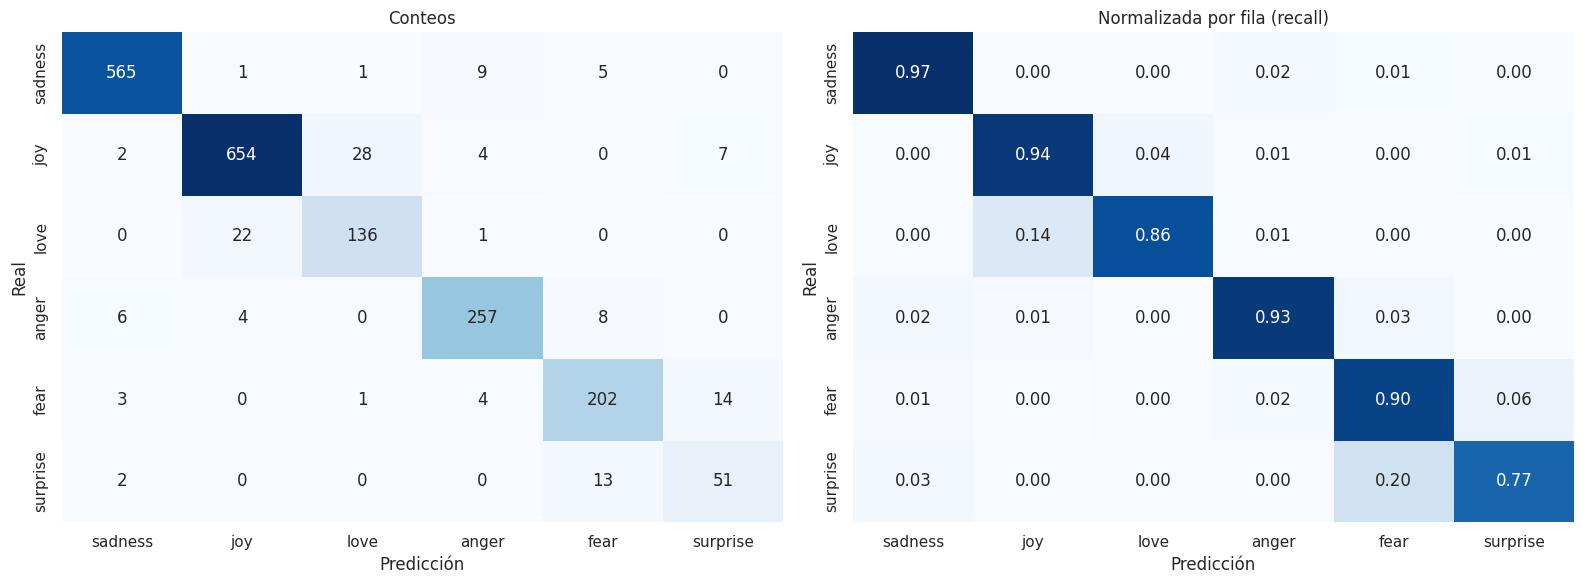

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (normalizar, titulo, formato) in zip(axes, [(None, "Conteos", "d"), ("true", "Normalizada por fila (recall)", ".2f")]):
    cm = confusion_matrix(y_true_p1, y_pred_p1, labels=range(len(label_names)), normalize=normalizar)
    sns.heatmap(cm, annot=True, fmt=formato, cmap="Blues", xticklabels=label_names, yticklabels=label_names, ax=ax, cbar=False)
    ax.set_title(titulo); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

**Observaciones**

- Los errores no están repartidos al azar: se concentran en dos pares de emociones parecidas.
- **love y joy**: 22 tweets de love (14 %) se predicen como joy, y 28 de joy como love. Ambas son emociones positivas y comparten mucho vocabulario ("happy", "lucky", "blessed").
- **surprise y fear**: 13 tweets de surprise (20 %) se predicen como fear, y 14 de fear como surprise. Palabras como "shocked" o "overwhelmed" pueden expresar cualquiera de las dos según el contexto.
- Las clases mayoritarias (sadness y joy) casi no se confunden con las demás.
- surprise es la clase más difícil: tiene solo 66 ejemplos en test y su principal confusión es con fear.

#### Análisis de errores
Revisar los errores con mayor confianza ayuda a entender las limitaciones del modelo y del dataset. Muchas veces la etiqueta "real" es discutible.

In [34]:
df_test_p1["prediccion"] = [id2label[i] for i in y_pred_p1]
df_test_p1["confianza"] = probs_p1.max(axis=1)
errores_p1 = df_test_p1[df_test_p1["label"] != y_pred_p1]
print(f"Errores: {len(errores_p1)} de {len(df_test_p1)} ({len(errores_p1) / len(df_test_p1):.1%})")
display(errores_p1.sort_values("confianza", ascending=False)
        .head(12)[["text", "emotion", "prediccion", "confianza"]]
        .rename(columns={"emocion": "real"}).style.format({"confianza": "{:.1%}"}))

Errores: 135 de 2000 (6.8%)


,text,emotion,prediccion,confianza
1928,i feel inside cause life is like a game sometimes but then you came around me the walls just disappeared nothing to surround me and keep me from my fears im unprotected see how ive opened up youve made me trust,fear,sadness,100.0%
193,i really dont like quinn because i feel like she will just end up hurting barney and i hated the lame ted robin storyline,anger,sadness,100.0%
1583,i am not feeling so generous and he is sent to the sofa where he glares at me for the next six hours,joy,anger,100.0%
816,whenever i put myself in others shoes and try to make the person happy,anger,joy,100.0%
1382,i cannot even begin to express in words the depth of sorrow that i feel having not posted any of my ludicrous rants over the passed days,surprise,sadness,100.0%
1282,im always feeling so agitated overly excited and impatient to those who are close to me,anger,fear,99.9%
1270,i feel very saddened that the king whom i once quite respected as far as monarchs go was ineffectual at best,joy,sadness,99.9%
306,i took for granted a few weeks ago is really weird and makes me feel really agitated and frustrated,anger,fear,99.9%
922,i was lying in bed last night after a day of making experiments from the usual suspects fabric plastic and feeling agitated that my issues with proper presentation had not made any headway over the course of a mere six hours,anger,fear,99.9%
1377,i walked to school he felt the bounce in his step the overjoyed feelings of youth and the thrill of excitement of coming to school and meeting his beloved friends,love,joy,99.9%


**Observaciones**

El modelo falla en 135 de 2.000 tweets (6.8 %). Al revisar los errores en los que estaba más seguro, muchos no parecen errores del modelo sino de la etiqueta original:

- "i feel very saddened that the king..." está etiquetado como joy, y el modelo predice sadness.
- "i cannot even begin to express in words the depth of sorrow that i feel..." está etiquetado como surprise, y el modelo predice sadness.
- "i am not feeling so generous and he is sent to the sofa where he glares at me..." está etiquetado como joy, y el modelo predice anger.

Esto confirma lo visto en el análisis exploratorio: las etiquetas salen de hashtags y tienen ruido, lo que pone un techo al desempeño que cualquier modelo puede alcanzar.

También aparece un patrón: varios tweets con la palabra "agitated" están etiquetados como anger, pero el modelo los predice como fear. Es una palabra ambigua que en el entrenamiento probablemente aparece en ambas emociones.

### 2.10 Guardar y demostrar el mejor modelo

Guardamos el modelo final (pesos + tokenizador + nombres de las etiquetas) y borramos los checkpoints intermedios para ahorrar espacio en Drive. Luego lo cargamos con `pipeline`, la forma más simple de usar un modelo de Hugging Face, y lo probamos con **frases nuevas**.

In [35]:
P1_MEJOR_DIR = os.path.join(P1_DIR, "mejor_modelo")
trainer_p1.save_model(P1_MEJOR_DIR)          # guarda pesos, configuración (id2label) y tokenizador
shutil.rmtree(dir_checkpoints_p1, ignore_errors=True)

clasificador = pipeline("text-classification", model=P1_MEJOR_DIR, top_k=None,
                        device=0 if torch.cuda.is_available() else -1)

frases_nuevas = [
    "i finally got the job i wanted and i cannot stop smiling",
    "i feel so lonely since my best friend moved away",
    "i am furious that they cancelled my flight without any notice",
    "i feel nervous about walking home alone so late at night",
    "i was shocked to find out i had won the contest",
    "i feel so lucky to have you by my side every day",
    "i don't feel happy at all with how things turned out",
]
filas = []

for frase, puntuaciones in zip(frases_nuevas, clasificador(frases_nuevas)):
    puntuaciones = sorted(puntuaciones, key=lambda d: -d["score"])
    filas.append({"frase": frase,
                  "predicción": puntuaciones[0]["label"],
                  "confianza": puntuaciones[0]["score"],
                  "2ª opción": f"{puntuaciones[1]['label']} ({puntuaciones[1]['score']:.0%})"})
display(pd.DataFrame(filas).style.format({"confianza": "{:.1%}"}))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,frase,predicción,confianza,2ª opción
0,i finally got the job i wanted and i cannot stop smiling,joy,99.9%,love (0%)
1,i feel so lonely since my best friend moved away,sadness,100.0%,anger (0%)
2,i am furious that they cancelled my flight without any notice,anger,99.9%,sadness (0%)
3,i feel nervous about walking home alone so late at night,fear,100.0%,surprise (0%)
4,i was shocked to find out i had won the contest,surprise,99.5%,joy (0%)
5,i feel so lucky to have you by my side every day,joy,99.9%,love (0%)
6,i don't feel happy at all with how things turned out,joy,100.0%,love (0%)


La última frase ("i don't feel happy at all with how things turned out") es una prueba de **negación**, y el modelo falla: predice joy con 100 % de confianza.

Hay dos razones probables:

- En el dataset la emoción casi siempre la indica una palabra clave ("happy", "gloomy", "terrified"), y hay muy pocos ejemplos de negaciones. El modelo aprendió a apoyarse en esas palabras más que en el sentido completo de la frase.
- Los tweets del dataset no tienen apóstrofes ("dont"), pero la frase de prueba sí ("don't"). El tokenizador la divide de forma distinta a lo que el modelo vio en el entrenamiento.

También se ve que el modelo da confianzas cercanas al 100 % incluso cuando se equivoca, lo que coincide con el sobreajuste observado en la pérdida de validación. El preentrenamiento le da a BERT la capacidad de entender contexto, pero el fine-tuning solo la aprovecha si los datos de entrenamiento incluyen ejemplos de ese tipo.

In [36]:
guardar_resultado("p1_emotion", {
    "modelo": P1_MODEL,
    "mejor_learning_rate": P1_MEJOR_LR,
    "mejor_batch_size": P1_MEJOR_BS,
    "epocas_entrenadas": float(curva_val_p1["epoch"].max()),
    "minutos_entrenamiento": round(segundos_p1 / 60, 1),
    "test_accuracy": float(accuracy_score(y_true_p1, y_pred_p1)),
    "test_f1_macro": float(f1_score(y_true_p1, y_pred_p1, average="macro")),
    "linea_base_test_f1_macro": float(f1_score(y_true_p1, pred_test_base, average="macro")),
})
del trainer_p1, clasificador; liberar_memoria()
print(json.dumps(json.load(open(RUTA_RESULTADOS))["p1_emotion"], indent=2))

{
  "modelo": "bert-base-uncased",
  "mejor_learning_rate": 5e-05,
  "mejor_batch_size": 16,
  "epocas_entrenadas": 5.0,
  "minutos_entrenamiento": 7.2,
  "test_accuracy": 0.9325,
  "test_f1_macro": 0.8883273501692083,
  "linea_base_test_f1_macro": 0.7255196164278496
}


### 2.11 Conclusiones del Problema 1

1. La mejor configuración fue learning rate 5e-5 con batch size 16. El learning rate fue el hiperparámetro más importante: valores muy bajos (1e-5) dejaron el modelo sin aprender, mientras que entre 3e-5 y 1e-4 los resultados fueron similares.
2. El modelo final, entrenado 5 épocas en 7.2 minutos en una GPU T4, obtuvo en test una accuracy de 0.9325 y un F1-macro de 0.8883, frente a 0.8305 y 0.7255 de la línea base TF-IDF. El fine-tuning redujo los errores en cerca de 60 %.
3. Las clases más difíciles fueron surprise (F1 0.74) y love (F1 0.84). Tienen pocos ejemplos y se confunden con emociones parecidas: surprise con fear y love con joy.
4. Limitaciones:
   - Las etiquetas vienen de hashtags y tienen ruido. Varios de los errores del modelo parecen errores de la etiqueta original.
   - Casi todos los tweets siguen el patrón "i feel ...", así que el modelo podría no funcionar igual con textos de otro estilo.
   - El modelo no maneja bien las negaciones y tiende a dar confianzas muy altas incluso cuando se equivoca.
   - El F1-macro en test (0.888) es algo menor que en validación (0.921), en parte porque surprise tiene solo 66 ejemplos de prueba y unos pocos errores mueven mucho la métrica.

# 3. Dataset 2 - Reconocimiento de entidades nombradas (NER)

### 3.1 Descripción del dataset

El segundo problema es de **etiquetado de secuencias**: en lugar de asignar una etiqueta a todo el texto, el modelo asigna una etiqueta a **cada palabra**. En este caso la tarea es el Reconocimiento de Entidades Nombradas (NER, por sus siglas en inglés): encontrar en una oración los nombres de personas, organizaciones, lugares y otras entidades.

Para resolverlo se hace fine-tuning de `bert-base-cased`. A diferencia del problema 1, aquí se usa la versión **cased**, que distingue mayúsculas y minúsculas: en inglés la mayúscula inicial es una pista muy fuerte de que una palabra es un nombre propio ("Apple" la empresa frente a "apple" la fruta). BERT genera un vector por cada token y sobre cada uno se agrega una capa de clasificación con 9 salidas, una por etiqueta.

| Aspecto | Descripción |
|---|---|
| Nombre | CoNLL-2003, disponible en Hugging Face como `eriktks/conll2003` |
| Origen | Tjong Kim Sang y De Meulder (2003), "Introduction to the CoNLL-2003 Shared Task: Language-Independent Named Entity Recognition" |
| Dominio | Noticias de la agencia Reuters en inglés (1996-1997): política, economía y muchos resultados deportivos |
| Etiquetado | Anotación manual, palabra por palabra |
| Entrada | Una oración ya dividida en palabras. Ej: ["EU", "rejects", "German", "call", "to", "boycott", "British", "lamb", "."] |
| Salida | Una etiqueta por palabra, de 9 posibles: O (no es entidad) y B-/I- para PER (persona), ORG (organización), LOC (lugar) y MISC (otras, como nacionalidades o eventos) |
| Tipo de problema | Etiquetado de secuencias (clasificación a nivel de token) |
| Tamaño | 14.041 oraciones de entrenamiento, 3.250 de validación y 3.453 de prueba |

El dataset también incluye etiquetas gramaticales (POS) y de chunks, pero en este proyecto solo se usan las de NER.

NER es un paso base de muchos sistemas: extraer automáticamente quién, qué organización y dónde aparece en noticias, contratos o historias clínicas; anonimizar documentos ocultando nombres de personas; o alimentar buscadores y bases de conocimiento. CoNLL-2003 es el benchmark de referencia para esta tarea, así que los resultados se pueden comparar con los publicados en la literatura.

### 3.2 Carga del dataset

La versión oficial del dataset en Hugging Face depende de un script de carga, que las versiones recientes de `datasets` ya no permiten ejecutar. Por eso se carga desde la rama `refs/convert/parquet`, una copia en formato Parquet que genera el propio Hugging Face con los mismos datos.

También se importan las clases específicas para clasificación de tokens y la librería `seqeval`, que calcula las métricas de NER a nivel de entidad.

In [8]:
P2_MODEL = "bert-base-cased" # BERT preentrenado en inglés que distingue mayúsculas y minúsculas. https://huggingface.co/google-bert/bert-base-cased

P2_DIR = os.path.join(BASE_DIR, "p2_ner")
os.makedirs(P2_DIR, exist_ok=True)

conll = load_dataset("eriktks/conll2003", revision="refs/convert/parquet")

conll2003/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

conll2003/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/312k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/283k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

In [11]:
print(conll)
print("\nEsquema de las columnas:", conll["train"].features)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})

Esquema de las columnas: {'id': Value('string'), 'tokens': List(Value('string')), 'pos_tags': List(ClassLabel(names=['"', "''", '#', '$', '(', ')', ',', '.', ':', '``', 'CC', 'CD', 'DT', 'EX', 'FW', 'IN', 'JJ', 'JJR', 'JJS', 'LS', 'MD', 'NN', 'NNP', 'NNPS', 'NNS', 'NN|SYM', 'PDT', 'POS', 'PRP', 'PRP$', 'RB', 'RBR', 'RBS', 'RP', 'SYM', 'TO', 'UH', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ', 'WDT', 'WP', 'WP$', 'WRB'])), 'chunk_tags': List(ClassLabel(names=['O', 'B-ADJP', 'I-ADJP', 'B-ADVP', 'I-ADVP', 'B-CONJP', 'I-CONJP', 'B-INTJ', 'I-INTJ', 'B-LST', 'I-LST', 'B-NP', 'I-NP', 'B-PP', 'I-PP', 'B-PRT',

### 3.3 Análisis exploratorio

In [12]:
ner_names = conll["train"].features["ner_tags"].feature.names # ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']

id2label_p2 = {i: nombre for i, nombre in enumerate(ner_names)}
label2id_p2 = {nombre: i for i, nombre in id2label_p2.items()}

print("id2label:", id2label_p2)

# Versiones en pandas para el análisis exploratorio
df_p2 = {}
for split in conll:
    df = conll[split].to_pandas()[["tokens", "ner_tags"]]
    df["tokens"] = df["tokens"].apply(list)
    df["etiquetas"] = df["ner_tags"].apply(lambda tags: [id2label_p2[t] for t in tags])
    df_p2[split] = df
df_train_p2 = df_p2["train"]

id2label: {0: 'O', 1: 'B-PER', 2: 'I-PER', 3: 'B-ORG', 4: 'I-ORG', 5: 'B-LOC', 6: 'I-LOC', 7: 'B-MISC', 8: 'I-MISC'}


Dos funciones auxiliares para trabajar con entidades completas en lugar de etiquetas sueltas:

- `extraer_entidades` agrupa las etiquetas BIO en entidades: de `B-PER I-PER` obtiene una sola entidad "Peter Blackburn" de tipo PER.
- `resaltar` muestra la oración con cada entidad marcada como `[texto](TIPO)`, para leer los ejemplos con facilidad.

In [14]:
def extraer_entidades(tokens, etiquetas):
    """Agrupa etiquetas BIO en entidades. Devuelve una lista de (inicio, fin, texto, tipo)."""
    entidades, inicio, tipo = [], None, None
    for i, et in enumerate(list(etiquetas) + ["O"]):          # la "O" final cierra la última entidad
        nueva = et.startswith("B-") or (et.startswith("I-") and et[2:] != tipo)
        if inicio is not None and (et == "O" or nueva):
            entidades.append((inicio, i, " ".join(tokens[inicio:i]), tipo))
            inicio, tipo = None, None
        if nueva:
            inicio, tipo = i, et[2:]
    return entidades


def resaltar(tokens, etiquetas):
    """Devuelve la oración con cada entidad marcada como [texto](TIPO)."""
    partes, i = [], 0
    for inicio, fin, texto, tipo in extraer_entidades(tokens, etiquetas):
        partes += list(tokens[i:inicio]) + [f"[{texto}]({tipo})"]
        i = fin
    return " ".join(partes + list(tokens[i:]))


# Ejemplo palabra por palabra
ejemplo_p2 = df_train_p2.iloc[0]
display(pd.DataFrame({"palabra": ejemplo_p2["tokens"], "etiqueta": ejemplo_p2["etiquetas"]}).T)

,0,1,2,3,4,5,6,7,8
palabra,EU,rejects,German,call,to,boycott,British,lamb,.
etiqueta,B-ORG,O,B-MISC,O,O,O,B-MISC,O,O


Ejemplos de oraciones del conjunto de entrenamiento con sus entidades marcadas:

In [15]:
con_entidades = df_train_p2[df_train_p2["etiquetas"].apply(lambda e: any(x != "O" for x in e))]
for _, fila in con_entidades.sample(8, random_state=SEED).iterrows():
    print("-", resaltar(fila["tokens"], fila["etiquetas"]))

- [Egyptian](MISC) government newspapers have criticised [Britain](LOC) for allowing [Islamists](MISC) , whom they brand as " terrorists " , to hold their conference , saying the meeting will be a chance for dangerous [Moslem](MISC) militants to plot against their countries of origin .
- [Coritiba](ORG) 1 [Atletico Mineiro](ORG) 0
- 4. [Greece](LOC) ( [Dimitrios Georgalis](PER) , [Georgios Chimonetos](PER) , [Lampros](PER)
- [Chile](LOC) 's [ENAP](ORG) buys [Oriente](ORG) , [Escravos](ORG) crude for Oct .
- The [Swiss](MISC) teenager , a twice [French Open](MISC) junior champion and a [Wimbledon](MISC) juniors winner , had already proven her main stage mettle by reaching the quarters at this year 's [Australian Open](MISC) .
- [South African](MISC) provincial side [Boland](ORG) said on Thursday they had signed [Leicestershire](ORG) fast bowler [David Millns](PER) on a one year contract .
- [DETROIT](ORG) AT [KANSAS CITY](LOC)
- The new rules will require specialists at stock exchanges 

**Observaciones**

Cada palabra tiene una de 9 etiquetas. `O` significa que la palabra no es parte de ninguna entidad. Las otras 8 combinan una posición y un tipo:

- B- (begin) marca la primera palabra de una entidad e I- (inside) las palabras siguientes de la misma entidad. Así "Atletico Mineiro" queda como B-ORG I-ORG y se sabe que es una sola entidad y no dos.
- PER: personas (David Millns).
- ORG: organizaciones, incluidos equipos deportivos (Boland, Leicestershire).
- LOC: lugares (Britain, Chile).
- MISC: todo lo demás, como nacionalidades (Egyptian, Swiss), eventos (French Open, Wimbledon) y otros nombres propios (Nasdaq).

Los ejemplos muestran que el dataset no es solo prosa: hay muchas líneas de resultados deportivos ("Coritiba 1 Atletico Mineiro 0"). En "DETROIT AT KANSAS CITY" una ciudad aparece como ORG (el equipo) y otra como LOC, lo que anticipa que el tipo depende del contexto.

#### Distribución de entidades

Se cuentan entidades completas (no palabras sueltas) por tipo y por conjunto. También se mide qué porcentaje de las palabras tiene la etiqueta `O`, porque eso afecta la forma de evaluar.

,train,validation,test,train (%),validation (%),test (%)
LOC,7140,1837,1668,30.4,30.9,29.5
MISC,3438,922,702,14.6,15.5,12.4
ORG,6321,1341,1661,26.9,22.6,29.4
PER,6600,1842,1617,28.1,31.0,28.6


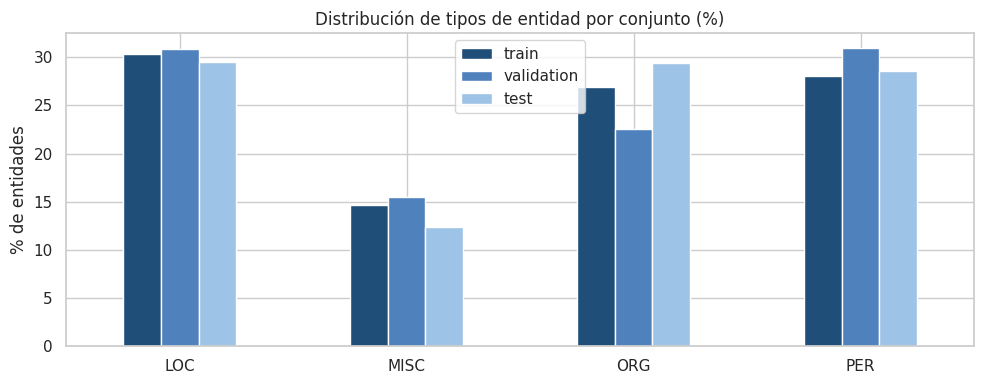

Palabras en train: 203621 | con etiqueta O: 83.3%


In [16]:
conteo_ent = {}
for split, df in df_p2.items():
    tipos = [tipo for toks, ets in zip(df["tokens"], df["etiquetas"]) for *_, tipo in extraer_entidades(toks, ets)]
    conteo_ent[split] = pd.Series(tipos).value_counts()
conteo_ent = pd.DataFrame(conteo_ent)
porcentaje_ent = (conteo_ent / conteo_ent.sum() * 100).round(1)
display(pd.concat([conteo_ent, porcentaje_ent.add_suffix(" (%)")], axis=1))

ax = porcentaje_ent.plot(kind="bar", figsize=(10, 4), rot=0, color=["#1f4e79", "#4f81bd", "#9dc3e6"])
ax.set_title("Distribución de tipos de entidad por conjunto (%)")
ax.set_ylabel("% de entidades"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

todas = [et for ets in df_train_p2["etiquetas"] for et in ets]
print(f"Palabras en train: {len(todas)} | con etiqueta O: {np.mean(np.array(todas) == 'O'):.1%}")

**Observaciones**

- LOC, PER y ORG tienen cantidades parecidas (entre 27 % y 30 %), mientras que MISC es el tipo menos frecuente (cerca de 15 %).
- La proporción es similar en los tres conjuntos, con una diferencia en ORG: 22.6 % en validación frente a 29.4 % en test.
- El 83.3 % de las palabras tiene la etiqueta O. Un modelo que nunca detecte nada tendría 83 % de accuracy, por eso la accuracy por palabra no sirve aquí. Se usa el F1 a nivel de entidad (librería seqeval): una entidad solo cuenta como acierto si el modelo encuentra exactamente todas sus palabras y su tipo.

#### Longitud de los textos

,count,mean,std,min,25%,50%,75%,max
n_palabras,14041.0,14.5,11.6,1.0,6.0,10.0,22.0,113.0
n_entidades,14041.0,1.7,1.5,0.0,1.0,1.0,2.0,20.0


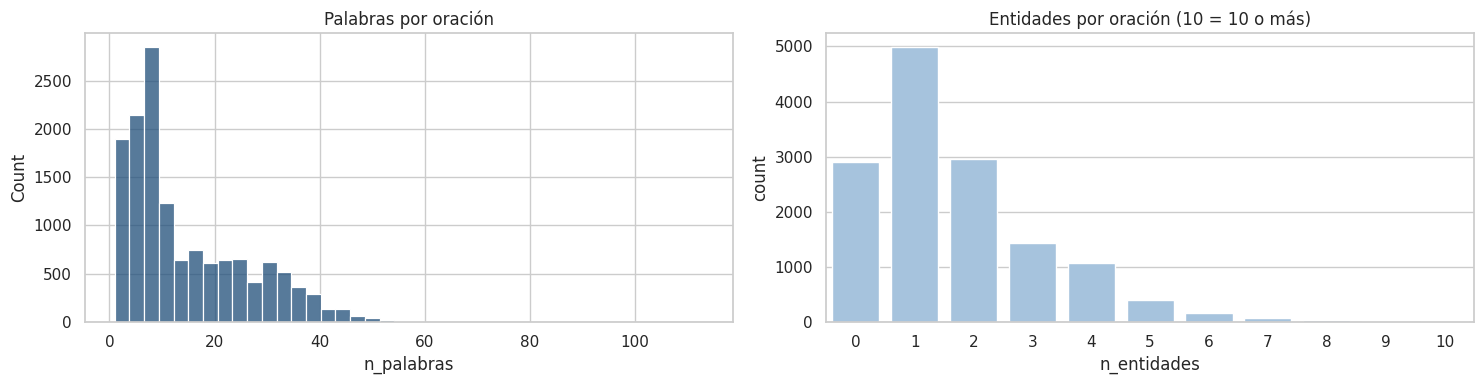

Oraciones sin ninguna entidad: 20.7%


In [17]:
df_train_p2["n_palabras"] = df_train_p2["tokens"].apply(len)
df_train_p2["n_entidades"] = [len(extraer_entidades(t, e)) for t, e in zip(df_train_p2["tokens"], df_train_p2["etiquetas"])]
display(df_train_p2[["n_palabras", "n_entidades"]].describe().round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(df_train_p2["n_palabras"], bins=40, ax=axes[0], color="#1f4e79")
axes[0].set_title("Palabras por oración")
sns.countplot(x=df_train_p2["n_entidades"].clip(upper=10), ax=axes[1], color="#9dc3e6")
axes[1].set_title("Entidades por oración (10 = 10 o más)"); axes[1].set_xlabel("n_entidades")
plt.tight_layout(); plt.show()

print(f"Oraciones sin ninguna entidad: {(df_train_p2['n_entidades'] == 0).mean():.1%}")

**Observaciones**

Las oraciones son cortas: la mitad tiene 10 palabras o menos y el promedio es 14.5, aunque hay algunas de hasta 113. En promedio tienen 1.7 entidades, y el 20.7 % no tiene ninguna. Muchas de las oraciones muy cortas son titulares, fechas o filas de tablas deportivas, típicas de un archivo de noticias.

#### Entidades más frecuentes por tipo

In [18]:
entidades_train = [(texto, tipo) for toks, ets in zip(df_train_p2["tokens"], df_train_p2["etiquetas"])
                   for _, _, texto, tipo in extraer_entidades(toks, ets)]
top_entidades = {}
for tipo in ["PER", "ORG", "LOC", "MISC"]:
    frecuentes = Counter(texto for texto, t in entidades_train if t == tipo).most_common(10)
    top_entidades[tipo] = [f"{texto} ({n})" for texto, n in frecuentes]
display(pd.DataFrame(top_entidades, index=range(1, 11)))

,PER,ORG,LOC,MISC
1,Clinton (70),Reuters (73),U.S. (303),Russian (92)
2,Dole (36),U.N. (35),Germany (141),German (80)
3,Arafat (35),NEW YORK (30),Britain (133),British (73)
4,Yeltsin (32),CHICAGO (30),Australia (130),French (59)
5,Lebed (30),PUK (25),England (123),Dutch (50)
6,Dutroux (30),OSCE (25),France (122),GMT (49)
7,Wasim Akram (29),EU (23),Spain (110),Israeli (48)
8,Waqar Younis (25),NATO (22),Italy (98),English (38)
9,Mushtaq Ahmed (25),European Union (20),LONDON (93),Iraqi (38)
10,Mother Teresa (20),Honda (20),China (91),European (38)


**Observaciones**

Las entidades reflejan la época y la fuente: noticias de Reuters de 1996. Aparecen Clinton y Dole (elecciones de Estados Unidos), Yeltsin, Arafat y jugadores de críquet de Pakistán (Wasim Akram, Waqar Younis).

En ORG aparecen NEW YORK y CHICAGO en mayúsculas: no son las ciudades, sino equipos en las tablas de resultados. En MISC dominan los adjetivos de nacionalidad (Russian, German, British).

Esto significa que el modelo aprenderá nombres de 1996. Una entidad reciente no estará en los datos, y para reconocerla el modelo tendrá que fijarse en el contexto y no en el nombre. Esto se prueba en la demostración final.

#### Entidades ambiguas

Una misma palabra puede ser entidades de tipos distintos según el contexto. Por ejemplo, el nombre de una ciudad puede ser un lugar (LOC) o un equipo deportivo (ORG). Estos casos no se pueden resolver mirando solo la palabra: hace falta entender la oración.

In [19]:
tipos_por_entidad = defaultdict(Counter)
for texto, tipo in entidades_train:
    tipos_por_entidad[texto][tipo] += 1
ambiguas = {texto: dict(c) for texto, c in tipos_por_entidad.items() if len(c) > 1}
print(f"Entidades distintas en train: {len(tipos_por_entidad)} | con más de un tipo: {len(ambiguas)}")

tabla_ambiguas = (pd.DataFrame.from_dict(ambiguas, orient="index").fillna(0).astype(int)
                  .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False).head(12))
display(tabla_ambiguas)

Entidades distintas en train: 8082 | con más de un tipo: 132


,LOC,ORG,PER,MISC,total
NEW YORK,65,30,0,0,95
London,61,5,0,0,66
CHICAGO,29,30,0,0,59
New York,35,9,0,0,44
American,0,1,0,37,38
Chicago,27,5,0,0,32
Jordan,24,7,1,0,32
Washington,26,0,3,0,29
Wimbledon,3,8,0,18,29
TORONTO,13,15,0,0,28


**Observaciones**

Solo 132 de 8.082 entidades distintas (1.6 %) aparecen con más de un tipo, pero son de las más frecuentes. CHICAGO aparece 29 veces como lugar y 30 como equipo; NEW YORK, 65 y 30. Jordan puede ser un país, una organización o una persona, y Wimbledon un lugar, el club o el torneo.

En estos casos una regla que mire solo la palabra siempre se equivocará en una parte de los casos. Es justo donde se espera que BERT supera a la línea base, porque lee la oración completa.

#### Calidad de los datos: duplicados y entidades vistas

Se revisan oraciones repetidas dentro de train y entre conjuntos. En NER además es importante saber cuántas entidades del test ya aparecen en train: un modelo puede acertar una entidad simplemente porque la memorizó, así que lo interesante es ver cómo le va con entidades que nunca vio.

In [20]:
oraciones = {split: df["tokens"].apply(" ".join) for split, df in df_p2.items()}
print(f"Oraciones duplicadas en train:              {oraciones['train'].duplicated().sum()}")
print(f"Oraciones de test que también están en train: {oraciones['test'].isin(set(oraciones['train'])).sum()}")
print(f"Oraciones de validación que están en train:   {oraciones['validation'].isin(set(oraciones['train'])).sum()}")
print("\nOraciones repetidas más frecuentes en train:")
display(oraciones["train"].value_counts().head(8).to_frame("veces"))

entidades_vistas = set(entidades_train)
entidades_test = [(texto, tipo) for toks, ets in zip(df_p2["test"]["tokens"], df_p2["test"]["etiquetas"])
                  for _, _, texto, tipo in extraer_entidades(toks, ets)]
vistas = np.array([e in entidades_vistas for e in entidades_test])
print(f"\nEntidades del test que aparecen en train (mismo texto y tipo): {vistas.mean():.1%}")

Oraciones duplicadas en train:              1350
Oraciones de test que también están en train: 126
Oraciones de validación que están en train:   193

Oraciones repetidas más frecuentes en train:


,veces
tokens,
Scorers :,16
Women 's singles,16
EASTERN DIVISION,16
W L PCT GB,16
CENTRAL DIVISION,16
WESTERN DIVISION,16
"for , against , points ) :",16
Reuters has not verified these stories and does not vouch for their accuracy .,15



Entidades del test que aparecen en train (mismo texto y tipo): 52.5%


**Observaciones**

- Hay 1.350 oraciones duplicadas en train. Las más repetidas son encabezados de tablas deportivas ("EASTERN DIVISION", "W L PCT GB") y la nota legal de Reuters, que se repiten en muchos artículos.
- 126 oraciones de test y 193 de validación también están en train, la mayoría por el mismo motivo.
- El 52.5 % de las entidades del test ya aparece en train con el mismo texto y tipo. Por eso, un buen resultado global puede venir en parte de memorizar nombres. Para separar ese efecto, en la evaluación se mide aparte el desempeño en entidades vistas y en entidades nuevas.

#### **Decisión: no se eliminan los duplicados**

Los duplicados no son errores de anotación: son líneas que se repiten de verdad en las noticias, como encabezados de tablas y notas legales, y casi no tienen entidades. Eliminarlos cambiaría poco el entrenamiento y rompería la partición oficial, que es la que usan todos los trabajos publicados con CoNLL-2003 y permite comparar resultados.

El riesgo real no son las oraciones repetidas sino la memorización de entidades. Ese riesgo se mide de forma explícita en la sección 3.9.

### 3.4 Línea base clásica: etiqueta más frecuente por palabra

Como en el problema 1, primero se entrena un modelo sencillo como punto de comparación. La línea base más común en NER es un **diccionario**: para cada palabra del entrenamiento se guarda la etiqueta que tuvo más veces, y al predecir se asigna esa etiqueta. Las palabras que nunca aparecieron en train se marcan como `O`.

Este modelo no entiende contexto y no puede reconocer entidades nuevas, solo las que memorizó. Por eso sirve para medir cuánto aporta BERT al generalizar.

Las métricas se calculan con `seqeval` a nivel de **entidad**: una entidad cuenta como acierto solo si se detectan exactamente todas sus palabras y el tipo correcto. Detectar "New York" cuando la entidad era "New York Times" en este caso seria un error.

In [21]:
conteo_palabra = defaultdict(Counter)
for toks, ets in zip(df_train_p2["tokens"], df_train_p2["etiquetas"]):
    for palabra, et in zip(toks, ets):
        conteo_palabra[palabra][et] += 1
etiqueta_mas_comun = {palabra: c.most_common(1)[0][0] for palabra, c in conteo_palabra.items()}

def predecir_linea_base(tokens):
    return [etiqueta_mas_comun.get(palabra, "O") for palabra in tokens]

pred_val_base_p2 = [predecir_linea_base(t) for t in df_p2["validation"]["tokens"]]
real_val_p2 = list(df_p2["validation"]["etiquetas"])
print(f"Línea base (validación) | precision: {seqeval_precision(real_val_p2, pred_val_base_p2):.4f} | "
      f"recall: {seqeval_recall(real_val_p2, pred_val_base_p2):.4f} | F1: {seqeval_f1(real_val_p2, pred_val_base_p2):.4f}")

Línea base (validación) | precision: 0.6718 | recall: 0.6365 | F1: 0.6536


**Observaciones**

La línea base obtiene un F1 de 0.6536 en validación sin aprender nada sobre el contexto. Funciona bien con palabras frecuentes que casi siempre tienen la misma etiqueta (U.S., Germany, Clinton), pero tiene dos límites claros:

- Una palabra que no apareció en train se etiqueta siempre como O, así que no puede encontrar entidades nuevas.
- Una palabra ambigua siempre recibe la misma etiqueta, así que CHICAGO será siempre lugar o siempre equipo, sin importar la oración.

### 3.5 Tokenización

Aquí está la principal diferencia con el problema 1. El dataset trae **una etiqueta por palabra**, pero el tokenizador de BERT divide algunas palabras en varios sub-tokens. Hay que decidir qué etiqueta lleva cada sub-token.

La estrategia estándar es:

- El **primer sub-token** de cada palabra recibe la etiqueta de la palabra.
- Los sub-tokens siguientes y los tokens especiales (`[CLS]`, `[SEP]`) reciben `-100`, un valor que PyTorch ignora al calcular la pérdida y que también se ignora en las métricas.


In [22]:
tokenizer_p2 = AutoTokenizer.from_pretrained(P2_MODEL)


def alinear_etiquetas(etiquetas_palabras, word_ids):
    """Etiqueta solo el primer sub-token de cada palabra. El resto y los tokens especiales llevan -100."""
    etiquetas, palabra_anterior = [], None
    for wid in word_ids:
        if wid is None:                       # [CLS], [SEP]
            etiquetas.append(-100)
        elif wid != palabra_anterior:         # primer sub-token de la palabra
            etiquetas.append(etiquetas_palabras[wid])
        else:                                 # sub-tokens siguientes
            etiquetas.append(-100)
        palabra_anterior = wid
    return etiquetas


palabras = ["Zinedine", "Zidane", "joined", "Juventus", "in", "Turin", "."]
etiquetas = ["B-PER", "I-PER", "O", "B-ORG", "O", "B-LOC", "O"]
codificado = tokenizer_p2(palabras, is_split_into_words=True)
alineadas = alinear_etiquetas([label2id_p2[e] for e in etiquetas], codificado.word_ids())
display(pd.DataFrame({
    "token": tokenizer_p2.convert_ids_to_tokens(codificado["input_ids"]),
    "word_id": ["-" if w is None else w for w in codificado.word_ids()],
    "etiqueta": [id2label_p2[e] if e != -100 else -100 for e in alineadas],
}).T)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

,0,1,2,3,4,5,6,7,8,9,10,11,12
token,[CLS],Z,##ined,##ine,Z,##ida,##ne,joined,Juventus,in,Turin,.,[SEP]
word_id,-,0,0,0,1,1,1,2,3,4,5,6,-
etiqueta,-100,B-PER,-100,-100,I-PER,-100,-100,O,B-ORG,O,B-LOC,O,-100


**Observaciones**

"Zinedine" se divide en Z, ##ined y ##ine, y "Zidane" en Z, ##ida y ##ne. Solo el primer sub-token de cada palabra lleva su etiqueta (B-PER e I-PER), y el resto recibe -100 para que no cuente en la pérdida. Palabras comunes como "joined" o "Turin" quedan como un solo token. Los tokens especiales [CLS] y [SEP] también reciben -100.

Así, cada palabra original se evalúa una sola vez, aunque BERT la haya partido en varios pedazos.

#### ¿Qué longitud máxima usar?

Si se trunca una oración, las palabras que quedan por fuera se pierden y sus entidades no se evalúan. Por eso se mide la longitud en sub-tokens y se elige un `max_length` que cubra todas las oraciones. Gracias al padding dinámico, las pocas oraciones largas no hacen más lento el entrenamiento del resto.

,p50,p90,p95,p99,máximo
sub-tokens,17.0,41.0,47.0,58.0,173.0


max_length elegido: 176 sub-tokens (trunca el 0.00% de las oraciones)


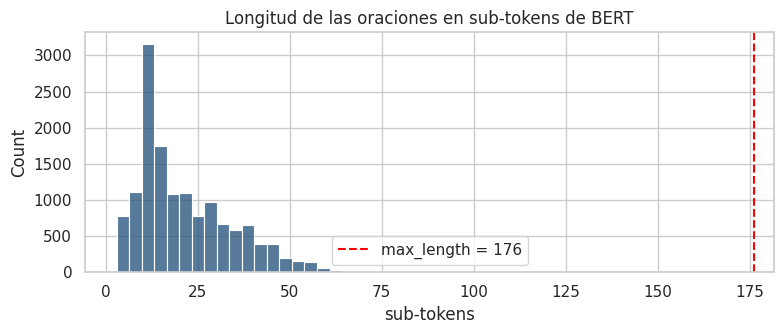

In [23]:
longitudes_p2 = [len(ids) for ids in tokenizer_p2(list(df_train_p2["tokens"]), is_split_into_words=True)["input_ids"]]
percentiles_p2 = np.percentile(longitudes_p2, [50, 90, 95, 99, 100])
display(pd.DataFrame([percentiles_p2], columns=["p50", "p90", "p95", "p99", "máximo"], index=["sub-tokens"]))

P2_MAX_LEN = int(min(256, np.ceil(percentiles_p2[4] / 8) * 8))   # el máximo redondeado a múltiplo de 8
print(f"max_length elegido: {P2_MAX_LEN} sub-tokens "
      f"(trunca el {np.mean(np.array(longitudes_p2) > P2_MAX_LEN):.2%} de las oraciones)")

plt.figure(figsize=(8, 3.5))
sns.histplot(longitudes_p2, bins=50, color="#1f4e79")
plt.axvline(P2_MAX_LEN, color="red", ls="--", label=f"max_length = {P2_MAX_LEN}")
plt.title("Longitud de las oraciones en sub-tokens de BERT"); plt.xlabel("sub-tokens"); plt.legend()
plt.tight_layout(); plt.show()

Se tokenizan los tres conjuntos y se alinean las etiquetas. El `DataCollatorForTokenClassification` hace el padding dinámico tanto de los textos como de las etiquetas (rellena las etiquetas con `-100`).

In [24]:
def tokenizar_p2(batch):
    enc = tokenizer_p2(batch["tokens"], truncation=True, max_length=P2_MAX_LEN, is_split_into_words=True)
    enc["labels"] = [alinear_etiquetas(tags, enc.word_ids(i)) for i, tags in enumerate(batch["ner_tags"])]
    return enc

conll_tok = conll.map(tokenizar_p2, batched=True, remove_columns=conll["train"].column_names)
collator_p2 = DataCollatorForTokenClassification(tokenizer=tokenizer_p2)
print(conll_tok)

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 3453
    })
})


### 3.6 Modelo y métricas

`AutoModelForTokenClassification` carga BERT preentrenado y le agrega una **cabeza de clasificación por token**: una capa lineal que transforma el vector de cada token (768 dimensiones) en 9 puntuaciones, una por etiqueta. Igual que en el problema 1, esa capa empieza con pesos aleatorios.

Métricas que se calculan en validación al final de cada época, con `seqeval`:

- **Precision**: de las entidades que predijo el modelo, cuántas son correctas.
- **Recall**: de las entidades reales, cuántas encontró el modelo.
- **F1 (métrica principal)**: media armónica de precision y recall, a nivel de entidad.
- **Accuracy**: porcentaje de palabras con la etiqueta correcta. Se reporta, pero es engañosa: como la gran mayoría de palabras son `O`, un modelo que nunca detecte nada ya tendría una accuracy alta.

In [25]:
def crear_modelo_p2():
    return AutoModelForTokenClassification.from_pretrained(
        P2_MODEL, num_labels=len(ner_names), id2label=id2label_p2, label2id=label2id_p2
    )


def convertir_predicciones(predicciones, etiquetas):
    """Quita las posiciones -100 y convierte los ids en nombres de etiqueta, como espera seqeval."""
    pred_ids = np.argmax(predicciones, axis=-1)
    y_true, y_pred = [], []
    for fila_pred, fila_real in zip(pred_ids, etiquetas):
        y_true.append([id2label_p2[int(r)] for p, r in zip(fila_pred, fila_real) if r != -100])
        y_pred.append([id2label_p2[int(p)] for p, r in zip(fila_pred, fila_real) if r != -100])
    return y_true, y_pred


def metricas_p2(eval_pred):
    logits, etiquetas = eval_pred
    y_true, y_pred = convertir_predicciones(logits, etiquetas)
    return {
        "precision": seqeval_precision(y_true, y_pred),
        "recall": seqeval_recall(y_true, y_pred),
        "f1": seqeval_f1(y_true, y_pred),
        "accuracy": seqeval_accuracy(y_true, y_pred),
    }


modelo_tmp = crear_modelo_p2()
n_params = sum(p.numel() for p in modelo_tmp.parameters())
print(f"Parámetros del modelo: {n_params / 1e6:.1f} millones")
print("Cabeza de clasificación:", modelo_tmp.classifier)
del modelo_tmp; liberar_memoria()

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Parámetros del modelo: 107.7 millones
Cabeza de clasificación: Linear(in_features=768, out_features=9, bias=True)


La función `entrenar_p2` es equivalente a `entrenar_p1`, con el modelo, el collator y las métricas de NER. El mejor checkpoint se elige por F1 de entidades.

In [26]:
def entrenar_p2(lr, batch_size, train_ds, eval_ds, epocas, output_dir, guardar=False, paciencia=None):
    """Entrena una configuración. Si guardar=True conserva el mejor checkpoint (según F1)."""
    set_seed(SEED)
    args = TrainingArguments(
        output_dir=output_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        num_train_epochs=epocas,
        weight_decay=0.01,
        warmup_steps=0.1,                  # un valor < 1 se interpreta como fracción de los pasos totales (10 %)
        lr_scheduler_type="linear",
        eval_strategy="epoch",
        save_strategy="epoch" if guardar else "no",
        load_best_model_at_end=guardar,
        metric_for_best_model="f1",
        greater_is_better=True,
        save_total_limit=1,
        logging_steps=50,
        fp16=FP16,
        report_to="none",
        seed=SEED,
    )
    callbacks = [EarlyStoppingCallback(early_stopping_patience=paciencia)] if paciencia else None
    trainer = Trainer(
        model=crear_modelo_p2(),
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tokenizer_p2,
        data_collator=collator_p2,
        compute_metrics=metricas_p2,
        callbacks=callbacks,
    )
    inicio = time.time()
    trainer.train()
    return trainer, time.time() - inicio

### 3.7 Búsqueda de hiperparámetros

Se exploran las mismas combinaciones del problema 1 sobre una **muestra aleatoria** de 4.000 oraciones de entrenamiento (cerca del 28 %). Aquí no se puede estratificar como en el problema 1, porque cada oración puede tener varias entidades de distintos tipos. Cada configuración se evalúa en el conjunto de validación completo.

| Hiperparámetro | Valores probados |
|---|---|
| Learning rate | `1e-5`, `2e-5`, `3e-5`, `5e-5`, `1e-4` |
| Batch size | `16`, `32` |
| Épocas | 3 (fijo) |

> Si la sesión de Colab se corta, al volver a ejecutar esta celda las configuraciones ya probadas se cargan desde Drive y no se repiten.

In [27]:
if MODO_PRUEBA:
    P2_TAMANO_MUESTRA, P2_LRS, P2_BATCH_SIZES, P2_EPOCAS_BUSQUEDA = 300, [2e-5, 5e-5], [16], 1
    p2_eval_busqueda = conll_tok["validation"].select(range(200))
else:
    P2_TAMANO_MUESTRA, P2_LRS, P2_BATCH_SIZES, P2_EPOCAS_BUSQUEDA = 4000, [1e-5, 2e-5, 3e-5, 5e-5, 1e-4], [16, 32], 3
    p2_eval_busqueda = conll_tok["validation"]

p2_muestra = conll_tok["train"].shuffle(seed=SEED).select(range(P2_TAMANO_MUESTRA))
print(f"Muestra de entrenamiento: {len(p2_muestra)} oraciones | Validación: {len(p2_eval_busqueda)} oraciones")

Muestra de entrenamiento: 4000 oraciones | Validación: 3250 oraciones


In [28]:
ruta_csv_p2 = os.path.join(P2_DIR, "busqueda_hiperparametros.csv")
ruta_hist_p2 = os.path.join(P2_DIR, "historiales_busqueda.json")
filas_p2, historiales_p2 = cargar_busqueda(ruta_csv_p2, ruta_hist_p2)
ya_probadas_p2 = {(float(f["learning_rate"]), int(f["batch_size"])) for f in filas_p2}

for bs in P2_BATCH_SIZES:
    for lr in P2_LRS:
        if (lr, bs) in ya_probadas_p2:
            print(f"Evaluación: learning_rate={lr:.0e}, batch_size={bs} (ya probado, se omite)")
            continue

        print(f"\n Evaluando: learning_rate={lr:.0e}, batch_size={bs}")
        trainer, segundos = entrenar_p2(lr, bs, p2_muestra, p2_eval_busqueda, P2_EPOCAS_BUSQUEDA,
                                        output_dir=os.path.join("/tmp", "p2_busqueda"))
        _, evals = curvas_desde_historial(trainer.state.log_history)
        mejor = evals.loc[evals["eval_f1"].idxmax()]
        filas_p2.append({
            "learning_rate": lr, "batch_size": bs,
            "f1": mejor["eval_f1"], "precision": mejor["eval_precision"],
            "recall": mejor["eval_recall"], "accuracy": mejor["eval_accuracy"], "eval_loss": mejor["eval_loss"],
            "mejor_epoca": int(round(mejor["epoch"])), "minutos": segundos / 60,
        })
        historiales_p2[f"{lr}_{bs}"] = trainer.state.log_history
        guardar_busqueda(filas_p2, historiales_p2, ruta_csv_p2, ruta_hist_p2)
        del trainer; liberar_memoria()


 Evaluando: learning_rate=1e-05, batch_size=16


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.847', 'grad_norm': '5.426', 'learning_rate': '6.533e-06', 'epoch': '0.2'}
{'loss': '0.5983', 'grad_norm': '1.63', 'learning_rate': '9.644e-06', 'epoch': '0.4'}
{'loss': '0.2818', 'grad_norm': '2.39', 'learning_rate': '8.904e-06', 'epoch': '0.6'}
{'loss': '0.1771', 'grad_norm': '2.062', 'learning_rate': '8.163e-06', 'epoch': '0.8'}
{'loss': '0.1405', 'grad_norm': '1.735', 'learning_rate': '7.422e-06', 'epoch': '1'}
{'eval_loss': '0.1122', 'eval_precision': '0.8113', 'eval_recall': '0.8356', 'eval_f1': '0.8232', 'eval_accuracy': '0.9718', 'eval_runtime': '3.144', 'eval_samples_per_second': '1034', 'eval_steps_per_second': '16.22', 'epoch': '1'}
{'loss': '0.1124', 'grad_norm': '1.774', 'learning_rate': '6.681e-06', 'epoch': '1.2'}
{'loss': '0.09221', 'grad_norm': '1.319', 'learning_rate': '5.941e-06', 'epoch': '1.4'}
{'loss': '0.0708', 'grad_norm': '1.014', 'learning_rate': '5.2e-06', 'epoch': '1.6'}
{'loss': '0.07664', 'grad_norm': '3.286', 'learning_rate': '4.459e-06', 'epoc

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.55', 'grad_norm': '1.887', 'learning_rate': '1.307e-05', 'epoch': '0.2'}
{'loss': '0.3763', 'grad_norm': '1.129', 'learning_rate': '1.929e-05', 'epoch': '0.4'}
{'loss': '0.1667', 'grad_norm': '2.64', 'learning_rate': '1.781e-05', 'epoch': '0.6'}
{'loss': '0.1057', 'grad_norm': '2.255', 'learning_rate': '1.633e-05', 'epoch': '0.8'}
{'loss': '0.0908', 'grad_norm': '1.934', 'learning_rate': '1.484e-05', 'epoch': '1'}
{'eval_loss': '0.07952', 'eval_precision': '0.8773', 'eval_recall': '0.8807', 'eval_f1': '0.879', 'eval_accuracy': '0.9791', 'eval_runtime': '3.999', 'eval_samples_per_second': '812.7', 'eval_steps_per_second': '12.75', 'epoch': '1'}
{'loss': '0.06729', 'grad_norm': '4.063', 'learning_rate': '1.336e-05', 'epoch': '1.2'}
{'loss': '0.05392', 'grad_norm': '1.864', 'learning_rate': '1.188e-05', 'epoch': '1.4'}
{'loss': '0.0413', 'grad_norm': '1.387', 'learning_rate': '1.04e-05', 'epoch': '1.6'}
{'loss': '0.04885', 'grad_norm': '4.418', 'learning_rate': '8.919e-06', 'e

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (11 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '0.9332', 'grad_norm': '1.726', 'learning_rate': '4.837e-05', 'epoch': '0.4'}
{'loss': '0.1239', 'grad_norm': '1.187', 'learning_rate': '4.095e-05', 'epoch': '0.8'}
{'eval_loss': '0.06709', 'eval_precision': '0.8935', 'eval_recall': '0.9019', 'eval_f1': '0.8977', 'eval_accuracy': '0.982', 'eval_runtime': '3.503', 'eval_samples_per_second': '927.9', 'eval_steps_per_second': '14.56', 'epoch': '1'}
{'loss': '0.07333', 'grad_norm': '0.9831', 'learning_rate': '3.353e-05', 'epoch': '1.2'}
{'loss': '0.04248', 'grad_norm': '1', 'learning_rate': '2.611e-05', 'epoch': '1.6'}
{'loss': '0.04312', 'grad_norm': '0.8738', 'learning_rate': '1.869e-05', 'epoch': '2'}
{'eval_loss': '0.05199', 'eval_precision': '0.9069', 'eval_recall': '0.9244', 'eval_f1': '0.9156', 'eval_accuracy': '0.9857', 'eval_runtime': '3.519', 'eval_samples_per_second': '923.6', 'eval_steps_per_second': '14.49', 'epoch': '2'}
{'loss': '0.01974', 'grad_norm': '0.4952', 'learning_rate': '1.128e-05', 'epoch': '2.4'}
{'loss':

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '0.7557', 'grad_norm': '2.006', 'learning_rate': '9.674e-05', 'epoch': '0.4'}
{'loss': '0.1043', 'grad_norm': '1.722', 'learning_rate': '8.19e-05', 'epoch': '0.8'}
{'eval_loss': '0.06793', 'eval_precision': '0.8822', 'eval_recall': '0.8962', 'eval_f1': '0.8891', 'eval_accuracy': '0.9821', 'eval_runtime': '3.591', 'eval_samples_per_second': '905.1', 'eval_steps_per_second': '14.2', 'epoch': '1'}
{'loss': '0.06397', 'grad_norm': '0.9834', 'learning_rate': '6.706e-05', 'epoch': '1.2'}
{'loss': '0.03459', 'grad_norm': '0.9385', 'learning_rate': '5.223e-05', 'epoch': '1.6'}
{'loss': '0.03996', 'grad_norm': '0.8316', 'learning_rate': '3.739e-05', 'epoch': '2'}
{'eval_loss': '0.04939', 'eval_precision': '0.9198', 'eval_recall': '0.9283', 'eval_f1': '0.924', 'eval_accuracy': '0.9869', 'eval_runtime': '3.529', 'eval_samples_per_second': '921', 'eval_steps_per_second': '14.45', 'epoch': '2'}
{'loss': '0.01318', 'grad_norm': '0.1503', 'learning_rate': '2.255e-05', 'epoch': '2.4'}
{'loss'

Evaluando mediante gráficas cuál es el mejor conjunto de hiperparámetros

,learning_rate,batch_size,f1,precision,recall,accuracy,eval_loss,mejor_epoca,minutos
0,1e-04,32,0.9304,0.9254,0.9354,0.9881,0.0493,3,0.8
1,5e-05,16,0.9299,0.9251,0.9349,0.9880,0.0499,3,1.1
2,1e-04,16,0.9280,0.9293,0.9268,0.9870,0.0507,2,1.1
3,5e-05,32,0.9231,0.9185,0.9276,0.9869,0.0498,3,0.8
4,3e-05,16,0.9218,0.9155,0.9281,0.9868,0.0533,3,1.1
5,2e-05,16,0.9184,0.9118,0.9251,0.9862,0.0544,3,1.1
6,3e-05,32,0.9159,0.9108,0.9211,0.9859,0.0531,3,0.8
7,2e-05,32,0.8982,0.8884,0.9083,0.9835,0.0596,3,0.8
8,1e-05,16,0.8935,0.8811,0.9063,0.9827,0.0648,3,1.2
9,1e-05,32,0.8549,0.8412,0.8691,0.9771,0.0863,3,0.8


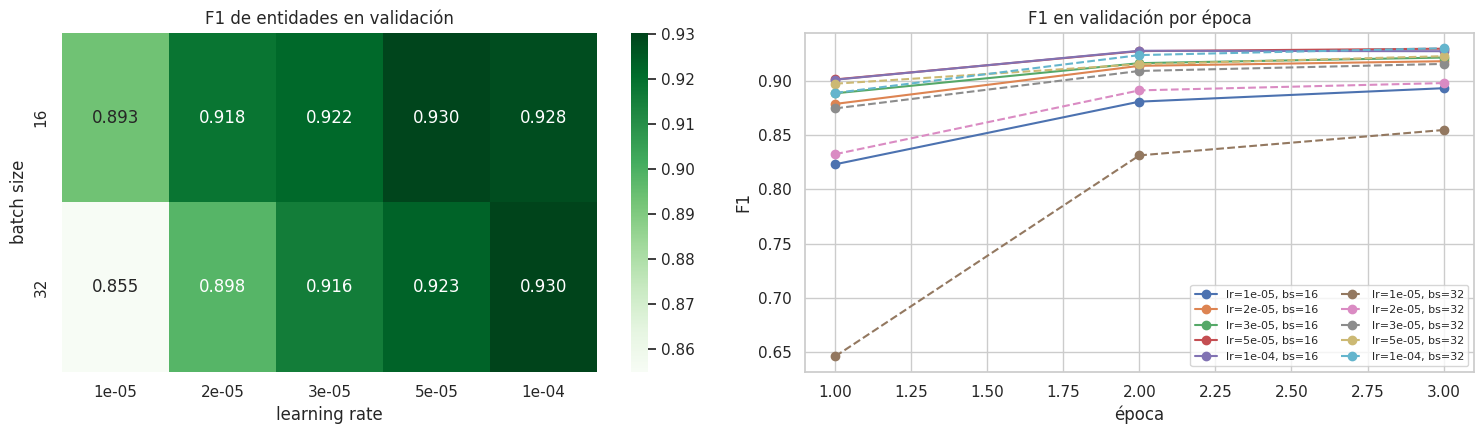


 Mejor configuración: learning rate = 1e-04, batch size = 32, F1 = 0.9304


In [29]:
busqueda_p2 = pd.DataFrame(filas_p2).sort_values("f1", ascending=False).reset_index(drop=True)
display(busqueda_p2.style.format({"learning_rate": "{:.0e}", "f1": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}",
                                  "accuracy": "{:.4f}", "eval_loss": "{:.4f}", "minutos": "{:.1f}"})
        .background_gradient(subset=["f1"], cmap="Greens"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
tabla = busqueda_p2.pivot(index="batch_size", columns="learning_rate", values="f1")
sns.heatmap(tabla, annot=True, fmt=".3f", cmap="Greens", ax=axes[0],
            xticklabels=[f"{c:.0e}" for c in tabla.columns])
axes[0].set_title("F1 de entidades en validación"); axes[0].set_xlabel("learning rate"); axes[0].set_ylabel("batch size")

for clave, log in historiales_p2.items():
    lr, bs = clave.split("_")
    _, ev = curvas_desde_historial(log)
    axes[1].plot(ev["epoch"], ev["eval_f1"], marker="o",
                 ls="-" if bs == str(P2_BATCH_SIZES[0]) else "--", label=f"lr={float(lr):.0e}, bs={bs}")
axes[1].set_title("F1 en validación por época"); axes[1].set_xlabel("época"); axes[1].set_ylabel("F1")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

mejor_p2 = busqueda_p2.iloc[0]
P2_MEJOR_LR, P2_MEJOR_BS = float(mejor_p2["learning_rate"]), int(mejor_p2["batch_size"])
print(f"\n Mejor configuración: learning rate = {P2_MEJOR_LR:.0e}, batch size = {P2_MEJOR_BS}, "
      f"F1 = {mejor_p2['f1']:.4f}")

#### ¿Cómo se interpretan estos resultados?

- La mejor configuración fue learning rate 1e-4 con batch size 32, con un F1 de 0.9304 en validación. Prácticamente empata con 5e-5 y batch 16 (0.9299): una diferencia de 0.0005 está dentro del ruido normal entre entrenamientos.
- Como en el problema 1, el learning rate fue lo más determinante. Con 1e-5 el modelo aprende demasiado lento: 0.89 con batch 16 y 0.85 con batch 32. Con batch 32 apenas llegó a 0.65 después de la primera época.
- Entre 3e-5 y 1e-4 todos los resultados quedan entre 0.916 y 0.930, así que el modelo no es muy sensible al valor exacto dentro de ese rango.
- A diferencia del problema 1, aquí se favorecen learning rates más altos. Con batch 32 el modelo hace la mitad de actualizaciones por época, por eso necesita un learning rate mayor para compensar.
- En casi todas las configuraciones la mejor época fue la última (la 3), así que los modelos seguían mejorando. Esto justifica entrenar más épocas en el entrenamiento final.
- La búsqueda completa (10 configuraciones) tomó cerca de 10 minutos en la T4.

### 3.8 Entrenamiento final con todos los datos

Con la mejor configuración se entrena sobre las **14.041** oraciones:

- Hasta **5 épocas**, evaluando en validación al final de cada una.
- **Early stopping** con paciencia 2: si el F1 en validación no mejora durante 2 épocas seguidas, el entrenamiento se detiene.
- Al terminar se **restaura el checkpoint de la mejor época** (`load_best_model_at_end`).

In [30]:
if MODO_PRUEBA:
    p2_train, p2_val, p2_test = (conll_tok["train"].select(range(600)),
                                 conll_tok["validation"].select(range(200)),
                                 conll_tok["test"].select(range(200)))
    P2_EPOCAS_FINAL = 1
else:
    p2_train, p2_val, p2_test = conll_tok["train"], conll_tok["validation"], conll_tok["test"]
    P2_EPOCAS_FINAL = 5

dir_checkpoints_p2 = os.path.join(P2_DIR, "checkpoints")
trainer_p2, segundos_p2 = entrenar_p2(P2_MEJOR_LR, P2_MEJOR_BS, p2_train, p2_val, P2_EPOCAS_FINAL,
                                      output_dir=dir_checkpoints_p2, guardar=True, paciencia=2)
print(f"Entrenamiento final completado en {segundos_p2 / 60:.1f} minutos")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.286', 'grad_norm': '1.006', 'learning_rate': '2.227e-05', 'epoch': '0.1139'}
{'loss': '0.2225', 'grad_norm': '1.255', 'learning_rate': '4.5e-05', 'epoch': '0.2278'}
{'loss': '0.09677', 'grad_norm': '1.653', 'learning_rate': '6.773e-05', 'epoch': '0.3417'}
{'loss': '0.07203', 'grad_norm': '2.082', 'learning_rate': '9.045e-05', 'epoch': '0.4556'}
{'loss': '0.07759', 'grad_norm': '1.14', 'learning_rate': '9.853e-05', 'epoch': '0.5695'}
{'loss': '0.05994', 'grad_norm': '0.9451', 'learning_rate': '9.6e-05', 'epoch': '0.6834'}
{'loss': '0.05676', 'grad_norm': '0.8806', 'learning_rate': '9.347e-05', 'epoch': '0.7973'}
{'loss': '0.051', 'grad_norm': '1.083', 'learning_rate': '9.094e-05', 'epoch': '0.9112'}
{'eval_loss': '0.04709', 'eval_precision': '0.9193', 'eval_recall': '0.9216', 'eval_f1': '0.9204', 'eval_accuracy': '0.987', 'eval_runtime': '3.427', 'eval_samples_per_second': '948.5', 'eval_steps_per_second': '14.88', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.04655', 'grad_norm': '0.6671', 'learning_rate': '8.841e-05', 'epoch': '1.025'}
{'loss': '0.0296', 'grad_norm': '0.5958', 'learning_rate': '8.587e-05', 'epoch': '1.139'}
{'loss': '0.03169', 'grad_norm': '0.09604', 'learning_rate': '8.334e-05', 'epoch': '1.253'}
{'loss': '0.03253', 'grad_norm': '0.9062', 'learning_rate': '8.081e-05', 'epoch': '1.367'}
{'loss': '0.03252', 'grad_norm': '0.5015', 'learning_rate': '7.828e-05', 'epoch': '1.481'}
{'loss': '0.0317', 'grad_norm': '0.7376', 'learning_rate': '7.575e-05', 'epoch': '1.595'}
{'loss': '0.02794', 'grad_norm': '1.139', 'learning_rate': '7.322e-05', 'epoch': '1.708'}
{'loss': '0.02784', 'grad_norm': '1.527', 'learning_rate': '7.068e-05', 'epoch': '1.822'}
{'loss': '0.03176', 'grad_norm': '0.542', 'learning_rate': '6.815e-05', 'epoch': '1.936'}
{'eval_loss': '0.03968', 'eval_precision': '0.9348', 'eval_recall': '0.9458', 'eval_f1': '0.9403', 'eval_accuracy': '0.99', 'eval_runtime': '3.633', 'eval_samples_per_second': '894.5', 

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.01758', 'grad_norm': '0.04714', 'learning_rate': '6.562e-05', 'epoch': '2.05'}
{'loss': '0.01514', 'grad_norm': '0.4857', 'learning_rate': '6.309e-05', 'epoch': '2.164'}
{'loss': '0.01566', 'grad_norm': '0.3844', 'learning_rate': '6.056e-05', 'epoch': '2.278'}
{'loss': '0.01189', 'grad_norm': '0.2159', 'learning_rate': '5.803e-05', 'epoch': '2.392'}
{'loss': '0.01015', 'grad_norm': '1.002', 'learning_rate': '5.549e-05', 'epoch': '2.506'}
{'loss': '0.01048', 'grad_norm': '0.2441', 'learning_rate': '5.296e-05', 'epoch': '2.62'}
{'loss': '0.01462', 'grad_norm': '0.4517', 'learning_rate': '5.043e-05', 'epoch': '2.733'}
{'loss': '0.01333', 'grad_norm': '0.144', 'learning_rate': '4.79e-05', 'epoch': '2.847'}
{'loss': '0.01059', 'grad_norm': '0.922', 'learning_rate': '4.537e-05', 'epoch': '2.961'}
{'eval_loss': '0.04337', 'eval_precision': '0.9392', 'eval_recall': '0.9482', 'eval_f1': '0.9436', 'eval_accuracy': '0.9901', 'eval_runtime': '3.864', 'eval_samples_per_second': '841.1',

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.001567', 'grad_norm': '0.006917', 'learning_rate': '2.005e-05', 'epoch': '4.1'}
{'loss': '0.003088', 'grad_norm': '0.4757', 'learning_rate': '1.752e-05', 'epoch': '4.214'}
{'loss': '0.003184', 'grad_norm': '0.341', 'learning_rate': '1.499e-05', 'epoch': '4.328'}
{'loss': '0.001634', 'grad_norm': '0.006083', 'learning_rate': '1.246e-05', 'epoch': '4.442'}
{'loss': '0.001839', 'grad_norm': '0.1221', 'learning_rate': '9.924e-06', 'epoch': '4.556'}
{'loss': '0.00126', 'grad_norm': '0.006411', 'learning_rate': '7.392e-06', 'epoch': '4.67'}
{'loss': '0.002898', 'grad_norm': '0.1113', 'learning_rate': '4.861e-06', 'epoch': '4.784'}
{'loss': '0.002539', 'grad_norm': '0.01815', 'learning_rate': '2.329e-06', 'epoch': '4.897'}
{'eval_loss': '0.04548', 'eval_precision': '0.9453', 'eval_recall': '0.9542', 'eval_f1': '0.9497', 'eval_accuracy': '0.9912', 'eval_runtime': '3.707', 'eval_samples_per_second': '876.7', 'eval_steps_per_second': '13.76', 'epoch': '5'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '301.2', 'train_samples_per_second': '233.1', 'train_steps_per_second': '7.288', 'train_loss': '0.05476', 'epoch': '5'}
Entrenamiento final completado en 5.0 minutos


#### Curvas de aprendizaje

- La pérdida de entrenamiento cae muy rápido en la primera época y termina cerca de 0.002.
- La pérdida de validación es mínima en la época 2 (0.040) y luego sube un poco (0.046 en la época 5). Indica que el modelo se vuelve más seguro de sus predicciones, incluidas algunas incorrectas.
- Aun así, el F1 en validación mejoró en todas las épocas: 0.920, 0.940, 0.944, 0.947 y 0.950. Por eso el early stopping nunca se activó y el mejor modelo fue el de la época 5.
- Que la pérdida suba mientras el F1 mejora muestra por qué el mejor modelo se elige con la métrica de interés y no con la pérdida.
- El entrenamiento completo tomó 5 minutos. Como el F1 seguía subiendo, es posible que una o dos épocas más dieran una pequeña mejora.

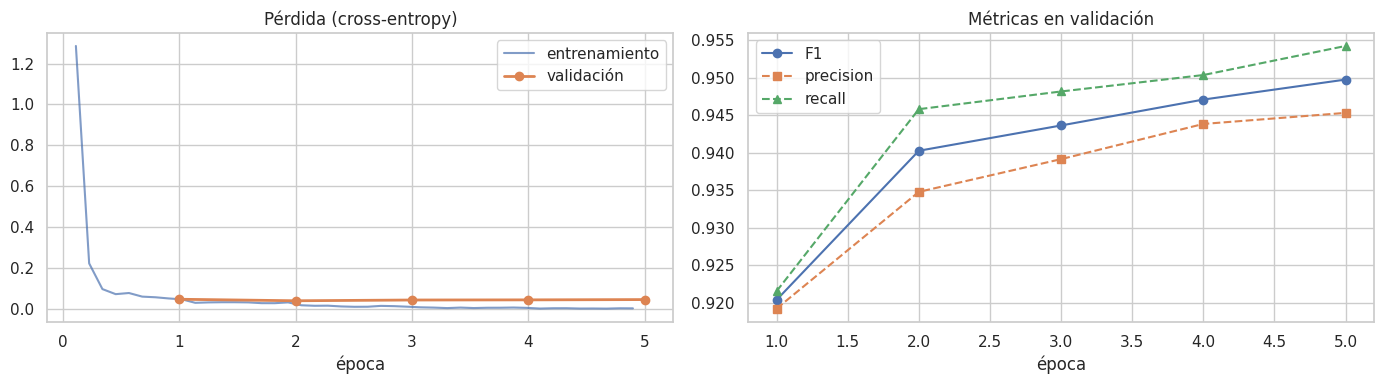

,epoch,eval_loss,eval_precision,eval_recall,eval_f1,eval_accuracy
8,1.0,0.0471,0.9193,0.9216,0.9204,0.9870
18,2.0,0.0397,0.9348,0.9458,0.9403,0.9900
28,3.0,0.0434,0.9392,0.9482,0.9436,0.9901
38,4.0,0.0441,0.9438,0.9504,0.9471,0.9909
47,5.0,0.0455,0.9453,0.9542,0.9497,0.9912


In [31]:
curva_train_p2, curva_val_p2 = curvas_desde_historial(trainer_p2.state.log_history)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(curva_train_p2["epoch"], curva_train_p2["loss"], label="entrenamiento", alpha=0.7)
axes[0].plot(curva_val_p2["epoch"], curva_val_p2["eval_loss"], "o-", label="validación", lw=2)
axes[0].set_title("Pérdida (cross-entropy)"); axes[0].set_xlabel("época"); axes[0].legend()
axes[1].plot(curva_val_p2["epoch"], curva_val_p2["eval_f1"], "o-", label="F1")
axes[1].plot(curva_val_p2["epoch"], curva_val_p2["eval_precision"], "s--", label="precision")
axes[1].plot(curva_val_p2["epoch"], curva_val_p2["eval_recall"], "^--", label="recall")
axes[1].set_title("Métricas en validación"); axes[1].set_xlabel("época"); axes[1].legend()
plt.tight_layout(); plt.show()

display(curva_val_p2[["epoch", "eval_loss", "eval_precision", "eval_recall", "eval_f1", "eval_accuracy"]].round(4))

### 3.9 Evaluación en el conjunto de prueba (test)

Ahora, se evalúa en las 3.453 oraciones de test, que el modelo nunca vio y que no se usaron para tomar ninguna decisión.

In [32]:
salida_test_p2 = trainer_p2.predict(p2_test)
y_true_p2, y_pred_p2 = convertir_predicciones(salida_test_p2.predictions, salida_test_p2.label_ids)

df_test_p2 = df_p2["test"].iloc[: len(p2_test)].copy()
pred_test_base_p2 = [predecir_linea_base(t) for t in df_test_p2["tokens"]]
real_test_p2 = list(df_test_p2["etiquetas"])

comparacion_p2 = pd.DataFrame({
    "Línea base (etiqueta más frecuente)": [seqeval_precision(real_test_p2, pred_test_base_p2),
                                            seqeval_recall(real_test_p2, pred_test_base_p2),
                                            seqeval_f1(real_test_p2, pred_test_base_p2)],
    f"{P2_MODEL} (fine-tuned)": [seqeval_precision(y_true_p2, y_pred_p2),
                                 seqeval_recall(y_true_p2, y_pred_p2),
                                 seqeval_f1(y_true_p2, y_pred_p2)],
}, index=["precision", "recall", "f1"]).T
display(comparacion_p2.style.format("{:.4f}").highlight_max(color="#0a8021"))

print(seqeval_report(y_true_p2, y_pred_p2, digits=4))

,precision,recall,f1
Línea base (etiqueta más frecuente),0.5936,0.5103,0.5488
bert-base-cased (fine-tuned),0.8936,0.9145,0.9039


              precision    recall  f1-score   support

         LOC     0.9265    0.9299    0.9282      1668
        MISC     0.7628    0.8291    0.7945       702
         ORG     0.8674    0.8983    0.8826      1661
         PER     0.9489    0.9524    0.9506      1617

   micro avg     0.8936    0.9145    0.9039      5648
   macro avg     0.8764    0.9024    0.8890      5648
weighted avg     0.8952    0.9145    0.9046      5648



F1 por tipo de entidad, línea base frente a BERT:

In [33]:
reporte_base = seqeval_report(real_test_p2, pred_test_base_p2, output_dict=True)
reporte_bert = seqeval_report(y_true_p2, y_pred_p2, output_dict=True)
f1_por_tipo = pd.DataFrame({
    "Línea base": {t: reporte_base[t]["f1-score"] for t in ["PER", "ORG", "LOC", "MISC"]},
    "BERT": {t: reporte_bert[t]["f1-score"] for t in ["PER", "ORG", "LOC", "MISC"]},
})
display(f1_por_tipo.style.format("{:.4f}"))

,Línea base,BERT
PER,0.2934,0.9506
ORG,0.5112,0.8826
LOC,0.7481,0.9282
MISC,0.6283,0.7945


#### Comparación con la línea base

| Modelo | Precision | Recall | F1 |
|---|---|---|---|
| Etiqueta más frecuente por palabra | 0.5936 | 0.5103 | 0.5488 |
| bert-base-cased (fine-tuned) | 0.8936 | 0.9145 | 0.9039 |


- BERT pasa de 0.55 a 0.90 de F1 y reduce los errores en cerca de 80 %. La diferencia es mucho mayor que en el problema 1, porque aquí el contexto importa mucho más.
- La mayor mejora está en PER: de 0.29 a 0.95. Los nombres de personas casi no se repiten entre noticias, así que un diccionario no los conoce, mientras que BERT los reconoce por su forma y su contexto ("said", "Mr.", mayúsculas).
- MISC es el tipo más difícil para BERT (0.79), porque agrupa cosas muy distintas: nacionalidades, eventos, idiomas y otros nombres.
- El F1 en test (0.904) es menor que en validación (0.950). Es un fenómeno conocido de CoNLL-2003: los artículos de test son de un período posterior (diciembre de 1996) y tienen más nombres nuevos. Como referencia, el artículo original de BERT reporta 0.924 con bert-base, pero usando todo el documento como contexto y no solo la oración.

#### Entidades vistas frente a entidades nuevas

Se separan las entidades del test en dos grupos: las que ya aparecían en train con el mismo texto y tipo, y las que el modelo nunca vio. Para cada grupo se mide el recall: qué porcentaje de esas entidades se detectó de forma exacta.

In [34]:
def recall_vistas_nuevas(tokens_lista, reales, predichas):
    filas = []
    for tokens, real, pred in zip(tokens_lista, reales, predichas):
        tokens = list(tokens)[: len(real)]
        spans_pred = {(ini, fin, tipo) for ini, fin, _, tipo in extraer_entidades(tokens, pred)}
        for ini, fin, texto, tipo in extraer_entidades(tokens, real):
            filas.append({"vista_en_train": (texto, tipo) in entidades_vistas,
                          "acierto": (ini, fin, tipo) in spans_pred})
    return pd.DataFrame(filas).groupby("vista_en_train")["acierto"].agg(["count", "mean"])

recall_grupos = pd.concat({
    "Línea base": recall_vistas_nuevas(df_test_p2["tokens"], real_test_p2, pred_test_base_p2)["mean"],
    "BERT": recall_vistas_nuevas(df_test_p2["tokens"], y_true_p2, y_pred_p2)["mean"],
    "entidades": recall_vistas_nuevas(df_test_p2["tokens"], y_true_p2, y_pred_p2)["count"],
}, axis=1).rename(index={True: "vistas en train", False: "nuevas"})
display(recall_grupos.style.format({"Línea base": "{:.1%}", "BERT": "{:.1%}"}))

,Línea base,BERT,entidades
vista_en_train,,,
nuevas,9.6%,86.6%,2685
vistas en train,88.6%,95.9%,2963


**Observaciones**

| Grupo | Entidades | Línea base | BERT |
|---|---|---|---|
| Vistas en train | 2.963 | 88.6 % | 95.9 % |
| Nuevas | 2.685 | 9.6 % | 86.6 % |

Esta es la diferencia más importante entre los dos modelos. La línea base solo funciona con lo que memorizó: detecta el 88.6 % de las entidades conocidas pero apenas el 9.6 % de las nuevas. BERT encuentra el 86.6 % de las entidades que nunca vio, así que aprendió patrones generales (cómo se escribe y en qué contexto aparece un nombre) y no solo una lista de nombres.

Las entidades vistas siguen siendo más fáciles también para BERT (95.9 %), así que la memorización ayuda, pero no explica el resultado.

#### Matriz de confusión

Se construye a nivel de palabra, agrupando `B-` e `I-` por tipo de entidad. Cada fila es el tipo **real** y cada columna el **predicho**. La fila y la columna `O` muestran las entidades que el modelo no detectó y las palabras normales que marcó como entidad.

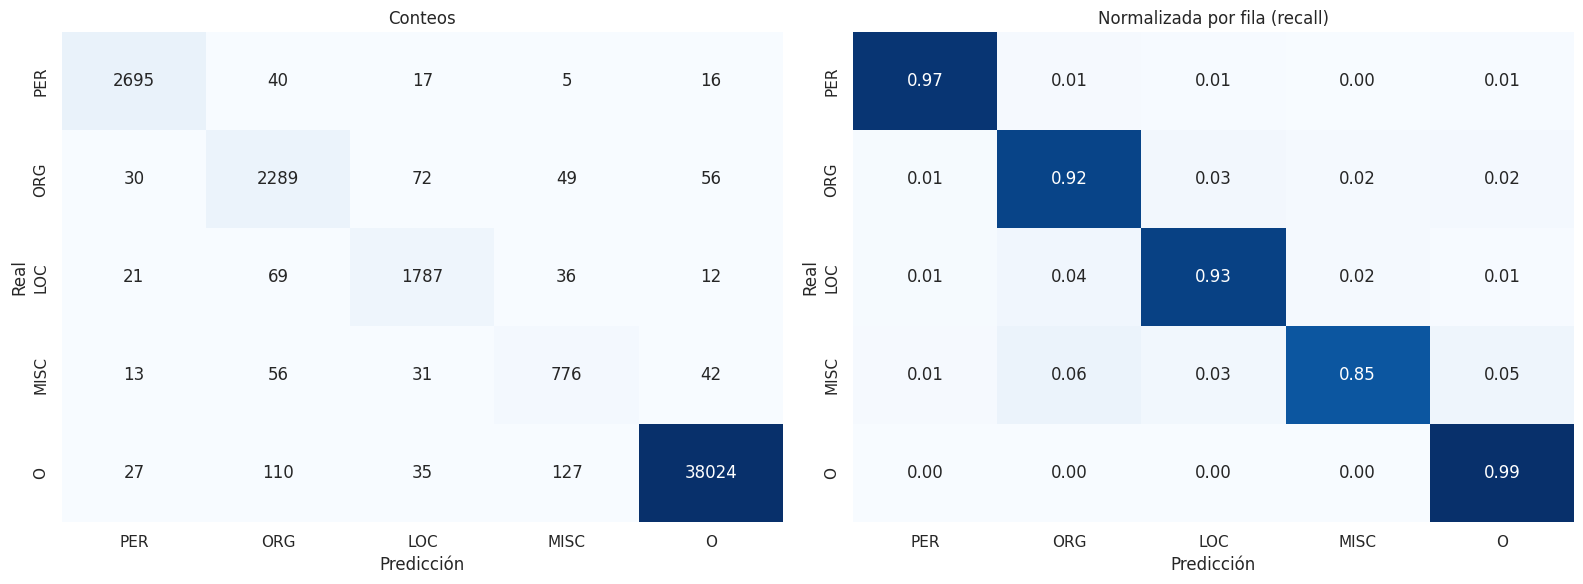

In [35]:
tipo_de = lambda et: et[2:] if et != "O" else "O"
tipos_cm = ["PER", "ORG", "LOC", "MISC", "O"]
plano_real = [tipo_de(e) for oracion in y_true_p2 for e in oracion]
plano_pred = [tipo_de(e) for oracion in y_pred_p2 for e in oracion]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (normalizar, titulo, formato) in zip(axes, [(None, "Conteos", "d"), ("true", "Normalizada por fila (recall)", ".2f")]):
    cm = confusion_matrix(plano_real, plano_pred, labels=tipos_cm, normalize=normalizar)
    sns.heatmap(cm, annot=True, fmt=formato, cmap="Blues", xticklabels=tipos_cm, yticklabels=tipos_cm, ax=ax, cbar=False)
    ax.set_title(titulo); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

**Observaciones**

- PER es el tipo más fácil: el 97 % de sus palabras se etiqueta bien.
- La confusión más común es entre ORG y LOC, en ambas direcciones (72 y 69 palabras). Corresponde al caso ya visto en el análisis exploratorio: una ciudad que también es el nombre de un equipo.
- MISC tiene el recall más bajo (85 %) y se confunde con ORG y con O.
- La fila O muestra que el modelo también marca como entidad palabras que no lo son, sobre todo como MISC (127) y ORG (110). Por eso la precision de MISC (0.76) es más baja que su recall.

#### Análisis de errores

Se revisan las palabras mal etiquetadas: cuáles son las confusiones más comunes y algunos ejemplos de oraciones con errores, comparando la anotación real con la predicción.

In [36]:
errores_palabra = []
oraciones_con_error = []
for i, (real, pred) in enumerate(zip(y_true_p2, y_pred_p2)):
    tokens = list(df_test_p2["tokens"].iloc[i])[: len(real)]
    for palabra, r, p in zip(tokens, real, pred):
        if r != p:
            errores_palabra.append({"palabra": palabra, "real": r, "prediccion": p})
    if real != pred:
        oraciones_con_error.append(i)

errores_p2 = pd.DataFrame(errores_palabra)
print(f"Oraciones con al menos un error: {len(oraciones_con_error)} de {len(y_true_p2)} "
      f"({len(oraciones_con_error) / len(y_true_p2):.1%})")
print(f"Palabras mal etiquetadas: {len(errores_p2)} de {len(plano_real)} ({len(errores_p2) / len(plano_real):.2%})")

print("\nConfusiones más frecuentes:")
display(errores_p2.assign(real=errores_p2["real"].map(tipo_de), prediccion=errores_p2["prediccion"].map(tipo_de))
        .value_counts(["real", "prediccion"]).head(10).to_frame("palabras"))

print("Ejemplos de oraciones con errores:")
rng = np.random.default_rng(SEED)
for i in rng.choice(oraciones_con_error, size=min(8, len(oraciones_con_error)), replace=False):
    tokens = list(df_test_p2["tokens"].iloc[i])[: len(y_true_p2[i])]
    print(f"\nReal:       {resaltar(tokens, y_true_p2[i])}")
    print(f"Predicción: {resaltar(tokens, y_pred_p2[i])}")

Oraciones con al menos un error: 537 de 3453 (15.6%)
Palabras mal etiquetadas: 901 de 46435 (1.94%)

Confusiones más frecuentes:


palabras
real prediccion          
O    MISC             127
     ORG              110
ORG  LOC               72
LOC  ORG               69
MISC ORG               56
ORG  O                 56
     MISC              49
MISC O                 42
PER  ORG               40
LOC  MISC              36

Ejemplos de oraciones con errores:

Real:       [PACIFIC](LOC) DIVISION
Predicción: [PACIFIC DIVISION](MISC)

Real:       [NZ](LOC) 's [Bolger](PER) says [Nats](PER) to meet [NZ](LOC) First on Sunday .
Predicción: [NZ](LOC) 's [Bolger](PER) says [Nats](PER) to meet [NZ First](ORG) on Sunday .

Real:       ( [Newcastle](ORG) )
Predicción: ( [Newcastle](LOC) )

Real:       Supporters of the three pacts say they are only an extension of existing intellectual property rights , covered by the century-old [Berne Convention](MISC) .
Predicción: Supporters of the three pacts say they are only an extension of existing intellectual property rights , covered by the century-old [Berne Convention](ORG) .

Real:       Sunseeds 219 216 220 216
Predicción: [Sunseeds](ORG) 219 216 220 216

Real:       [SANTIAGO](PER) 1996-12-05
Predicción: [SANTIAGO](LOC) 1996-12-05

Real:       [TORONTO](ORG) AT [NY RANGERS](ORG)
Predicción: [TORONTO](ORG) AT [NY RANGERS](LOC)

Real:       " In the coming five to ten 

**Observaciones**

El modelo comete al menos un error en 537 de 3.453 oraciones (15.6 %), pero solo se equivoca en el 1.94 % de las palabras. Los errores se concentran en pocas palabras por oración.

Algunos errores no son del modelo sino de la anotación o de casos discutibles:

- "SANTIAGO 1996-12-05" está anotado como PER, pero es la ciudad desde donde se envió la noticia. El modelo predice LOC, que es lo correcto.
- En "NZ First" la anotación marca solo "NZ" como lugar, pero NZ First es un partido político. El modelo lo detecta completo como ORG, que es una interpretación razonable.

Otros sí son errores reales del modelo:

- En las tablas deportivas faltan pistas de contexto: "Newcastle" (el equipo) se predice como lugar y "NY RANGERS" como lugar.
- "Ahold said" se predice como persona: el verbo "said" suele ir después de nombres de personas.
- "Berne Convention" se predice como ORG en lugar de MISC: la frontera entre ambos tipos no siempre es clara.

### 3.10 Guardar y demostrar el mejor modelo

Se guarda el modelo final y se prueba con `pipeline("token-classification")` sobre frases nuevas. Con `aggregation_strategy="simple"` el pipeline une los sub-tokens y las etiquetas B-/I- en entidades completas.

Las frases incluyen casos difíciles a propósito: una palabra ambigua ("Jordan" como persona y como país) y una frase escrita toda en minúsculas, para ver qué tanto depende el modelo de las mayúsculas.

In [37]:
P2_MEJOR_DIR = os.path.join(P2_DIR, "mejor_modelo")
trainer_p2.save_model(P2_MEJOR_DIR)          # guarda pesos, configuración (id2label) y tokenizador
shutil.rmtree(dir_checkpoints_p2, ignore_errors=True)

etiquetador = pipeline("token-classification", model=P2_MEJOR_DIR, aggregation_strategy="simple",
                       device=0 if torch.cuda.is_available() else -1)

frases_nuevas_p2 = [
    "Lionel Messi scored twice for Inter Miami against the New York Red Bulls on Saturday.",
    "The United Nations held an emergency meeting in Geneva about the crisis in Sudan.",
    "Elon Musk said Tesla will open a new factory in Monterrey, Mexico.",
    "Michael Jordan was born in Brooklyn, while Jordan is a country in the Middle East.",
    "The University of Antioquia is located in Medellin, Colombia.",
    "barack obama visited paris and met with the french president.",
]
filas = []
for frase, entidades in zip(frases_nuevas_p2, etiquetador(frases_nuevas_p2)):
    filas.append({"frase": frase,
                  "entidades": ", ".join(f"{e['word']} ({e['entity_group']}, {e['score']:.0%})" for e in entidades) or "(ninguna)"})
display(pd.DataFrame(filas))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,frase,entidades
0,Lionel Messi scored twice for Inter Miami against the New York Red Bulls on Saturday.,"Lionel Messi (PER, 100%), Inter Miami (ORG, 100%), New York Red Bulls (ORG, 100%)"
1,The United Nations held an emergency meeting in Geneva about the crisis in Sudan.,"United Nations (ORG, 100%), Geneva (LOC, 100%), Sudan (LOC, 100%)"
2,"Elon Musk said Tesla will open a new factory in Monterrey, Mexico.","El (ORG, 66%), ##on (PER, 89%), Musk (ORG, 73%), Tesla (ORG, 98%), Monterrey (LOC, 100%), Mexico (LOC, 100%)"
3,"Michael Jordan was born in Brooklyn, while Jordan is a country in the Middle East.","Michael Jordan (PER, 100%), Brooklyn (LOC, 100%), Jordan (LOC, 100%), Middle East (LOC, 100%)"
4,"The University of Antioquia is located in Medellin, Colombia.","University of Antioquia (ORG, 99%), Medellin (LOC, 100%), Colombia (LOC, 100%)"
5,barack obama visited paris and met with the french president.,(ninguna)


**Observaciones**

- Detecta bien entidades que no existían en 1996: Lionel Messi, Inter Miami y New York Red Bulls, todas con 100 % de confianza. Confirma que generaliza más allá de los nombres que vio.
- Resuelve la ambigüedad de "Jordan": Michael Jordan como persona y Jordan como país, usando el contexto de cada parte de la oración.
- Reconoce entidades colombianas: University of Antioquia (ORG), Medellin y Colombia (LOC).
- Falla con "Elon Musk": parte "Elon" en sub-tokens y los etiqueta con tipos distintos (El como ORG, ##on como PER). Es una limitación de cómo se juntan los sub-tokens en la demostración. Usar `aggregation_strategy="first"`, que toma la etiqueta del primer sub-token igual que en el entrenamiento, lo evita.
- Con la frase toda en minúsculas ("barack obama visited paris...") no detecta ninguna entidad. El modelo depende mucho de las mayúsculas, lo que es una limitación para textos informales como tweets o mensajes de chat.

In [38]:
guardar_resultado("p2_ner", {
    "modelo": P2_MODEL,
    "mejor_learning_rate": P2_MEJOR_LR,
    "mejor_batch_size": P2_MEJOR_BS,
    "epocas_entrenadas": float(curva_val_p2["epoch"].max()),
    "minutos_entrenamiento": round(segundos_p2 / 60, 1),
    "test_precision": float(seqeval_precision(y_true_p2, y_pred_p2)),
    "test_recall": float(seqeval_recall(y_true_p2, y_pred_p2)),
    "test_f1": float(seqeval_f1(y_true_p2, y_pred_p2)),
    "linea_base_test_f1": float(seqeval_f1(real_test_p2, pred_test_base_p2)),
})
del trainer_p2, etiquetador; liberar_memoria()
print(json.dumps(json.load(open(RUTA_RESULTADOS))["p2_ner"], indent=2))

{
  "modelo": "bert-base-cased",
  "mejor_learning_rate": 0.0001,
  "mejor_batch_size": 32,
  "epocas_entrenadas": 5.0,
  "minutos_entrenamiento": 5.0,
  "test_precision": 0.893598615916955,
  "test_recall": 0.9144830028328612,
  "test_f1": 0.9039201960098004,
  "linea_base_test_f1": 0.5487955822146053
}


### 3.11 Conclusiones del Problema 2

1. La mejor configuración fue learning rate 1e-4 con batch size 32, prácticamente empatada con 5e-5 y batch 16. Como en el problema 1, el learning rate fue lo más importante: con 1e-5 el modelo aprendió demasiado lento, y entre 3e-5 y 1e-4 los resultados fueron similares.
2. El modelo final, entrenado 5 épocas en 5 minutos en una GPU T4, obtuvo en test un F1 de 0.904 a nivel de entidad, frente a 0.549 de la línea base. El fine-tuning redujo los errores en cerca de 80 %.
3. La ventaja principal de BERT es que generaliza: detecta el 86.6 % de las entidades que nunca vio en el entrenamiento, frente al 9.6 % de la línea base.
4. Los tipos más difíciles fueron MISC (F1 0.79) y ORG (0.88). La confusión principal es entre ciudades y equipos deportivos, que solo se distinguen por el contexto.
5. Limitaciones:
   - El modelo depende de las mayúsculas: con un texto en minúsculas no detectó ninguna entidad.
   - Los datos son noticias de 1996 en inglés, así que el desempeño puede bajar en otros dominios o en textos informales.
   - Parte de los errores del test son errores de la anotación original, como "SANTIAGO" marcado como persona.

# 4. Dataset 3 - Traducción automática inglés-español

### 4.1 Descripción del dataset

El tercer problema es de tipo **secuencia a secuencia (seq2seq)**: la entrada es un texto y la salida es otro texto, de longitud distinta. En este caso la tarea es traducir oraciones del inglés al español.

Para esta tarea se usa un modelo **encoder-decoder**. El encoder lee la oración en inglés y la convierte en vectores; el decoder genera la traducción en español palabra por palabra (token por token), mirando en cada paso lo que lleva escrito y la oración original.

Se usa `Helsinki-NLP/opus-mt-en-es`, un modelo MarianMT que ya traduce de inglés a español: fue entrenado por la Universidad de Helsinki con millones de oraciones de OPUS, una colección de textos paralelos de la web, subtítulos, documentos oficiales, etc. Por eso, a diferencia de los problemas 1 y 2, aquí el fine-tuning no enseña la tarea desde cero: **adapta un traductor general a un dominio específico**, la literatura clásica.

| Aspecto | Descripción |
|---|---|
| Nombre | OPUS Books, disponible en Hugging Face como `Helsinki-NLP/opus_books` (par `en-es`) |
| Origen | Tiedemann (2012), "Parallel Data, Tools and Interfaces in OPUS". Las oraciones se alinearon automáticamente a partir de libros de dominio público y sus traducciones |
| Dominio | Novelas clásicas: Jane Eyre, Anna Karenina, Los tres mosqueteros, Sherlock Holmes, Julio Verne, entre otras |
| Etiquetado | No hay etiquetas: la "respuesta correcta" es la traducción publicada de cada oración |
| Entrada | Una oración (o párrafo) en inglés. Ej: "Levin went to stay at the house of his half-brother." |
| Salida | Su traducción al español |
| Tipo de problema | Secuencia a secuencia (generación de texto condicionada) |
| Tamaño | 93.470 pares de oraciones, en un solo conjunto (no trae partición train/validación/test) |


La traducción automática es una de las aplicaciones más usadas del NLP. Adaptar un traductor a un dominio (legal, médico, literario) es un caso práctico muy común: un modelo general traduce bien el sentido, pero no necesariamente con el vocabulario y el estilo que espera ese dominio.

Hay un detalle importante para interpretar los resultados: OPUS Books es parte de la colección OPUS con la que se entrenó el modelo, así que es posible que el modelo original ya haya visto algunas de estas oraciones.

### 4.2 Carga del dataset

Se importan las clases para seq2seq y la librería `sacrebleu`, que calcula las métricas de traducción. El tokenizador se carga desde ahora porque se usa en el análisis exploratorio para medir la longitud de las oraciones.

In [8]:
P3_MODEL = "Helsinki-NLP/opus-mt-en-es" # MarianMT preentrenado para traducir de inglés a español. https://huggingface.co/Helsinki-NLP/opus-mt-en-es

P3_DIR = os.path.join(BASE_DIR, "p3_traduccion")
os.makedirs(P3_DIR, exist_ok=True)

opus = load_dataset("Helsinki-NLP/opus_books", "en-es")
print(opus)
print("\nEjemplo:", opus["train"][50000])

README.md:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

en-es/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.1MB            

en-es/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/93470 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'translation'],
        num_rows: 93470
    })
})

Ejemplo: {'id': '50000', 'translation': {'en': "HAVING REACHED MOSCOW BY A MORNING TRAIN, Levin went to stay at the house of his half-brother Koznyshev, who was older than he, and after changing his clothes entered his brother's study, intending to tell him why he had come and to ask his advice.", 'es': 'Llegó a Moscú en el tren de la mañana y en seguida se dirigió a casa de Koznichev, su hermano mayor por parte de madre. Después de mudarse de ropa, entró en el despacho de su hermano dispuesto a exponerle los motivos de su viaje y pedirle consejo.'}}


El tokenizador se carga desde ahora, y no en la sección de tokenización como en los problemas anteriores, porque se necesita antes. En el análisis exploratorio se mide la longitud de cada par en sub-tokens, y en la limpieza se eliminan los pares de más de 128 sub-tokens antes de partir el dataset. En los problemas 1 y 2 no se eliminaba nada por longitud, así que podía cargarse más tarde.

In [9]:
tokenizer_p3 = AutoTokenizer.from_pretrained(P3_MODEL)

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.59M [00:00<?, ?B/s]

### 4.3 Análisis exploratorio

El dataset viene como una sola tabla, con los libros uno detrás de otro. Cada libro empieza con una fila de metadatos ("Source: ...") seguida del título. Con eso se puede saber a qué libro pertenece cada oración, lo que sirve tanto para el análisis como para hacer la partición.

In [10]:
df_p3 = pd.DataFrame(opus["train"]["translation"])

# Cada libro empieza con una fila "Source: ..." y la siguiente fila es su título
inicios = df_p3.index[df_p3["en"].str.startswith("Source:")].tolist()
df_p3["libro"] = None
for inicio in inicios:
    df_p3.loc[inicio, "libro"] = df_p3.loc[inicio + 1, "en"]
df_p3["libro"] = df_p3["libro"].ffill()
df_p3["es_metadato"] = df_p3.index.isin(inicios)

print("Ejemplos de pares de oraciones:\n")
for _, fila in df_p3[~df_p3["es_metadato"]].sample(6, random_state=SEED).iterrows():
    print(f"[{fila['libro']}]")
    print(f"  EN: {fila['en']}")
    print(f"  ES: {fila['es']}\n")

Ejemplos de pares de oraciones:

[Jane Eyre]
  EN: The inanimate objects were not changed; but the living things had altered past recognition.
  ES: Los objetos inanimados no habían cambiado, pero los vivientes habían experimentado variación.

[Twenty Thousand Leagues Under the Seas]
  EN: It will still carry you through the midst of the ocean's wonders.
  ES: Volverá a ofrecerle el espectáculo de las maravillas del océano.

[Anna Karenina]
  EN: Already in February he had received a letter from Mary Nikolavna to say that his brother Nicholas's health was getting worse, but that he would not submit to any treatment.
  ES: En febrero había recibido carta de María Nikolaevna anunciándole que la salud de su hermano Nicolás empeoraba, pero que él no quería curarse.

[Jane Eyre]
  EN: At last the guard returned; once more I was stowed away in the coach, my protector mounted his own seat, sounded his hollow horn, and away we rattled over the "stony street" of L-.
  ES: Al fin vinieron a busc

**Observaciones**

Las traducciones son literarias, no literales. Por ejemplo, "had altered past recognition" se traduce como "habían experimentado variación". Además, el español usa sus propias convenciones de puntuación, como la raya (–) para los diálogos y los signos de apertura (¿ ¡). Un modelo general tiende a traducir palabra por palabra y a conservar las comillas del inglés, así que se espera que el fine-tuning le enseñe este estilo.

#### Pares por libro

,pares,%
libro,,
Sense and Sensibility,4497,4.8
Jane Eyre,18041,19.3
The Life and Adventures of Robinson Crusoe,2143,2.3
The Adventures of Sherlock Holmes,6328,6.8
Un crime étrange,2217,2.4
The Hound of the Baskervilles,3459,3.7
THE THREE MUSKETEERS,11939,12.8
Metamorphosis,642,0.7
The Fall of the House of Usher,280,0.3


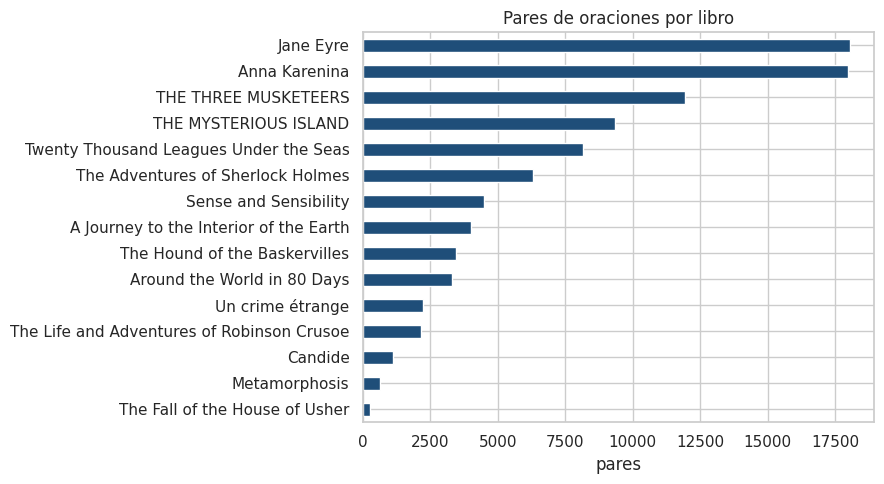

In [11]:
por_libro = df_p3.groupby("libro", sort=False).size().rename("pares").to_frame()
por_libro["%"] = (por_libro["pares"] / por_libro["pares"].sum() * 100).round(1)
display(por_libro)

ax = por_libro["pares"].sort_values().plot(kind="barh", figsize=(9, 5), color="#1f4e79")
ax.set_title("Pares de oraciones por libro"); ax.set_xlabel("pares"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Observaciones**

El dataset está desbalanceado: dos libros concentran casi el 40% de los pares y el más pequeño tiene solo 280. Revisando el contenido aparecen tres problemas que no se ven en la tabla:

- El grupo "Jane Eyre" en realidad contiene tres libros: Jane Eyre, Alicia en el país de las maravillas y Don Quijote. Los dos últimos no tienen fila "Source:", así que quedaron dentro de Jane Eyre.
- En "Un crime étrange" (Estudio en escarlata) el lado en inglés está en francés. Son unos 2.200 pares que no sirven para traducir del inglés.
- Anna Karenina aparece dos veces porque viene en dos partes.

#### Longitud de los textos

Se mide la longitud en palabras de cada lado y la relación entre ambas. En una traducción fiel, el español suele ser un poco más largo que el inglés; una relación muy alejada de 1 puede indicar que el par está mal alineado.

,count,mean,std,min,25%,50%,75%,max
palabras_en,93470.0,22.91,21.97,1.00,9.00,17.0,29.00,648.0
palabras_es,93470.0,21.74,20.23,1.00,8.00,16.0,28.00,662.0
ratio,93470.0,1.05,0.61,0.01,0.87,1.0,1.14,107.0


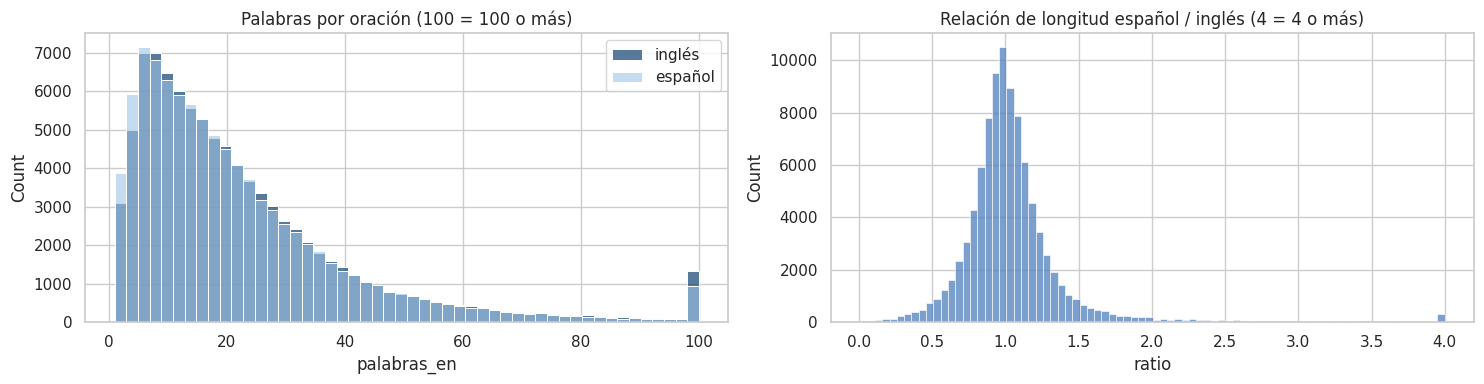

In [12]:
df_p3["palabras_en"] = df_p3["en"].str.split().str.len()
df_p3["palabras_es"] = df_p3["es"].str.split().str.len()
df_p3["ratio"] = df_p3["es"].str.len() / df_p3["en"].str.len()   # relación de longitud en caracteres
display(df_p3[["palabras_en", "palabras_es", "ratio"]].describe().round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(df_p3["palabras_en"].clip(upper=100), bins=50, ax=axes[0], color="#1f4e79", label="inglés")
sns.histplot(df_p3["palabras_es"].clip(upper=100), bins=50, ax=axes[0], color="#9dc3e6", label="español", alpha=0.6)
axes[0].set_title("Palabras por oración (100 = 100 o más)"); axes[0].legend()
sns.histplot(df_p3["ratio"].clip(upper=4), bins=80, ax=axes[1], color="#4f81bd")
axes[1].set_title("Relación de longitud español / inglés (4 = 4 o más)"); axes[1].set_xlabel("ratio")
plt.tight_layout(); plt.show()

**Observaciones**

Las oraciones tienen en promedio 23 palabras en inglés y 22 en español, con una mediana de 17 y 16. La relación de longitud tiene una mediana de 1.0, así que en general los pares tienen un tamaño parecido. Pero hay casos extremos: oraciones de más de 600 palabras, que en realidad son párrafos completos, y relaciones de 0,01 o de 107, que solo pueden ser pares mal alineados.

#### ¿Qué longitud máxima usar?

Igual que en los problemas anteriores se mide la longitud en sub-tokens, pero ahora de los dos lados: la oración en inglés (entrada) y la traducción en español (salida). El tokenizador de Marian usa SentencePiece, que marca el inicio de cada palabra con `▁`.

In [13]:
print("Ejemplo de tokenización:")
print("  EN:", tokenizer_p3.tokenize("Unbelievably, Sherlock Holmes said nothing."))
print("  ES:", tokenizer_p3.tokenize("Increíblemente, Sherlock Holmes no dijo nada.", ))

df_p3["tokens_en"] = [len(ids) for ids in tokenizer_p3(list(df_p3["en"]))["input_ids"]]
df_p3["tokens_es"] = [len(ids) for ids in tokenizer_p3(text_target=list(df_p3["es"]))["input_ids"]]
percentiles_p3 = df_p3[["tokens_en", "tokens_es"]].quantile([0.5, 0.9, 0.95, 0.99, 1.0]).T
percentiles_p3.columns = ["p50", "p90", "p95", "p99", "máximo"]
display(percentiles_p3)

P3_MAX_LEN = 128
largos = (df_p3["tokens_en"] > P3_MAX_LEN) | (df_p3["tokens_es"] > P3_MAX_LEN)
print(f"\nmax_length = {P3_MAX_LEN} sub-tokens | pares que lo superan: {largos.sum()} ({largos.mean():.2%})")

Ejemplo de tokenización:
  EN: ['▁Un', 'be', 'liev', 'ably', ',', '▁She', 'r', 'lock', '▁Holmes', '▁said', '▁nothing', '.']
  ES: ['▁Inc', 're', 'í', 'ble', 'ment', 'e', ',', '▁She', 'r', 'lock', '▁Holmes', '▁no', '▁di', 'jo', '▁n', 'ada', '.']


,p50,p90,p95,p99,máximo
tokens_en,24.0,63.0,83.0,140.0,912.0
tokens_es,24.0,61.0,80.0,134.0,977.0



max_length = 128 sub-tokens | pares que lo superan: 1450 (1.55%)


**Observaciones**

Los dos idiomas tienen longitudes muy parecidas en sub-tokens, con una mediana de 24. El ejemplo muestra que las palabras poco comunes se dividen en varias piezas: "Increíblemente" queda en 6 y "Sherlock" en 3. Con un máximo de 128 sub-tokens se cubre más del 98% de los pares, y solo 1.450 (1,55%) lo superan. Esos pares se eliminan en la limpieza en lugar de truncarlos, porque cortar la oración en inglés y la traducción por separado dejaría pares que ya no dicen lo mismo.

#### Calidad de los datos

En un corpus alineado automáticamente es normal encontrar ruido. Se revisan:

- Filas vacías y filas de metadatos ("Source: ...").
- Pares duplicados, y oraciones en inglés repetidas con traducciones distintas.
- Pares con una relación de longitud extrema, que suelen ser errores de alineación: la oración en inglés quedó emparejada con otra oración en español.

In [14]:
vacias = (df_p3["en"].str.strip() == "") | (df_p3["es"].str.strip() == "")
print(f"Filas vacías:                     {vacias.sum()}")
print(f"Filas de metadatos ('Source:'):   {df_p3['es_metadato'].sum()}")
print(f"Pares duplicados (en y es):       {df_p3.duplicated(['en', 'es']).sum()}")
print(f"Oraciones en inglés repetidas:    {df_p3['en'].duplicated().sum()}")

print("\nOraciones en inglés más repetidas:")
display(df_p3["en"].value_counts().head(6).to_frame("veces"))

P3_RATIO_MIN, P3_RATIO_MAX = 1 / 3, 3
extremos = (df_p3["ratio"] < P3_RATIO_MIN) | (df_p3["ratio"] > P3_RATIO_MAX)
print(f"Pares con relación de longitud fuera de [{P3_RATIO_MIN:.2f}, {P3_RATIO_MAX}]: {extremos.sum()} ({extremos.mean():.2%})\n")
print("Ejemplos:")
for _, fila in df_p3[extremos & ~df_p3["es_metadato"]].sample(5, random_state=SEED).iterrows():
    print(f"  EN: {fila['en'][:200]}")
    print(f"  ES: {fila['es'][:200]}\n")

Filas vacías:                     0
Filas de metadatos ('Source:'):   16
Pares duplicados (en y es):       678
Oraciones en inglés repetidas:    1314

Oraciones en inglés más repetidas:


,veces
en,
"""Yes.""",82
"""No.""",37
"""Yes, sir.""",33
"""Well?""",21
"""Yes.",20
"""What?""",19


Pares con relación de longitud fuera de [0.33, 3]: 1295 (1.39%)

Ejemplos:
  EN: It could only be Top!
  ES: No podía ser más que Top el que ladraba así, pero ¿estaba solo o acompañado?

  EN: "I presume that the reason he gave was that you would receive help from Sir Charles for the legal expenses connected with your divorce?"
  ES: -Él me la dictó.

  EN: Herbert at a word from the reporter ran out to look for water.
  ES: Harbert, a una palabra que le dijo el corresponsal, se lanzó fuera para buscar agua, y encontró, a cien pasos de allí, un riachuelo límpido evidentemente engrosado por las lluvias de la noche pasada y

  EN: It was nine o'clock.
  ES: Eran las nueve de la noche y largos bostezos mal disimulados anunciaban la hora del sueño.

  EN: Chapter 9
  ES: 9. Construyen un ascensor y fabrican el cristal



**Observaciones**

No hay filas vacías, pero sí ruido típico de un alineamiento automático:

- 16 filas de metadatos, una por cada inicio de libro.
- 678 pares duplicados y 1.314 oraciones en inglés repetidas. Casi todas son respuestas cortas de diálogo ("Yes." aparece 82 veces) que el traductor tradujo de distintas formas según el contexto.
- 1.295 pares (1,39%) con una relación de longitud extrema. Los ejemplos muestran que son errores de alineación: una pregunta larga emparejada con "-Él me la dictó.", o "Chapter 9" emparejado con el título del capítulo.

### 4.4 Limpieza y partición

A diferencia de los problemas 1 y 2, aquí sí se limpia el dataset, por dos razones:

- El corpus se alineó de forma automática, así que tiene pares que no son traducciones entre sí. En traducción, un par mal alineado enseña al modelo a inventar o a omitir contenido.
- No trae partición oficial, así que se debe crear una y no hay comparación con otros trabajos que se pierda.

Reglas aplicadas, en este orden:

1. Quitar las filas de metadatos y las vacías.
2. Quitar pares con relación de longitud menor a 1/3 o mayor a 3.
3. Quitar pares de más de 128 sub-tokens en cualquiera de los dos lados. Truncarlos dejaría traducciones incompletas que no corresponden a la entrada.
4. Dejar una sola vez cada oración en inglés. Así una misma oración no puede quedar a la vez en train y en test.

Como no hay partición oficial, se separan 2.000 pares para validación y 2.000 para test, estratificando por libro para que todos los libros estén representados en la misma proporción en los tres conjuntos.

Igual que antes, no se normaliza el texto (minúsculas, puntuación): el tokenizador del modelo espera texto natural, y las mayúsculas y signos son parte de una buena traducción.

In [15]:
n_inicial = len(df_p3)
limpio = df_p3[~df_p3["es_metadato"] & ~vacias]
n1 = len(limpio)
limpio = limpio[(limpio["ratio"] >= P3_RATIO_MIN) & (limpio["ratio"] <= P3_RATIO_MAX)]
n2 = len(limpio)
limpio = limpio[(limpio["tokens_en"] <= P3_MAX_LEN) & (limpio["tokens_es"] <= P3_MAX_LEN)]
n3 = len(limpio)
limpio = limpio.drop_duplicates("en").reset_index(drop=True)
n4 = len(limpio)

display(pd.DataFrame({
    "paso": ["inicial", "sin metadatos ni vacías", "relación de longitud", "máximo 128 sub-tokens", "sin inglés repetido"],
    "pares": [n_inicial, n1, n2, n3, n4],
    "eliminados": [0, n_inicial - n1, n1 - n2, n2 - n3, n3 - n4],
}))
print(f"Se conserva el {n4 / n_inicial:.1%} del dataset")

P3_TAMANO_EVAL = 2000
resto, df_test_p3 = train_test_split(limpio, test_size=P3_TAMANO_EVAL, stratify=limpio["libro"], random_state=SEED)
df_train_p3, df_val_p3 = train_test_split(resto, test_size=P3_TAMANO_EVAL, stratify=resto["libro"], random_state=SEED)
print(f"\nTrain: {len(df_train_p3)} | Validación: {len(df_val_p3)} | Test: {len(df_test_p3)}")

columnas = ["en", "es", "libro"]
opus_split = datasets.DatasetDict({
    "train": datasets.Dataset.from_pandas(df_train_p3[columnas], preserve_index=False),
    "validation": datasets.Dataset.from_pandas(df_val_p3[columnas], preserve_index=False),
    "test": datasets.Dataset.from_pandas(df_test_p3[columnas], preserve_index=False),
})

,paso,pares,eliminados
0,inicial,93470,0
1,sin metadatos ni vacías,93454,16
2,relación de longitud,92159,1295
3,máximo 128 sub-tokens,90734,1425
4,sin inglés repetido,89689,1045


Se conserva el 96.0% del dataset

Train: 85689 | Validación: 2000 | Test: 2000


**Observaciones**

La limpieza elimina 3.781 pares y conserva el 96% del dataset, así que se pierde muy poca información. Los pasos que más pares eliminan son la longitud máxima (1.425) y la relación de longitud (1.295). Quedan 85.689 pares para entrenar y 2.000 para validación y test, repartidos de forma proporcional entre los libros.

Los problemas del grupo "Jane Eyre" y de "Un crime étrange" no se corrigen en la limpieza. Afectan la etiqueta del libro, no la calidad de cada par, y quitar los pares en francés no cambia el objetivo de la comparación. Se tienen en cuenta al interpretar los resultados por libro.

### 4.5 Línea base: el modelo preentrenado sin fine-tuning

En traducción, la comparación natural no es un modelo clásico sino el **mismo modelo antes del fine-tuning**. Así se mide exactamente cuánto aporta adaptar el traductor al dominio literario.

Métricas, calculadas con `sacrebleu` comparando la traducción del modelo con la traducción publicada (la referencia):

- **BLEU (métrica principal)**: mide cuántos fragmentos de 1 a 4 palabras de la traducción aparecen también en la referencia, con una penalización si la traducción es demasiado corta. Va de 0 a 100.
- **chrF**: parecida, pero compara fragmentos de caracteres en lugar de palabras. Es más justa con variaciones de una misma palabra ("dijo" frente a "dije"), algo frecuente en español.

Ninguna de las dos mide el significado directamente: una traducción correcta pero redactada distinto a la referencia obtiene un puntaje bajo. Por eso los valores absolutos son bajos en traducción literaria, donde los traductores toman muchas libertades. Lo importante es la comparación entre modelos sobre las mismas oraciones.

La función `traducir` genera las traducciones por lotes. Ordena las oraciones por longitud para que cada lote tenga oraciones parecidas y se desperdicie menos cómputo en padding.

In [17]:
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"

def traducir(modelo, textos, num_beams=4, batch_size=64):
    """Traduce una lista de textos. Devuelve las traducciones en el mismo orden."""
    modelo.eval()
    orden = np.argsort([-len(t) for t in textos])          # de la más larga a la más corta
    salida = [None] * len(textos)
    for i in range(0, len(textos), batch_size):
        idx = orden[i:i + batch_size]
        enc = tokenizer_p3([textos[j] for j in idx], return_tensors="pt", padding=True,
                           truncation=True, max_length=P3_MAX_LEN).to(modelo.device)
        with torch.no_grad(), torch.autocast(DISPOSITIVO, dtype=torch.float16, enabled=FP16):
            generado = modelo.generate(**enc, num_beams=num_beams, max_new_tokens=P3_MAX_LEN)
        for j, texto in zip(idx, tokenizer_p3.batch_decode(generado, skip_special_tokens=True)):
            salida[j] = texto
    return salida

def bleu_chrf(hipotesis, referencias):
    return (sacrebleu.corpus_bleu(hipotesis, [referencias]).score,
            sacrebleu.corpus_chrf(hipotesis, [referencias]).score)

P3_N_VAL_BASE = 50 if MODO_PRUEBA else 500
val_base = df_val_p3.head(P3_N_VAL_BASE)
modelo_base = AutoModelForSeq2SeqLM.from_pretrained(P3_MODEL).to(DISPOSITIVO)
pred_val_base_p3 = traducir(modelo_base, list(val_base["en"]), num_beams=1)
bleu_val_base, chrf_val_base = bleu_chrf(pred_val_base_p3, list(val_base["es"]))
print(f"Línea base ({P3_N_VAL_BASE} oraciones de validación, búsqueda voraz) | BLEU: {bleu_val_base:.2f} | chrF: {chrf_val_base:.2f}")

print("\nEjemplos:")
for en, es, pred in list(zip(val_base["en"], val_base["es"], pred_val_base_p3))[:4]:
    print(f"  EN:         {en}\n  Referencia: {es}\n  Modelo:     {pred}\n")
del modelo_base; liberar_memoria()

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Línea base (500 oraciones de validación, búsqueda voraz) | BLEU: 18.16 | chrF: 44.92

Ejemplos:
  EN:         Here Cide Hamete leaves him, and returns to Don Quixote, who in high spirits and satisfaction was looking forward to the day fixed for the battle he was to fight with him who had robbed Dona Rodriguez's daughter of her honour, for whom he hoped to obtain satisfaction for the wrong and injury shamefully done to her.
  Referencia: Aquí le deja Cide Hamete Benengeli, y vuelve a tratar de don Quijote, que, alborozado y contento, esperaba el plazo de la batalla que había de hacer con el robador de la honra de la hija de doña Rodríguez, a quien pensaba enderezar el tuerto y desaguisado que malamente le tenían fecho.
  Modelo:     Aquí Cide Hamete lo deja, y vuelve a don Quijote, que con ánimos y satisfacción esperaba el día fijado para la batalla que iba a pelear con el que le había robado a la hija de doña Rodríguez su honor, para el cual esperaba obtener satisfacción por el mal y e

**Observaciones**

El modelo sin fine-tuning obtiene un BLEU de 18,16 y un chrF de 44,92. El número es bajo, pero los ejemplos muestran que el modelo entiende bien el sentido. La diferencia está en el estilo:

- En el primer ejemplo la referencia es el Quijote original de Cervantes, con palabras como "agora" y "fecho". Ningún traductor moderno escribiría así, así que la comparación penaliza al modelo aunque su traducción sea correcta.
- El modelo usa comillas donde la referencia usa la raya o "»".
- Hay errores reales de traducción literal, como "deseosa de determinar si había algún cuarto ciego aún dibujado", que no tiene sentido.

Esto es importante para leer el resto del problema: un BLEU bajo no significa que la traducción sea mala, sino que se parece poco a la traducción publicada.

### 4.6 Tokenización

En seq2seq se tokenizan los dos lados:

- La oración en inglés se convierte en `input_ids`, la entrada del encoder.
- La traducción en español se tokeniza con `text_target` y se convierte en `labels`, lo que el decoder debe aprender a generar.

Durante el entrenamiento se usa **teacher forcing**: en cada paso el decoder recibe la traducción correcta hasta la palabra anterior (no lo que él mismo generó) y debe predecir la siguiente. El `DataCollatorForSeq2Seq` prepara esa entrada desplazando los `labels` una posición, y rellena los `labels` con `-100` para que el padding no cuente en la pérdida.

In [18]:
def tokenizar_p3(batch):
    return tokenizer_p3(batch["en"], text_target=batch["es"], truncation=True, max_length=P3_MAX_LEN)

opus_tok = opus_split.map(tokenizar_p3, batched=True, remove_columns=opus_split["train"].column_names)
print(opus_tok)

ejemplo_p3 = opus_tok["train"][0]
print("\nEntrada (inglés):", tokenizer_p3.convert_ids_to_tokens(ejemplo_p3["input_ids"]))
print("Labels (español): ", tokenizer_p3.convert_ids_to_tokens(ejemplo_p3["labels"]))

Map:   0%|          | 0/85689 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 85689
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 2000
    })
})

Entrada (inglés): ['▁I', '▁trust', ',', '▁Jane', ',', '▁you', '▁are', '▁in', '▁earnest', '▁when', '▁you', '▁say', '▁you', '▁will', '▁serve', '▁your', '▁heart', '▁to', '▁God', ':', '▁it', '▁is', '▁all', '▁I', '▁want', '.', '</s>']
Labels (español):  ['▁Puesto', '▁que', '▁ofrenda', 's', '▁tu', '▁corazón', '▁a', '▁Dios', ',', '▁no', '▁necesito', '▁más', '.', '</s>']


**Observaciones**

Cada par queda con tres campos: `input_ids` y `attention_mask` para la oración en inglés, y `labels` para la traducción. Los dos lados terminan con el token `</s>`, que marca el final de la oración. Así el modelo aprende cuándo dejar de generar.

El ejemplo muestra otra vez que la traducción es libre: 27 sub-tokens en inglés se convierten en 14 en español, y la frase se reformula por completo. El modelo tiene que aprender a producir traducciones como esa, no una versión palabra por palabra.

### 4.7 Modelo y métricas

`AutoModelForSeq2SeqLM` carga el modelo completo, encoder y decoder, con todos sus pesos ya entrenados. A diferencia de los problemas anteriores no se agrega ninguna capa nueva: la salida del decoder ya es una distribución sobre el vocabulario, que se usa para elegir el siguiente token.

Para entrenar se usan `Seq2SeqTrainer` y `Seq2SeqTrainingArguments`, versiones del `Trainer` que pueden **generar** traducciones durante la evaluación (`predict_with_generate=True`) y así calcular BLEU y chrF en cada época.

Para que la evaluación en cada época sea rápida, durante el entrenamiento se genera con **búsqueda voraz** (en cada paso se elige el token más probable). En la evaluación final en test se usa **beam search** con 4 haces, que explora varias traducciones posibles a la vez y suele dar mejores resultados.

In [20]:
def crear_modelo_p3():
    return AutoModelForSeq2SeqLM.from_pretrained(P3_MODEL)

def metricas_p3(eval_pred):
    predicciones, etiquetas = eval_pred
    if isinstance(predicciones, tuple):
        predicciones = predicciones[0]
    pad = tokenizer_p3.pad_token_id
    predicciones = np.where(predicciones != -100, predicciones, pad)
    etiquetas = np.where(etiquetas != -100, etiquetas, pad)
    hipotesis = tokenizer_p3.batch_decode(predicciones, skip_special_tokens=True)
    referencias = tokenizer_p3.batch_decode(etiquetas, skip_special_tokens=True)
    bleu, chrf = bleu_chrf(hipotesis, referencias)
    return {"bleu": bleu, "chrf": chrf}

collator_p3 = DataCollatorForSeq2Seq(tokenizer_p3, model=None)

modelo_tmp = crear_modelo_p3()
n_params = sum(p.numel() for p in modelo_tmp.parameters())
print(f"Parámetros del modelo: {n_params / 1e6:.1f} millones")
print(f"Capas del encoder: {modelo_tmp.config.encoder_layers} | capas del decoder: {modelo_tmp.config.decoder_layers}")
print(f"Tamaño del vocabulario: {modelo_tmp.config.vocab_size}")
del modelo_tmp; liberar_memoria()

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Parámetros del modelo: 77.9 millones
Capas del encoder: 6 | capas del decoder: 6
Tamaño del vocabulario: 65001


La función `entrenar_p3` es equivalente a `entrenar_p1` y `entrenar_p2`. El mejor checkpoint se elige por BLEU.

In [21]:
def entrenar_p3(lr, batch_size, train_ds, eval_ds, epocas, output_dir, guardar=False, paciencia=None):
    """Entrena una configuración. Si guardar=True conserva el mejor checkpoint (según BLEU)."""
    set_seed(SEED)
    args = Seq2SeqTrainingArguments(
        output_dir=output_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        num_train_epochs=epocas,
        weight_decay=0.01,
        warmup_steps=0.1,                  # un valor < 1 se interpreta como fracción de los pasos totales (10 %)
        lr_scheduler_type="linear",
        eval_strategy="epoch",
        save_strategy="epoch" if guardar else "no",
        load_best_model_at_end=guardar,
        metric_for_best_model="bleu",
        greater_is_better=True,
        save_total_limit=1,
        predict_with_generate=True,        # genera traducciones al evaluar para calcular BLEU
        generation_max_length=P3_MAX_LEN,
        generation_num_beams=1,            # búsqueda voraz durante el entrenamiento (más rápida)
        logging_steps=50,
        fp16=FP16,
        report_to="none",
        seed=SEED,
    )
    callbacks = [EarlyStoppingCallback(early_stopping_patience=paciencia)] if paciencia else None
    trainer = Seq2SeqTrainer(
        model=crear_modelo_p3(),
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tokenizer_p3,
        data_collator=collator_p3,
        compute_metrics=metricas_p3,
        callbacks=callbacks,
    )
    inicio = time.time()
    trainer.train()
    return trainer, time.time() - inicio

### 4.8 Búsqueda de hiperparámetros

Se exploran las mismas combinaciones de los problemas anteriores sobre una **muestra aleatoria** de 4.000 pares de entrenamiento. Como generar traducciones es mucho más lento que clasificar, cada configuración se evalúa en una muestra fija de 500 pares de validación (los mismos de la línea base), en lugar de la validación completa.

| Hiperparámetro | Valores probados |
|---|---|
| Learning rate | `1e-5`, `2e-5`, `3e-5`, `5e-5`, `1e-4` |
| Batch size | `16`, `32` |
| Épocas | 3 (fijo) |

> Si la sesión de Colab se corta, al volver a ejecutar esta celda las configuraciones ya probadas se cargan desde Drive y no se repiten.

In [22]:
if MODO_PRUEBA:
    P3_TAMANO_MUESTRA, P3_LRS, P3_BATCH_SIZES, P3_EPOCAS_BUSQUEDA = 200, [2e-5, 5e-5], [16], 1
else:
    P3_TAMANO_MUESTRA, P3_LRS, P3_BATCH_SIZES, P3_EPOCAS_BUSQUEDA = 4000, [1e-5, 2e-5, 3e-5, 5e-5, 1e-4], [16, 32], 3

p3_muestra = opus_tok["train"].shuffle(seed=SEED).select(range(P3_TAMANO_MUESTRA))
p3_eval_busqueda = opus_tok["validation"].select(range(P3_N_VAL_BASE))
print(f"Muestra de entrenamiento: {len(p3_muestra)} pares | Validación: {len(p3_eval_busqueda)} pares")

Muestra de entrenamiento: 4000 pares | Validación: 500 pares


In [23]:
ruta_csv_p3 = os.path.join(P3_DIR, "busqueda_hiperparametros.csv")
ruta_hist_p3 = os.path.join(P3_DIR, "historiales_busqueda.json")
filas_p3, historiales_p3 = cargar_busqueda(ruta_csv_p3, ruta_hist_p3)
ya_probadas_p3 = {(float(f["learning_rate"]), int(f["batch_size"])) for f in filas_p3}

for bs in P3_BATCH_SIZES:
    for lr in P3_LRS:
        if (lr, bs) in ya_probadas_p3:
            print(f"Evaluación: learning_rate={lr:.0e}, batch_size={bs} (ya probado, se omite)")
            continue

        print(f"\n Evaluando: learning_rate={lr:.0e}, batch_size={bs}")
        trainer, segundos = entrenar_p3(lr, bs, p3_muestra, p3_eval_busqueda, P3_EPOCAS_BUSQUEDA,
                                        output_dir=os.path.join("/tmp", "p3_busqueda"))
        _, evals = curvas_desde_historial(trainer.state.log_history)
        mejor = evals.loc[evals["eval_bleu"].idxmax()]
        filas_p3.append({
            "learning_rate": lr, "batch_size": bs,
            "bleu": mejor["eval_bleu"], "chrf": mejor["eval_chrf"], "eval_loss": mejor["eval_loss"],
            "mejor_epoca": int(round(mejor["epoch"])), "minutos": segundos / 60,
        })
        historiales_p3[f"{lr}_{bs}"] = trainer.state.log_history
        guardar_busqueda(filas_p3, historiales_p3, ruta_csv_p3, ruta_hist_p3)
        del trainer; liberar_memoria()


 Evaluando: learning_rate=1e-05, batch_size=16


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.381', 'grad_norm': '5.727', 'learning_rate': '6.533e-06', 'epoch': '0.2'}
{'loss': '2.27', 'grad_norm': '5.091', 'learning_rate': '9.644e-06', 'epoch': '0.4'}
{'loss': '2.345', 'grad_norm': '5.966', 'learning_rate': '8.904e-06', 'epoch': '0.6'}
{'loss': '2.256', 'grad_norm': '5.531', 'learning_rate': '8.163e-06', 'epoch': '0.8'}
{'loss': '2.284', 'grad_norm': '5.462', 'learning_rate': '7.422e-06', 'epoch': '1'}
{'eval_loss': '2.117', 'eval_bleu': '19.74', 'eval_chrf': '45.17', 'eval_runtime': '21.28', 'eval_samples_per_second': '23.5', 'eval_steps_per_second': '0.376', 'epoch': '1'}
{'loss': '2.226', 'grad_norm': '4.331', 'learning_rate': '6.681e-06', 'epoch': '1.2'}
{'loss': '2.225', 'grad_norm': '4.785', 'learning_rate': '5.941e-06', 'epoch': '1.4'}
{'loss': '2.065', 'grad_norm': '4.528', 'learning_rate': '5.2e-06', 'epoch': '1.6'}
{'loss': '2.082', 'grad_norm': '4.696', 'learning_rate': '4.459e-06', 'epoch': '1.8'}
{'loss': '2.143', 'grad_norm': '4.293', 'learning_rate':

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.365', 'grad_norm': '5.679', 'learning_rate': '1.307e-05', 'epoch': '0.2'}
{'loss': '2.25', 'grad_norm': '5.64', 'learning_rate': '1.929e-05', 'epoch': '0.4'}
{'loss': '2.33', 'grad_norm': '5.966', 'learning_rate': '1.781e-05', 'epoch': '0.6'}
{'loss': '2.241', 'grad_norm': '5.538', 'learning_rate': '1.633e-05', 'epoch': '0.8'}
{'loss': '2.266', 'grad_norm': '5.45', 'learning_rate': '1.484e-05', 'epoch': '1'}
{'eval_loss': '2.101', 'eval_bleu': '19.84', 'eval_chrf': '45.43', 'eval_runtime': '12.44', 'eval_samples_per_second': '40.19', 'eval_steps_per_second': '0.643', 'epoch': '1'}
{'loss': '2.131', 'grad_norm': '4.327', 'learning_rate': '1.336e-05', 'epoch': '1.2'}
{'loss': '2.132', 'grad_norm': '4.785', 'learning_rate': '1.188e-05', 'epoch': '1.4'}
{'loss': '1.972', 'grad_norm': '4.409', 'learning_rate': '1.04e-05', 'epoch': '1.6'}
{'loss': '1.993', 'grad_norm': '4.674', 'learning_rate': '8.919e-06', 'epoch': '1.8'}
{'loss': '2.05', 'grad_norm': '4.263', 'learning_rate': '

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

... (11 outputs left out)

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.295', 'grad_norm': '3.435', 'learning_rate': '4.837e-05', 'epoch': '0.4'}
{'loss': '2.286', 'grad_norm': '3.819', 'learning_rate': '4.095e-05', 'epoch': '0.8'}
{'eval_loss': '2.096', 'eval_bleu': '20.25', 'eval_chrf': '45.38', 'eval_runtime': '13.06', 'eval_samples_per_second': '38.27', 'eval_steps_per_second': '0.612', 'epoch': '1'}
{'loss': '2.14', 'grad_norm': '3.119', 'learning_rate': '3.353e-05', 'epoch': '1.2'}
{'loss': '1.944', 'grad_norm': '3.394', 'learning_rate': '2.611e-05', 'epoch': '1.6'}
{'loss': '1.926', 'grad_norm': '3.391', 'learning_rate': '1.869e-05', 'epoch': '2'}
{'eval_loss': '2.084', 'eval_bleu': '20.48', 'eval_chrf': '45.52', 'eval_runtime': '13.08', 'eval_samples_per_second': '38.23', 'eval_steps_per_second': '0.612', 'epoch': '2'}
{'loss': '1.775', 'grad_norm': '3.714', 'learning_rate': '1.128e-05', 'epoch': '2.4'}
{'loss': '1.785', 'grad_norm': '3.404', 'learning_rate': '3.858e-06', 'epoch': '2.8'}
{'eval_loss': '2.085', 'eval_bleu': '20.47', 'eva

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.291', 'grad_norm': '3.543', 'learning_rate': '9.674e-05', 'epoch': '0.4'}
{'loss': '2.315', 'grad_norm': '3.809', 'learning_rate': '8.19e-05', 'epoch': '0.8'}
{'eval_loss': '2.121', 'eval_bleu': '19.79', 'eval_chrf': '45.16', 'eval_runtime': '12.74', 'eval_samples_per_second': '39.25', 'eval_steps_per_second': '0.628', 'epoch': '1'}
{'loss': '2.076', 'grad_norm': '3.109', 'learning_rate': '6.706e-05', 'epoch': '1.2'}
{'loss': '1.792', 'grad_norm': '3.246', 'learning_rate': '5.223e-05', 'epoch': '1.6'}
{'loss': '1.782', 'grad_norm': '3.407', 'learning_rate': '3.739e-05', 'epoch': '2'}
{'eval_loss': '2.116', 'eval_bleu': '19.98', 'eval_chrf': '45.1', 'eval_runtime': '12.29', 'eval_samples_per_second': '40.67', 'eval_steps_per_second': '0.651', 'epoch': '2'}
{'loss': '1.518', 'grad_norm': '3.643', 'learning_rate': '2.255e-05', 'epoch': '2.4'}
{'loss': '1.521', 'grad_norm': '3.32', 'learning_rate': '7.715e-06', 'epoch': '2.8'}
{'eval_loss': '2.125', 'eval_bleu': '20.19', 'eval_

Evaluando mediante gráficas cuál es el mejor conjunto de hiperparámetros. La línea punteada marca el BLEU del modelo sin fine-tuning en las mismas oraciones.

,learning_rate,batch_size,bleu,chrf,eval_loss,mejor_epoca,minutos
0,5e-05,16,20.73,45.63,2.0919,2,2.0
1,3e-05,16,20.68,45.46,2.0815,2,2.0
2,5e-05,32,20.48,45.52,2.0840,2,1.8
3,2e-05,16,20.31,45.45,2.0827,2,2.0
4,3e-05,32,20.29,45.46,2.0805,3,1.8
5,2e-05,32,20.26,45.47,2.0859,3,1.8
6,1e-04,32,20.19,45.17,2.1249,3,1.8
7,1e-05,32,20.12,45.39,2.1093,2,1.8
8,1e-05,16,20.05,45.45,2.0938,3,2.4
9,1e-04,16,19.94,44.84,2.1717,3,2.0


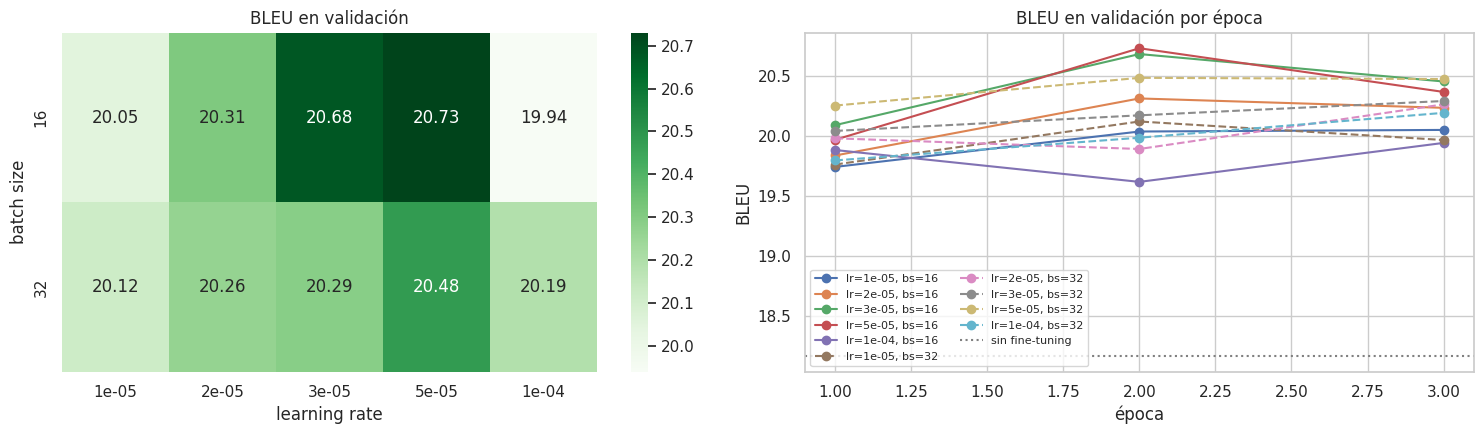


 Mejor configuración: learning rate = 5e-05, batch size = 16, BLEU = 20.73 (sin fine-tuning: 18.16)


In [24]:
busqueda_p3 = pd.DataFrame(filas_p3).sort_values("bleu", ascending=False).reset_index(drop=True)
display(busqueda_p3.style.format({"learning_rate": "{:.0e}", "bleu": "{:.2f}", "chrf": "{:.2f}",
                                  "eval_loss": "{:.4f}", "minutos": "{:.1f}"})
        .background_gradient(subset=["bleu"], cmap="Greens"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
tabla = busqueda_p3.pivot(index="batch_size", columns="learning_rate", values="bleu")
sns.heatmap(tabla, annot=True, fmt=".2f", cmap="Greens", ax=axes[0],
            xticklabels=[f"{c:.0e}" for c in tabla.columns])
axes[0].set_title("BLEU en validación"); axes[0].set_xlabel("learning rate"); axes[0].set_ylabel("batch size")

for clave, log in historiales_p3.items():
    lr, bs = clave.split("_")
    _, ev = curvas_desde_historial(log)
    axes[1].plot(ev["epoch"], ev["eval_bleu"], marker="o",
                 ls="-" if bs == str(P3_BATCH_SIZES[0]) else "--", label=f"lr={float(lr):.0e}, bs={bs}")
axes[1].axhline(bleu_val_base, color="gray", ls=":", label="sin fine-tuning")
axes[1].set_title("BLEU en validación por época"); axes[1].set_xlabel("época"); axes[1].set_ylabel("BLEU")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

mejor_p3 = busqueda_p3.iloc[0]
P3_MEJOR_LR, P3_MEJOR_BS = float(mejor_p3["learning_rate"]), int(mejor_p3["batch_size"])
print(f"\n Mejor configuración: learning rate = {P3_MEJOR_LR:.0e}, batch size = {P3_MEJOR_BS}, "
      f"BLEU = {mejor_p3['bleu']:.2f} (sin fine-tuning: {bleu_val_base:.2f})")

#### ¿Cómo se interpretan estos resultados?

Las 10 configuraciones mejoran al modelo original: todas quedan entre 19,94 y 20,73 de BLEU, frente a 18,16 sin fine-tuning. Con solo 4.000 pares y una época ya se gana más de un punto, lo que indica que gran parte de la mejora viene de adaptarse rápido al estilo del corpus.

Las diferencias entre configuraciones son pequeñas, menos de un punto de BLEU sobre 500 oraciones. Por eso el orden exacto de la tabla no es muy confiable. Aun así se ven dos patrones:

- Con el mismo learning rate, batch size 16 suele ser un poco mejor que 32, porque con la muestra pequeña hace el doble de actualizaciones.
- Con learning rate 1e-4 y batch size 16 el modelo se sobreajusta: la pérdida de entrenamiento baja a 1,36 mientras la de validación sube. Es la peor configuración.

La mejor es learning rate 5e-5 con batch size 16 (BLEU 20,73), que alcanza su mejor resultado en la segunda época.

### 4.9 Entrenamiento final con todos los datos

Con la mejor configuración se entrena sobre todos los pares de entrenamiento:

- Hasta **3 épocas**, evaluando en la validación completa (2.000 pares) al final de cada una. Son menos épocas que en los problemas anteriores porque el dataset es mucho más grande y el modelo ya sabe traducir.
- **Early stopping** con paciencia 1: si el BLEU en validación no mejora en una época, el entrenamiento se detiene.
- Al terminar se **restaura el checkpoint de la mejor época** (`load_best_model_at_end`).

In [25]:
if MODO_PRUEBA:
    p3_train, p3_val = opus_tok["train"].select(range(300)), opus_tok["validation"].select(range(50))
    P3_EPOCAS_FINAL = 1
else:
    p3_train, p3_val = opus_tok["train"], opus_tok["validation"]
    P3_EPOCAS_FINAL = 3

dir_checkpoints_p3 = os.path.join(P3_DIR, "checkpoints")
trainer_p3, segundos_p3 = entrenar_p3(P3_MEJOR_LR, P3_MEJOR_BS, p3_train, p3_val, P3_EPOCAS_FINAL,
                                      output_dir=dir_checkpoints_p3, guardar=True, paciencia=1)
print(f"Entrenamiento final completado en {segundos_p3 / 60:.1f} minutos")

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.416', 'grad_norm': '4.43', 'learning_rate': '1.525e-06', 'epoch': '0.009335'}
{'loss': '2.364', 'grad_norm': '5.185', 'learning_rate': '3.08e-06', 'epoch': '0.01867'}
{'loss': '2.342', 'grad_norm': '5.787', 'learning_rate': '4.636e-06', 'epoch': '0.02801'}
{'loss': '2.268', 'grad_norm': '5.593', 'learning_rate': '6.192e-06', 'epoch': '0.03734'}
{'loss': '2.321', 'grad_norm': '5.491', 'learning_rate': '7.747e-06', 'epoch': '0.04668'}
{'loss': '2.261', 'grad_norm': '5.031', 'learning_rate': '9.303e-06', 'epoch': '0.05601'}
{'loss': '2.292', 'grad_norm': '5.178', 'learning_rate': '1.086e-05', 'epoch': '0.06535'}
{'loss': '2.158', 'grad_norm': '4.82', 'learning_rate': '1.241e-05', 'epoch': '0.07468'}
{'loss': '2.232', 'grad_norm': '5.254', 'learning_rate': '1.397e-05', 'epoch': '0.08402'}
{'loss': '2.222', 'grad_norm': '5.042', 'learning_rate': '1.553e-05', 'epoch': '0.09335'}
{'loss': '2.21', 'grad_norm': '4.926', 'learning_rate': '1.708e-05', 'epoch': '0.1027'}
{'loss': '2.17

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '1.838', 'grad_norm': '4.023', 'learning_rate': '3.689e-05', 'epoch': '1.008'}
{'loss': '1.832', 'grad_norm': '4.557', 'learning_rate': '3.672e-05', 'epoch': '1.018'}
{'loss': '1.783', 'grad_norm': '4.048', 'learning_rate': '3.654e-05', 'epoch': '1.027'}
{'loss': '1.772', 'grad_norm': '4.545', 'learning_rate': '3.637e-05', 'epoch': '1.036'}
{'loss': '1.773', 'grad_norm': '4.64', 'learning_rate': '3.62e-05', 'epoch': '1.046'}
{'loss': '1.845', 'grad_norm': '4.171', 'learning_rate': '3.602e-05', 'epoch': '1.055'}
{'loss': '1.812', 'grad_norm': '4.233', 'learning_rate': '3.585e-05', 'epoch': '1.064'}
{'loss': '1.77', 'grad_norm': '4.285', 'learning_rate': '3.568e-05', 'epoch': '1.074'}
{'loss': '1.816', 'grad_norm': '4.786', 'learning_rate': '3.551e-05', 'epoch': '1.083'}
{'loss': '1.779', 'grad_norm': '4.564', 'learning_rate': '3.533e-05', 'epoch': '1.092'}
{'loss': '1.802', 'grad_norm': '4.705', 'learning_rate': '3.516e-05', 'epoch': '1.102'}
{'loss': '1.748', 'grad_norm': '4.8

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '1.647', 'grad_norm': '4.232', 'learning_rate': '1.839e-05', 'epoch': '2.007'}
{'loss': '1.663', 'grad_norm': '5.257', 'learning_rate': '1.822e-05', 'epoch': '2.016'}
{'loss': '1.579', 'grad_norm': '4.544', 'learning_rate': '1.805e-05', 'epoch': '2.026'}
{'loss': '1.605', 'grad_norm': '4.172', 'learning_rate': '1.787e-05', 'epoch': '2.035'}
{'loss': '1.64', 'grad_norm': '4.588', 'learning_rate': '1.77e-05', 'epoch': '2.044'}
{'loss': '1.612', 'grad_norm': '4.253', 'learning_rate': '1.753e-05', 'epoch': '2.054'}
{'loss': '1.623', 'grad_norm': '4.344', 'learning_rate': '1.735e-05', 'epoch': '2.063'}
{'loss': '1.684', 'grad_norm': '4.565', 'learning_rate': '1.718e-05', 'epoch': '2.072'}
{'loss': '1.597', 'grad_norm': '4.503', 'learning_rate': '1.701e-05', 'epoch': '2.082'}
{'loss': '1.608', 'grad_norm': '4.052', 'learning_rate': '1.683e-05', 'epoch': '2.091'}
{'loss': '1.627', 'grad_norm': '4.671', 'learning_rate': '1.666e-05', 'epoch': '2.1'}
{'loss': '1.649', 'grad_norm': '4.58

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '1949', 'train_samples_per_second': '131.9', 'train_steps_per_second': '8.246', 'train_loss': '1.847', 'epoch': '3'}
Entrenamiento final completado en 32.5 minutos


#### Curvas de aprendizaje

El entrenamiento final tomó 32,5 minutos y usó las 3 épocas, porque el modelo mejoró en todas. En validación el BLEU pasa de 21,43 a 22,04 y a 22,44, y la pérdida baja de 1,91 a 1,84. Las mejoras se hacen más pequeñas en cada época (+0,61 y luego +0,40), así que el modelo se acerca a su límite, aunque todavía podría ganar algo con más épocas.

Con todos los datos el BLEU de validación supera por casi 2 puntos al mejor de la búsqueda, lo que confirma que el tamaño del dataset importa. La pérdida de validación sigue bajando y está cerca de la de entrenamiento, así que no hay señales de sobreajuste.

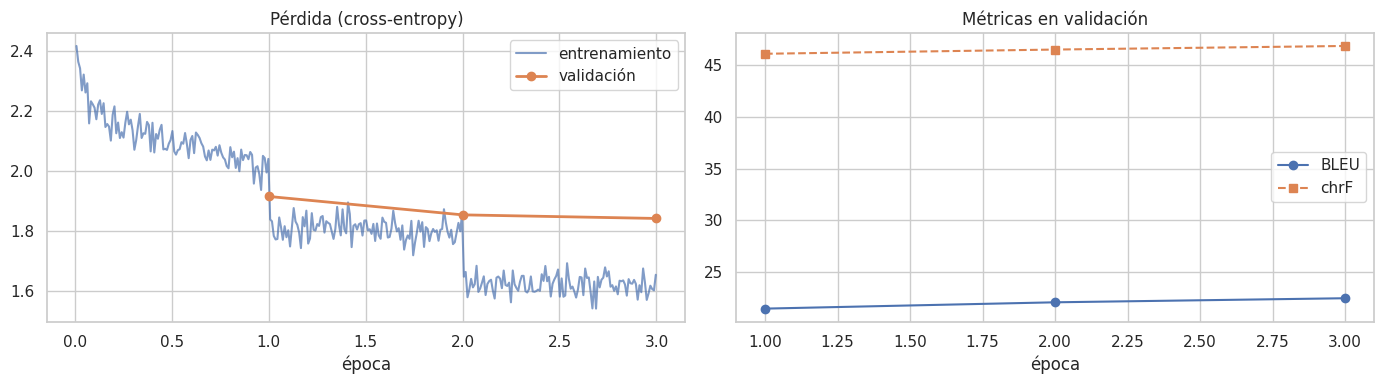

,epoch,eval_loss,eval_bleu,eval_chrf
107,1.0,1.9149,21.4330,46.1118
215,2.0,1.8536,22.0442,46.5192
323,3.0,1.8416,22.4383,46.8669


In [26]:
curva_train_p3, curva_val_p3 = curvas_desde_historial(trainer_p3.state.log_history)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(curva_train_p3["epoch"], curva_train_p3["loss"], label="entrenamiento", alpha=0.7)
axes[0].plot(curva_val_p3["epoch"], curva_val_p3["eval_loss"], "o-", label="validación", lw=2)
axes[0].set_title("Pérdida (cross-entropy)"); axes[0].set_xlabel("época"); axes[0].legend()
axes[1].plot(curva_val_p3["epoch"], curva_val_p3["eval_bleu"], "o-", label="BLEU")
axes[1].plot(curva_val_p3["epoch"], curva_val_p3["eval_chrf"], "s--", label="chrF")
axes[1].set_title("Métricas en validación"); axes[1].set_xlabel("época"); axes[1].legend()
plt.tight_layout(); plt.show()

display(curva_val_p3[["epoch", "eval_loss", "eval_bleu", "eval_chrf"]].round(4))

### 4.10 Evaluación en el conjunto de prueba (test)

Ahora se evalúa en los 2.000 pares de test, que no se usaron para tomar ninguna decisión. Se traducen con el modelo original y con el modelo ajustado, los dos con beam search de 4 haces, y se comparan con las traducciones publicadas.

In [27]:
df_eval_p3 = df_test_p3.head(50).copy() if MODO_PRUEBA else df_test_p3.copy()
fuentes, referencias = list(df_eval_p3["en"]), list(df_eval_p3["es"])

inicio = time.time()
modelo_base = AutoModelForSeq2SeqLM.from_pretrained(P3_MODEL).to(DISPOSITIVO)
df_eval_p3["base"] = traducir(modelo_base, fuentes)
del modelo_base; liberar_memoria()
df_eval_p3["ajustado"] = traducir(trainer_p3.model, fuentes)
print(f"Traducción del test con los dos modelos: {(time.time() - inicio) / 60:.1f} minutos")

def longitud_relativa(hipotesis, referencias):
    return sum(len(h.split()) for h in hipotesis) / sum(len(r.split()) for r in referencias)

comparacion_p3 = pd.DataFrame({
    nombre: {"BLEU": bleu_chrf(list(df_eval_p3[col]), referencias)[0],
             "chrF": bleu_chrf(list(df_eval_p3[col]), referencias)[1],
             "longitud relativa": longitud_relativa(df_eval_p3[col], referencias)}
    for nombre, col in [(f"{P3_MODEL} (sin fine-tuning)", "base"), (f"{P3_MODEL} (fine-tuned)", "ajustado")]
}).T
display(comparacion_p3.style.format("{:.2f}"))

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Traducción del test con los dos modelos: 1.2 minutos


,BLEU,chrF,longitud relativa
Helsinki-NLP/opus-mt-en-es (sin fine-tuning),16.93,44.56,1.02
Helsinki-NLP/opus-mt-en-es (fine-tuned),23.40,48.46,0.98


#### Comparación con la línea base

En test, el modelo ajustado sube el BLEU de 16,93 a 23,40 (+6,5 puntos, una mejora relativa del 38%) y el chrF de 44,56 a 48,46 (+3,9). La longitud de las traducciones casi no cambia: el modelo original produce textos un 2% más largos que la referencia y el ajustado un 2% más cortos.

BLEU mejora más que chrF porque BLEU premia coincidencias exactas de palabras completas y de signos de puntuación. Gran parte de lo que aprende el modelo es justamente eso: la raya de diálogo, las mayúsculas de los títulos y las palabras que prefieren los traductores de estos libros.

#### Resultados por libro y por longitud

Se calcula BLEU por separado para cada libro y para grupos de oraciones según su longitud en inglés, para ver dónde ayuda más el fine-tuning.

,pares,sin fine-tuning,fine-tuned,mejora
Around the World in 80 Days,71,12.89,15.97,+3.09
The Hound of the Baskervilles,75,19.90,23.29,+3.39
A Journey to the Interior of the Earth,87,13.96,18.17,+4.22
Anna Karenina,389,12.27,16.49,+4.22
Metamorphosis,14,11.81,16.13,+4.31
The Fall of the House of Usher,6,22.66,27.16,+4.50
Un crime étrange,48,1.10,5.80,+4.70
The Adventures of Sherlock Holmes,138,24.06,28.91,+4.85
The Life and Adventures of Robinson Crusoe,43,12.28,17.72,+5.44
Jane Eyre,372,15.06,21.62,+6.56


,pares,sin fine-tuning,fine-tuned,mejora
1-10,574,18.37,25.39,+7.02
11-20,625,17.92,23.64,+5.72
21-40,554,16.38,23.03,+6.65
más de 40,247,16.56,22.65,+6.09


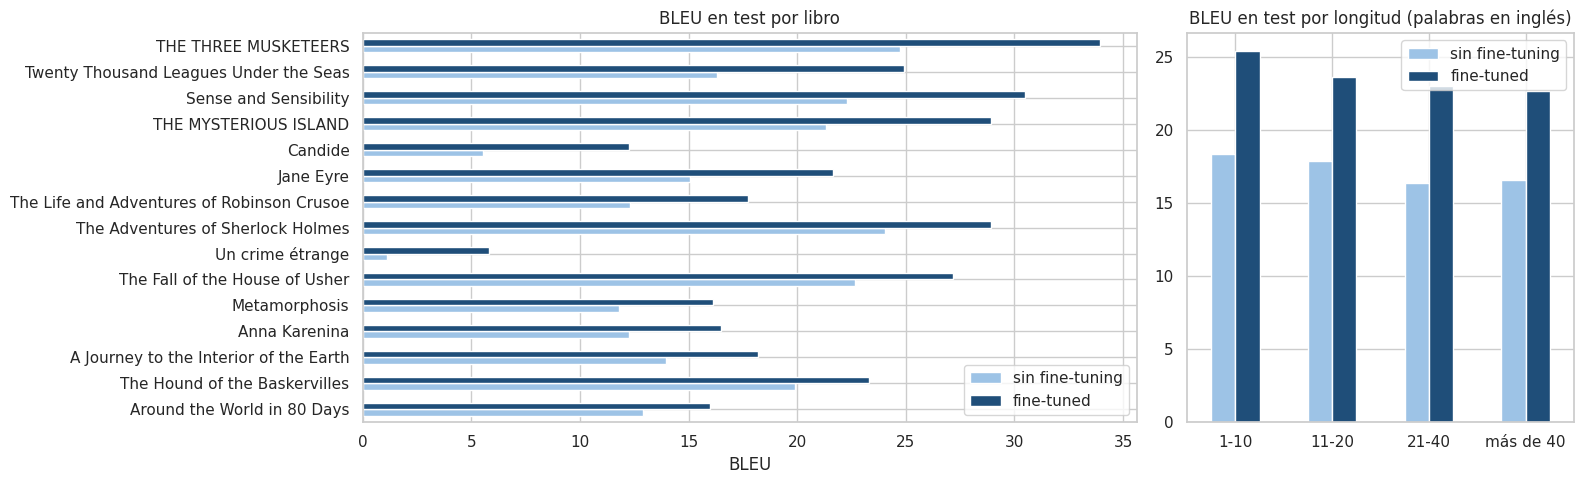

In [28]:
def bleu_por_grupo(df, columna_grupo):
    filas = {}
    for grupo, sub in df.groupby(columna_grupo, observed=True):
        filas[grupo] = {"pares": len(sub),
                        "sin fine-tuning": bleu_chrf(list(sub["base"]), list(sub["es"]))[0],
                        "fine-tuned": bleu_chrf(list(sub["ajustado"]), list(sub["es"]))[0]}
    tabla = pd.DataFrame(filas).T
    tabla["mejora"] = tabla["fine-tuned"] - tabla["sin fine-tuning"]
    return tabla

por_libro_p3 = bleu_por_grupo(df_eval_p3, "libro").sort_values("mejora")
df_eval_p3["longitud"] = pd.cut(df_eval_p3["palabras_en"], bins=[0, 10, 20, 40, 1000],
                                labels=["1-10", "11-20", "21-40", "más de 40"])
por_longitud_p3 = bleu_por_grupo(df_eval_p3, "longitud")
display(por_libro_p3.style.format({"pares": "{:.0f}", "sin fine-tuning": "{:.2f}", "fine-tuned": "{:.2f}", "mejora": "{:+.2f}"}))
display(por_longitud_p3.style.format({"pares": "{:.0f}", "sin fine-tuning": "{:.2f}", "fine-tuned": "{:.2f}", "mejora": "{:+.2f}"}))

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 1]})
por_libro_p3[["sin fine-tuning", "fine-tuned"]].plot(kind="barh", ax=axes[0], color=["#9dc3e6", "#1f4e79"])
axes[0].set_title("BLEU en test por libro"); axes[0].set_xlabel("BLEU"); axes[0].set_ylabel("")
por_longitud_p3[["sin fine-tuning", "fine-tuned"]].plot(kind="bar", ax=axes[1], rot=0, color=["#9dc3e6", "#1f4e79"])
axes[1].set_title("BLEU en test por longitud (palabras en inglés)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Observaciones**

El fine-tuning mejora en todos los libros, entre +3,1 y +9,2 puntos de BLEU. Las mayores mejoras aparecen en libros con muchos pares de entrenamiento, como Los tres mosqueteros (+9,2), Veinte mil leguas de viaje submarino (+8,6) y Sentido y sensibilidad (+8,2).

Los resultados más bajos coinciden con los problemas del análisis exploratorio:

- "Un crime étrange" casi no se puede traducir (BLEU de 1,1 a 5,8) porque su entrada está en francés.
- Anna Karenina queda baja (de 12,3 a 16,5) a pesar de tener muchos pares, porque el inglés y el español son dos traducciones independientes del ruso.
- Los libros con muy pocos pares de test, como La caída de la casa Usher (6) o La metamorfosis (14), no permiten sacar conclusiones.

Por longitud, la mejora es parecida en todos los grupos, entre +5,7 y +7,0. Las oraciones cortas son las que más ganan, y las largas siguen siendo las más difíciles para los dos modelos.

#### Análisis de errores

Se calcula el chrF de cada oración con los dos modelos para ver en cuántas mejora o empeora el fine-tuning, y se revisan ejemplos concretos: los que más mejoraron, los que más empeoraron y los de peor puntaje.

Oraciones que mejoran con el fine-tuning: 66.6%
Oraciones que empeoran:                   29.3%
Oraciones sin cambio:                     4.0%


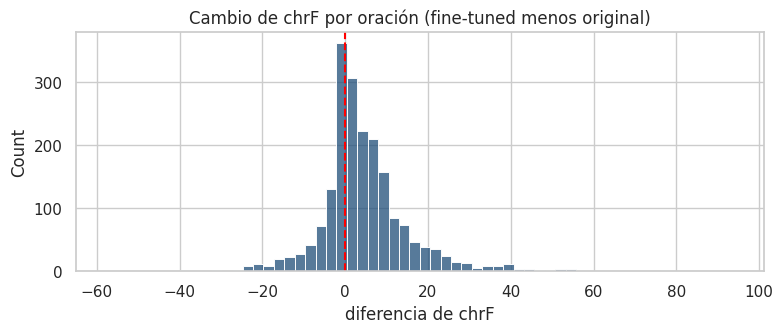


Las que más mejoraron:

  EN:          "Not him."
  Referencia:  ––No a él.
  Original:    "Él no".  (chrF 6)
  Fine-tuned:  ––No a él.  (chrF 100)

  EN:          CHAPTER LIII
  Referencia:  Capítulo LIII
  Original:    CAPÍTULO LIII  (chrF 17)
  Fine-tuned:  Capítulo LIII  (chrF 100)

  EN:          It may very well be.
  Referencia:  Bien puede ser.
  Original:    Puede que sí.  (chrF 20)
  Fine-tuned:  Bien puede ser.  (chrF 100)

Las que más empeoraron:

  EN:          "Not in the least."
  Referencia:  ––Ni lo más mínimo.
  Original:    "No en lo más mínimo."  (chrF 69)
  Fine-tuned:  ––Nada de eso.  (chrF 11)

  EN:          "'Not at all.
  Referencia:  »––En absoluto.
  Original:    "No, en absoluto.  (chrF 63)
  Fine-tuned:  »––Nada de eso.  (chrF 15)

  EN:          "I hope so!" was Cyrus Harding's only reply.
  Referencia:  –¡Así lo espero! –fue la única respuesta de Ciro Smith.
  Original:    "¡Eso espero!" fue la única respuesta de Ciro Smith.  (chrF 79)
  Fine-tuned:  –¡

In [29]:
df_eval_p3["chrf_base"] = [sacrebleu.sentence_chrf(h, [r]).score for h, r in zip(df_eval_p3["base"], df_eval_p3["es"])]
df_eval_p3["chrf_ajustado"] = [sacrebleu.sentence_chrf(h, [r]).score for h, r in zip(df_eval_p3["ajustado"], df_eval_p3["es"])]
df_eval_p3["diferencia"] = df_eval_p3["chrf_ajustado"] - df_eval_p3["chrf_base"]

print(f"Oraciones que mejoran con el fine-tuning: {(df_eval_p3['diferencia'] > 0).mean():.1%}")
print(f"Oraciones que empeoran:                   {(df_eval_p3['diferencia'] < 0).mean():.1%}")
print(f"Oraciones sin cambio:                     {(df_eval_p3['diferencia'] == 0).mean():.1%}")

plt.figure(figsize=(8, 3.5))
sns.histplot(df_eval_p3["diferencia"], bins=60, color="#1f4e79")
plt.axvline(0, color="red", ls="--")
plt.title("Cambio de chrF por oración (fine-tuned menos original)"); plt.xlabel("diferencia de chrF")
plt.tight_layout(); plt.show()


def mostrar(df, titulo, n=3):
    print(f"\n{titulo}")
    for _, fila in df.head(n).iterrows():
        print(f"\n  EN:          {fila['en']}")
        print(f"  Referencia:  {fila['es']}")
        print(f"  Original:    {fila['base']}  (chrF {fila['chrf_base']:.0f})")
        print(f"  Fine-tuned:  {fila['ajustado']}  (chrF {fila['chrf_ajustado']:.0f})")

cortas = df_eval_p3[df_eval_p3["palabras_en"] <= 30]   # oraciones cortas para que los ejemplos se lean fácil
mostrar(cortas.sort_values("diferencia", ascending=False), "Las que más mejoraron:")
mostrar(cortas.sort_values("diferencia"), "Las que más empeoraron:")
mostrar(cortas.sort_values("chrf_ajustado"), "Las de peor puntaje con el modelo ajustado:")

**Observaciones**

El fine-tuning mejora el 66,6% de las oraciones y empeora el 29,3%. La mejora es clara pero no uniforme.

- Las que más mejoraron muestran que el modelo aprendió el estilo de los traductores: usa la raya de diálogo en lugar de comillas, escribe "Capítulo" con mayúscula inicial y elige frases como "Bien puede ser".
- Las que más empeoraron muestran el costo de ese aprendizaje. El modelo ahora traduce "Not in the least" y "Not at all" con la misma fórmula, "Nada de eso", y reformula diálogos que antes traducía de forma más fiel.
- Las de peor puntaje no son errores del modelo sino del dataset. "It was time." aparece emparejado con "Capítulo XXXVIII", y "He shuddered." con "Anda, bebe algo.". Los dos modelos traducen bien, pero la referencia está mal alineada. Estos pares superan el filtro porque tienen una longitud parecida.

Este ruido en el test pone un techo al BLEU que se puede alcanzar, por bueno que sea el modelo.

### 4.11 Guardar y demostrar el mejor modelo

Se guarda el modelo final, se vuelve a cargar desde la carpeta guardada y se compara con el original sobre frases nuevas, usando la misma función `traducir` (las versiones recientes de `transformers` ya no incluyen un `pipeline` de traducción). Las frases incluyen texto de estilo literario (similar al entrenamiento) y texto moderno o técnico (muy distinto), para ver si la adaptación al dominio literario afecta la traducción de otros tipos de texto.

In [30]:
P3_MEJOR_DIR = os.path.join(P3_DIR, "mejor_modelo")
trainer_p3.save_model(P3_MEJOR_DIR)          # guarda pesos, configuración y tokenizador
shutil.rmtree(dir_checkpoints_p3, ignore_errors=True)

modelo_ajustado = AutoModelForSeq2SeqLM.from_pretrained(P3_MEJOR_DIR).to(DISPOSITIVO)   # se carga lo que se guardó
modelo_base = AutoModelForSeq2SeqLM.from_pretrained(P3_MODEL).to(DISPOSITIVO)

frases_nuevas_p3 = [
    "'I have no idea what you mean,' said Holmes, lighting his pipe.",
    "The old captain looked at the sea for a long time without saying a word.",
    "She felt that her whole life had changed in a single moment.",
    "Please restart your computer to install the latest security updates.",
    "The University of Antioquia offers a course on natural language processing.",
    "I'm gonna grab some coffee, text me when you're done.",
]
display(pd.DataFrame({
    "frase": frases_nuevas_p3,
    "sin fine-tuning": traducir(modelo_base, frases_nuevas_p3),
    "fine-tuned": traducir(modelo_ajustado, frases_nuevas_p3),
}))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

,frase,sin fine-tuning,fine-tuned
0,"'I have no idea what you mean,' said Holmes, lighting his pipe.","–No tengo ni idea de lo que quiere decir –dijo Holmes, encendiendo su pipa–.","–No tengo ni idea de lo que quiere usted decir –dijo Holmes, encendiendo la pipa–."
1,The old captain looked at the sea for a long time without saying a word.,El viejo capitán miró el mar durante mucho tiempo sin decir una palabra.,El viejo capitán miró el mar durante largo tiempo sin decir una palabra.
2,She felt that her whole life had changed in a single moment.,Sentía que toda su vida había cambiado en un solo momento.,Sentía que toda su vida había cambiado en un solo instante.
3,Please restart your computer to install the latest security updates.,Por favor reinicie su computadora para instalar las últimas actualizaciones de seguridad.,"Por favor, reinicie su equipo para instalar las últimas noticias de seguridad."
4,The University of Antioquia offers a course on natural language processing.,La Universidad de Antioquia ofrece un curso de procesamiento de lenguaje natural.,La Universidad de Antioquia ofrece un curso sobre el tratamiento de las lenguas naturales.
5,"I'm gonna grab some coffee, text me when you're done.","Voy a tomar un café, a enviarme un mensaje cuando termines.",Voy a tomar un poco de café y a escribirme un mensaje cuando hayas terminado.


**Observaciones**

En las frases literarias el modelo ajustado adopta el registro de los libros: "quiere usted decir", "largo tiempo" e "instante" en lugar de "momento". Las dos versiones son correctas, pero la ajustada suena más a una novela.

En las frases modernas aparece el costo de especializar el modelo:

- "security updates" pasa de "actualizaciones de seguridad" a "noticias de seguridad", porque en libros del siglo XIX "updates" casi siempre significa noticias.
- "natural language processing" pasa del término técnico correcto a "tratamiento de las lenguas naturales".
- La frase informal ("text me when you're done") queda mal con los dos modelos, que la traducen con un infinitivo en lugar de "escríbeme".

El fine-tuning no hace al modelo mejor en general. Lo hace mejor en el dominio de los datos de entrenamiento y puede empeorarlo fuera de él.

In [31]:
guardar_resultado("p3_traduccion", {
    "modelo": P3_MODEL,
    "mejor_learning_rate": P3_MEJOR_LR,
    "mejor_batch_size": P3_MEJOR_BS,
    "epocas_entrenadas": float(curva_val_p3["epoch"].max()),
    "minutos_entrenamiento": round(segundos_p3 / 60, 1),
    "test_bleu": float(comparacion_p3["BLEU"].iloc[1]),
    "test_chrf": float(comparacion_p3["chrF"].iloc[1]),
    "linea_base_test_bleu": float(comparacion_p3["BLEU"].iloc[0]),
    "linea_base_test_chrf": float(comparacion_p3["chrF"].iloc[0]),
})
del trainer_p3, modelo_base, modelo_ajustado; liberar_memoria()
print(json.dumps(json.load(open(RUTA_RESULTADOS))["p3_traduccion"], indent=2))

{
  "modelo": "Helsinki-NLP/opus-mt-en-es",
  "mejor_learning_rate": 5e-05,
  "mejor_batch_size": 16,
  "epocas_entrenadas": 3.0,
  "minutos_entrenamiento": 32.5,
  "test_bleu": 23.40468441055065,
  "test_chrf": 48.46383437616591,
  "linea_base_test_bleu": 16.927887722773892,
  "linea_base_test_chrf": 44.560650501766936
}


### 4.12 Conclusiones del Problema 3

- El fine-tuning mejoró el traductor en el dominio literario: en test, el BLEU subió de 16,93 a 23,40 y el chrF de 44,56 a 48,46, con 3 épocas y 32,5 minutos en una GPU T4.
- La mejora viene sobre todo del estilo: puntuación de los diálogos, vocabulario y registro de los traductores. El modelo original ya entendía bien el sentido de las oraciones.
- La calidad del dataset limita el resultado. El análisis exploratorio encontró libros sin marca de inicio, un libro con la entrada en francés y pares mal alineados. Parte de esos problemas aparece después como errores en test que no son culpa del modelo.
- BLEU es una métrica dura para la traducción literaria, porque compara contra una sola traducción publicada. Por eso conviene acompañarla de chrF y de una revisión manual de ejemplos.
- La especialización tiene un costo: el modelo ajustado traduce peor algunos términos modernos y técnicos. Para usarlo fuera de la literatura habría que mezclar datos de otros dominios en el entrenamiento.

# 5. Resumen final

### 5.1 Mejor modelo para cada problema

Cada problema guardó sus resultados de test en `resultados_finales.json` y su mejor modelo en la carpeta `mejor_modelo` dentro de Drive. Esta sección lee esos archivos, así que no hace falta volver a entrenar: basta con ejecutar antes las celdas de la sección 1.

La tabla compara, para cada problema, el modelo ajustado con su línea base en el conjunto de test.

In [32]:
with open(RUTA_RESULTADOS) as f:
    resultados = json.load(f)

# clave en el JSON: (problema, dataset, tipo de tarea, línea base, métrica, clave fine-tuned, clave línea base, formato)
PROBLEMAS = {
    "p1_emotion":    ("1. Emociones en tweets", "dair-ai/emotion", "Clasificación de secuencias",
                      "TF-IDF + Regresión Logística", "F1-macro", "test_f1_macro", "linea_base_test_f1_macro", "{:.3f}"),
    "p2_ner":        ("2. Entidades nombradas", "eriktks/conll2003", "Clasificación de tokens",
                      "Etiqueta más frecuente por palabra", "F1 por entidad", "test_f1", "linea_base_test_f1", "{:.3f}"),
    "p3_traduccion": ("3. Traducción inglés-español", "Helsinki-NLP/opus_books", "Secuencia a secuencia",
                      "Mismo modelo sin fine-tuning", "BLEU", "test_bleu", "linea_base_test_bleu", "{:.2f}"),
}

filas_modelos, filas_metricas = [], []
for clave, (problema, dataset, tarea, base, metrica, k_ft, k_base, fmt) in PROBLEMAS.items():
    r = resultados[clave]
    filas_modelos.append({
        "problema": problema,
        "dataset": dataset,
        "tipo de tarea": tarea,
        "mejor modelo": r["modelo"],
        "learning rate": f"{r['mejor_learning_rate']:.0e}",
        "batch size": r["mejor_batch_size"],
        "épocas": int(r["epocas_entrenadas"]),
        "minutos (T4)": r["minutos_entrenamiento"],
    })
    filas_metricas.append({
        "problema": problema,
        "métrica": metrica,
        "línea base": base,
        "resultado línea base": fmt.format(r[k_base]),
        "resultado fine-tuned": fmt.format(r[k_ft]),
        "mejora": fmt.replace("{:", "{:+").format(r[k_ft] - r[k_base]),
    })

print("Mejor configuración de cada problema:")
display(pd.DataFrame(filas_modelos).set_index("problema"))
print("\nResultados en test:")
display(pd.DataFrame(filas_metricas).set_index("problema"))

minutos_totales = sum(r["minutos_entrenamiento"] for r in resultados.values())
print(f"\nTiempo total de los tres entrenamientos finales: {minutos_totales:.1f} minutos")

Mejor configuración de cada problema:


,dataset,tipo de tarea,mejor modelo,learning rate,batch size,épocas,minutos (T4)
problema,,,,,,,
1. Emociones en tweets,dair-ai/emotion,Clasificación de secuencias,bert-base-uncased,5e-05,16,5,7.2
2. Entidades nombradas,eriktks/conll2003,Clasificación de tokens,bert-base-cased,1e-04,32,5,5.0
3. Traducción inglés-español,Helsinki-NLP/opus_books,Secuencia a secuencia,Helsinki-NLP/opus-mt-en-es,5e-05,16,3,32.5



Resultados en test:


,métrica,línea base,resultado línea base,resultado fine-tuned,mejora
problema,,,,,
1. Emociones en tweets,F1-macro,TF-IDF + Regresión Logística,0.726,0.888,+0.163
2. Entidades nombradas,F1 por entidad,Etiqueta más frecuente por palabra,0.549,0.904,+0.355
3. Traducción inglés-español,BLEU,Mismo modelo sin fine-tuning,16.93,23.40,+6.48



Tiempo total de los tres entrenamientos finales: 44.7 minutos


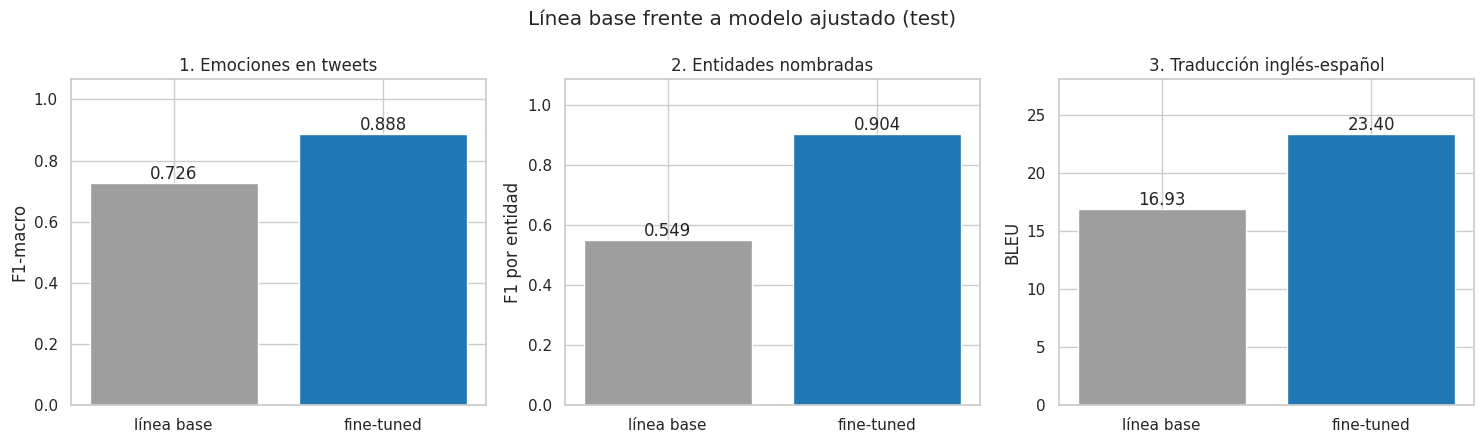

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (clave, (problema, _, _, _, metrica, k_ft, k_base, fmt)) in zip(axes, PROBLEMAS.items()):
    r = resultados[clave]
    valores = [r[k_base], r[k_ft]]
    barras = ax.bar(["línea base", "fine-tuned"], valores, color=["#9e9e9e", "#1f77b4"])
    for barra, v in zip(barras, valores):
        ax.text(barra.get_x() + barra.get_width() / 2, v, fmt.format(v), ha="center", va="bottom")
    ax.set_title(problema)
    ax.set_ylabel(metrica)
    ax.set_ylim(0, max(valores) * 1.2)
plt.suptitle("Línea base frente a modelo ajustado (test)")
plt.tight_layout(); plt.show()

### 5.2 Los tres modelos sobre las mismas frases

Se cargan los tres modelos desde sus carpetas guardadas y se aplican a las mismas frases nuevas. Así se ve que cada uno resuelve una tarea distinta sobre el mismo texto: el primero detecta la emoción, el segundo las entidades y el tercero traduce.

En el etiquetador de entidades se usa `aggregation_strategy="first"`, que toma la etiqueta del primer sub-token de cada palabra, igual que en el entrenamiento. Así se evita el problema que se vio con "Elon Musk" en la demostración del problema 2.

In [34]:
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
DIRS_MEJORES = {clave: os.path.join(BASE_DIR, clave, "mejor_modelo") for clave in PROBLEMAS}

clasificador_final = pipeline("text-classification", model=DIRS_MEJORES["p1_emotion"], device=DISPOSITIVO)
etiquetador_final = pipeline("token-classification", model=DIRS_MEJORES["p2_ner"],
                             aggregation_strategy="first", device=DISPOSITIVO)
tokenizador_traductor = AutoTokenizer.from_pretrained(DIRS_MEJORES["p3_traduccion"])
traductor_final = AutoModelForSeq2SeqLM.from_pretrained(DIRS_MEJORES["p3_traduccion"]).to(DISPOSITIVO).eval()

def traducir_final(textos):
    entradas = tokenizador_traductor(textos, return_tensors="pt", padding=True, truncation=True).to(DISPOSITIVO)
    with torch.no_grad():
        salidas = traductor_final.generate(**entradas, num_beams=4, max_new_tokens=128)
    return tokenizador_traductor.batch_decode(salidas, skip_special_tokens=True)

def tamano_mb(ruta):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, archivos in os.walk(ruta) for f in archivos) / 1024**2

modelos = {"p1_emotion": clasificador_final.model, "p2_ner": etiquetador_final.model, "p3_traduccion": traductor_final}
display(pd.DataFrame([{
    "problema": PROBLEMAS[clave][0],
    "carpeta": DIRS_MEJORES[clave],
    "parámetros (millones)": round(modelo.num_parameters() / 1e6, 1),
    "tamaño en disco (MB)": round(tamano_mb(DIRS_MEJORES[clave])),
} for clave, modelo in modelos.items()]).set_index("problema"))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

,carpeta,parámetros (millones),tamaño en disco (MB)
problema,,,
1. Emociones en tweets,/content/drive/MyDrive/NLP_Proyecto2/p1_emotion/mejor_modelo,109.5,418
2. Entidades nombradas,/content/drive/MyDrive/NLP_Proyecto2/p2_ner/mejor_modelo,107.7,412
3. Traducción inglés-español,/content/drive/MyDrive/NLP_Proyecto2/p3_traduccion/mejor_modelo,77.9,299


In [35]:
frases_finales = [
    "I am so happy that Lionel Messi is coming to play in Medellin next month.",
    "I feel terrible after reading the news about the floods in Antioquia.",
    "Sherlock Holmes was furious when Inspector Lestrade ignored his advice in London.",
    "I was scared when the plane from Bogota to Madrid started shaking.",
    "I can't believe the University of Antioquia gave me a scholarship!",
]

emociones = clasificador_final(frases_finales)
entidades = etiquetador_final(frases_finales)
traducciones = traducir_final(frases_finales)

display(pd.DataFrame({
    "frase": frases_finales,
    "emoción (problema 1)": [f"{e['label']} ({e['score']:.0%})" for e in emociones],
    "entidades (problema 2)": [", ".join(f"{e['word']} ({e['entity_group']})" for e in ents) or "(ninguna)"
                               for ents in entidades],
    "traducción (problema 3)": traducciones,
}))

,frase,emoción (problema 1),entidades (problema 2),traducción (problema 3)
0,I am so happy that Lionel Messi is coming to play in Medellin next month.,joy (100%),"Lionel Messi (PER), Medellin (LOC)",Estoy tan contenta de que Lionel Messi venga a jugar a Médelin el mes próximo.
1,I feel terrible after reading the news about the floods in Antioquia.,sadness (100%),Antioquia (LOC),Me siento terrible después de haber leído las noticias de las inundaciones de Antioquia.
2,Sherlock Holmes was furious when Inspector Lestrade ignored his advice in London.,anger (100%),"Sherlock Holmes (PER), Inspector Lestrade (PER), London (LOC)",Sherlock Holmes se enfureció cuando el inspector Lestrade ignoró su consejo en Londres.
3,I was scared when the plane from Bogota to Madrid started shaking.,fear (100%),"Bogota (LOC), Madrid (LOC)",Me asusté cuando el vuelo de Bogota a Madrid se estremeció.
4,I can't believe the University of Antioquia gave me a scholarship!,joy (98%),University of Antioquia (ORG),¡No puedo creer que la Universidad de Antioquia me diera una beca!


### 5.3 Conclusiones generales

1. El fine-tuning mejoró a la línea base en los tres problemas: el F1-macro de emociones pasó de 0.726 a 0.888, el F1 de entidades de 0.549 a 0.904 y el BLEU de traducción de 16.93 a 23.40. En emociones y entidades los errores se redujeron en cerca de 60 % y 80 %.
2. La mejora fue mayor cuando el modelo aprendía una tarea nueva. En los problemas 1 y 2 BERT solo sabía modelar el lenguaje y se le agregó una capa de clasificación que empezó desde cero. En el problema 3 el modelo ya traducía, así que el fine-tuning solo lo adaptó al estilo de la literatura clásica.
3. El learning rate fue el hiperparámetro más importante en los tres casos. Los valores entre 3e-5 y 1e-4 dieron resultados parecidos, mientras que 1e-5 aprendió demasiado lento. El batch size influyó poco.
4. El costo fue bajo: los tres entrenamientos finales tomaron menos de una hora en total en una GPU T4 gratuita de Colab. Partir de un modelo preentrenado evita entrenar desde cero con millones de ejemplos.
5. Cada tarea necesita su propia métrica. La accuracy esconde los errores en las clases pequeñas, por eso se usó F1-macro. En NER se mide por entidad completa con seqeval, y en traducción se usaron BLEU y chrF, que comparan contra una sola traducción de referencia.
6. La calidad de los datos fue un límite común. Las etiquetas por hashtags del problema 1, los errores de anotación del problema 2 y los pares mal alineados del problema 3 explican parte de los errores que quedan.
7. Los tres modelos funcionan bien dentro de su dominio y fallan fuera de él: el de emociones con las negaciones, el de entidades con el texto en minúsculas y el traductor con los términos técnicos y modernos. Antes de usar un modelo ajustado en otro contexto hay que evaluarlo con datos de ese contexto.

### 5.4 Referencias

**Hugging Face**

- Curso de Hugging Face, capítulo de fine-tuning: https://huggingface.co/learn/llm-course/chapter3

**Datasets**

- https://huggingface.co/datasets/dair-ai/emotion
- https://huggingface.co/datasets/eriktks/conll2003
- https://huggingface.co/datasets/Helsinki-NLP/opus_books

**Métricas**

- Papineni, K., Roukos, S., Ward, T. y Zhu, W.-J. (2002). BLEU: a Method for Automatic Evaluation of Machine Translation. ACL 2002. https://aclanthology.org/P02-1040/
- Popović, M. (2015). chrF: character n-gram F-score for automatic MT evaluation. WMT 2015. https://aclanthology.org/W15-3049/
- Post, M. (2018). A Call for Clarity in Reporting BLEU Scores. WMT 2018 (sacrebleu). https://aclanthology.org/W18-6319/
- Nakayama, H. (2018). seqeval: A Python framework for sequence labeling evaluation. https://github.com/chakki-works/seqeval